# EV CAN-bus attack detection with ANFIS

**Soft Computing AAT (Hybrid Systems): Sam M Jacob**

Reproduction and extension of O. A. Al Isawi, K. A. Al Jaafari, A. S. Al-Sumaiti, *Electric Vehicles CAN Bus Cyber Attacks Detection Using Adaptive Neuro Fuzzy Inference System*, IEEE Access 13 (2025).

Research questions:
1. **Non-hybrid vs hybrid:** MLP (neural), FCM classifier (fuzzy) and LDA/LR/SVM/RF vs ANFIS (neuro-fuzzy), unstacked and with the paper's stacking ANFIS.
2. **Initialisation:** Random vs K-Means vs Subtractive Clustering vs Fuzzy C-Means for building the initial ANFIS.

**How this notebook is organised.** Sections 2–8 contain *all* of the project's source code. Each cell writes one file (`%%writefile`), so running them recreates the package exactly as in the repository. Sections 9–13 then run it: unit tests, data analysis, a one-seed demo experiment, the results of the full 5-seed study, and the Setting B probe.

**Running it (Colab or local).** Run all cells in order. The setup cell:
1. installs `scikit-fuzzy` and `imbalanced-learn` if they are missing;
2. if it is not already inside the project, clones the repository (github.com/SamMJacob/SCN_AAT) for the saved results of the full study;
3. finds the OTIDS data. On Colab it mounts Google Drive and looks in `DATA_DIR` (default `MyDrive/OTIDS`) for the four `.txt` logs *or* the original HCRL zip.

**Data.** The OTIDS CAN-intrusion dataset (HCRL, Korea University) must be downloaded manually (https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset) and put in Google Drive (Colab) or `data/raw/` (local). Without it, the code, unit tests and saved results still run; the data-dependent cells are skipped with a message.

**Runtime.** Setup, tests, data analysis and the demo take about 5 minutes on Colab (CPU is enough). The full grid (`RUN_FULL = True`) takes about 70 minutes on a 20-core CPU + GPU, and several hours on a Colab CPU runtime; use *Runtime → Change runtime type → GPU* for the ANFIS parts.

## 1. Setup

In [1]:
import os, sys, platform, subprocess, zipfile
from pathlib import Path

# ---- options --------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/OTIDS'   # Colab: folder in Google Drive with the OTIDS .txt logs or zip
REPO_URL = 'https://github.com/SamMJacob/SCN_AAT.git'
RUN_FULL = False                            # True = re-run the full 5-seed grid and all ablations
# ---------------------------------------------------------------------------------------------

IN_COLAB = 'google.colab' in sys.modules
LOGS = ['DoS_attack_dataset.txt', 'Fuzzy_attack_dataset.txt', 'Impersonation_attack_dataset.txt',
        'Attack_free_dataset.txt']

def sh(*cmd):  # run a command and stream its output into the notebook
    p = subprocess.Popen([str(c) for c in cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end='')
    if p.wait():
        raise RuntimeError(f'command failed ({p.returncode}): {cmd}')

# 1. packages missing from Colab
for mod, pkg in [('skfuzzy', 'scikit-fuzzy'), ('imblearn', 'imbalanced-learn'), ('yaml', 'pyyaml'),
                 ('pyarrow', 'pyarrow'), ('pytest', 'pytest')]:
    try:
        __import__(mod)
    except ImportError:
        sh(sys.executable, '-m', 'pip', 'install', '-q', pkg)

# 2. project folder: use the current one if it is the project, else clone the repository
if not (Path.cwd() / 'results' / 'metrics_long.csv').exists():
    target = Path('/content/SCN_AAT') if IN_COLAB else Path.cwd() / 'SCN_AAT'
    if not (target / 'results' / 'metrics_long.csv').exists():
        sh('git', 'clone', '-q', '--depth', '1', REPO_URL, target)
    os.chdir(target)
ROOT = Path.cwd()
for d in ['configs', 'src/data', 'src/models', 'src/eval', 'scripts', 'tests', 'results/figures',
          'data/raw', 'data/processed']:
    (ROOT / d).mkdir(parents=True, exist_ok=True)
for f in ['src/data/__init__.py', 'src/models/__init__.py', 'src/eval/__init__.py',
          'scripts/__init__.py', 'tests/__init__.py']:
    (ROOT / f).touch()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# 3. OTIDS data -> data/raw (link the .txt logs, or extract them from the HCRL zip)
raw = ROOT / 'data' / 'raw'
if IN_COLAB and not all((raw / f).exists() for f in LOGS):
    from google.colab import drive
    drive.mount('/content/drive')
src_dir = Path(DATA_DIR)
for f in LOGS:
    if not (raw / f).exists() and (src_dir / f).exists():
        (raw / f).symlink_to(src_dir / f)
if not all((raw / f).exists() for f in LOGS):
    for z in list(src_dir.glob('*.zip')) + list(raw.glob('*.zip')):
        with zipfile.ZipFile(z) as zf:
            for name in zf.namelist():
                if Path(name).name in LOGS and not (raw / Path(name).name).exists():
                    with zf.open(name) as a, open(raw / Path(name).name, 'wb') as b:
                        b.write(a.read())
HAVE_DATA = all((raw / f).exists() for f in LOGS)

import torch, sklearn, numpy, pandas
print('project folder:', ROOT)
print('Python', platform.python_version(), '| torch', torch.__version__, '| sklearn', sklearn.__version__,
      '| CUDA:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'not available')
print('OTIDS data found:', HAVE_DATA, '' if HAVE_DATA else
      f'-> put the four logs (or the HCRL zip) in {DATA_DIR} and re-run this cell; data cells will be skipped')

project folder: /home/sammj/scn
Python 3.11.17 | torch 2.6.0+cu124 | sklearn 1.9.1 | CUDA: NVIDIA GeForce RTX 4060 Laptop GPU
OTIDS data found: True 


## 2. Configuration

All hyperparameters, seeds, sample sizes and the four settings. The paper's values are the defaults.

In [2]:
%%writefile configs/default.yaml
# All hyperparameters, seeds and settings. Paper values are the defaults.
seeds: [0, 1, 2, 3, 4]

sample:
  totals: {dos: 1497, imp: 979, normal: 17524}   # paper: 20,000 rows
  test_frac: 0.20
  val_frac: 0.20          # of training, carved before SMOTE, used for tuning only
  t_attack: 250.0         # HCRL: attacks start at t0 + 250 s

smote:
  enabled: true
  k_neighbors: 30
  sampling_strategy: not majority

settings:
  A:       {labels: id,        features: [can_id, dlc, d0, d1, d2, d3, d4, d5, d6, d7]}
  A-noID:  {labels: id,        features: [dlc, d0, d1, d2, d3, d4, d5, d6, d7, log_dt]}
  B:       {labels: corrected, features: [dlc, d0, d1, d2, d3, d4, d5, d6, d7, log_dt]}
  B-ID:    {labels: corrected, features: [can_id, dlc, d0, d1, d2, d3, d4, d5, d6, d7, log_dt]}

anfis:
  epochs: 1               # paper
  epochs_long: 5          # ablation, early stopping on validation
  lr: 0.01
  batch_size: 512
  ridge: 1.0e-6
  sigma_min: 1.0e-3
  n_rules: 10             # Random / KMeans
  sc:
    binary: {radius: 0.20, squash: 0.20, accept: 0.5, reject: 0.15}
    multi:  {radius: 0.25, squash: 0.25, accept: 0.5, reject: 0.15}
    squash_fallback: 1.25
    max_points: 5000
  fcm: {n_clusters: 10, m: 2.0, maxiter: 100, error: 1.0e-5, sigma_floor: 1.0e-2}
  kmeans: {n_clusters: 10, n_init: 10, sigma_floor: 1.0e-2, sweep: [5, 10, 20]}
  stack_mode: paper       # paper | oof
  oof_folds: 5

baselines:
  mlp: {hidden: [[32], [64], [64, 32]], max_epochs: 50, lr: 0.001}
  fcm_clf: {k: [10, 20, 30], m: 2.0}
  svm_rbf: {C: [1, 10]}
  rf: {n_estimators: 200, max_depth: [null, 20]}
  lr: {C: [0.1, 1, 10]}


Overwriting configs/default.yaml


## 3. Data pipeline

- `parse_otids.py`: regex parser for the OTIDS logs (remote frames → bytes −1), parquet cache.
- `features.py`: per-frame temporal features (`dt_same_id`, `hamming_prev`) on the full chronological log, before any sampling.
- `build_dataset.py`: label pools for settings A / A-noID / B / B-ID, the 20,000-frame sample per seed, the stratified 80/20 split, the validation split, and train-only min-max scaling + SMOTE.

In [3]:
%%writefile src/__init__.py
"""Cap native thread pools before numpy/torch/sklearn start them.

With 20 cores, sklearn's OpenMP, joblib (RF n_jobs) and torch's OpenMP pool otherwise
oversubscribe the CPU and can spin indefinitely (observed: RF fit hanging at ~1500% CPU).
"""
import os

for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "8")


Overwriting src/__init__.py


In [4]:
%%writefile src/data/parse_otids.py
"""Parser for the OTIDS (HCRL CAN-intrusion) text logs.

Line format (verified on the raw files):
    Timestamp:   0.000224    ID: 0329    000    DLC: 8    d7 a7 7f 8c 11 2f 00 10
The field after the ID is a flag; ``100`` marks a remote frame (DLC 0, no bytes).
A couple of Fuzzy-log lines carry a trailing quoted ASCII column, which is ignored.
"""
from __future__ import annotations

import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[2]
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"

FILES = {
    "dos": "DoS_attack_dataset.txt",
    "fuzzy": "Fuzzy_attack_dataset.txt",
    "impersonation": "Impersonation_attack_dataset.txt",
    "attack_free": "Attack_free_dataset.txt",
}

BYTE_COLS = [f"d{i}" for i in range(8)]

LINE_RE = re.compile(
    r"Timestamp:\s*(?P<ts>\d+(?:\.\d+)?)\s+"
    r"ID:\s*(?P<id>[0-9a-fA-F]+)\s+"
    r"(?P<flag>[0-9a-fA-F]+)\s+"
    r"DLC:\s*(?P<dlc>\d+)"
    r"(?P<data>(?:\s+[0-9a-fA-F]{2})*)"
)

DOWNLOAD_HELP = """
OTIDS raw files not found in {raw}.

Download the 'CAN-intrusion-dataset (OTIDS)' manually from
  https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset
  (or IEEE DataPort, DOI 10.21227/sy7h-9057)
and place these files in data/raw/:
  {files}
"""


def parse_line(line: str):
    """Parse one log line -> (timestamp, can_id, remote, dlc, [d0..d7]) or None."""
    m = LINE_RE.search(line)
    if m is None:
        return None
    dlc = int(m.group("dlc"))
    data = [int(b, 16) for b in m.group("data").split()][:8]
    remote = int(m.group("flag"), 16) != 0
    data = data[:dlc] if not remote else []
    data = data + [-1] * (8 - len(data))
    return float(m.group("ts")), int(m.group("id"), 16), remote, dlc, data


def parse_file(path: Path, source: str) -> pd.DataFrame:
    rows, bad = [], 0
    with open(path, "r", errors="replace") as fh:
        for line in fh:
            if not line.strip():
                continue
            r = parse_line(line)
            if r is None:
                bad += 1
                continue
            ts, cid, remote, dlc, data = r
            rows.append((ts, cid, remote, dlc, *data))
    df = pd.DataFrame(rows, columns=["timestamp", "can_id", "remote", "dlc", *BYTE_COLS])
    df["can_id"] = df["can_id"].astype(np.int32)
    df["dlc"] = df["dlc"].astype(np.int8)
    df[BYTE_COLS] = df[BYTE_COLS].astype(np.int16)
    df["t_rel"] = df["timestamp"] - df["timestamp"].iloc[0]
    df["source_file"] = source
    df.attrs["unparsed_lines"] = bad
    return df


def check_raw_files() -> None:
    missing = [f for f in FILES.values() if not (RAW_DIR / f).exists()]
    if missing:
        print(DOWNLOAD_HELP.format(raw=RAW_DIR, files="\n  ".join(FILES.values())))
        sys.exit(1)


def load(source: str, force: bool = False) -> pd.DataFrame:
    """Load one parsed log, using the parquet cache when present."""
    PROC_DIR.mkdir(parents=True, exist_ok=True)
    cache = PROC_DIR / f"{source}.parquet"
    if cache.exists() and not force:
        return pd.read_parquet(cache)
    check_raw_files()
    df = parse_file(RAW_DIR / FILES[source], source)
    df.to_parquet(cache, index=False)
    return df


def main() -> None:
    check_raw_files()
    for source, fname in FILES.items():
        print(f"== {fname}: first lines")
        with open(RAW_DIR / fname) as fh:
            for _, line in zip(range(5), fh):
                print("   ", line.rstrip())
        df = load(source, force=True)
        print(f"   parsed {len(df):,} rows, unparsed lines: {df.attrs.get('unparsed_lines', 0)}")


if __name__ == "__main__":
    main()


Overwriting src/data/parse_otids.py


In [5]:
%%writefile src/data/features.py
"""Per-frame features computed on the full chronological log (before any subsampling)."""
from __future__ import annotations

import numpy as np
import pandas as pd

from .parse_otids import BYTE_COLS

_POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.int16)


def add_temporal_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add ``dt_same_id`` (s since previous frame with the same CAN ID) and
    ``hamming_prev`` (bit flips vs. the previous payload of the same ID).

    The first frame of each ID has no predecessor; its dt is filled with that
    ID's median dt (or 1 s if the ID occurs once) and its Hamming distance with 0.
    """
    df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
    g = df.groupby("can_id", sort=False)

    dt = g["timestamp"].diff()
    med = dt.groupby(df["can_id"]).transform("median")
    df["dt_same_id"] = dt.fillna(med).fillna(1.0).astype(np.float64)

    payload = df[BYTE_COLS].to_numpy().clip(min=0).astype(np.int16)  # missing bytes -> 0
    prev = g[BYTE_COLS].shift(1).to_numpy()
    has_prev = ~np.isnan(prev[:, 0])
    prev = np.nan_to_num(prev, nan=0).clip(min=0).astype(np.int16)
    ham = _POPCOUNT[np.bitwise_xor(payload, prev)].sum(axis=1)
    df["hamming_prev"] = np.where(has_prev, ham, 0).astype(np.int16)
    return df


Overwriting src/data/features.py


In [6]:
%%writefile src/data/build_dataset.py
"""Build the 20k-row datasets for each setting and the train/test preprocessing.

Labels (multiclass): 0 = DoS, 1 = Impersonation, 2 = Normal.
Binary: 0 = Attack (DoS + Imp), 1 = Normal (paper's one-hot order).

Pools
-----
A / A-noID (paper labels, by CAN ID):
    DoS    = 0x000 frames of the DoS log
    Imp    = 0x164 frames of the impersonation log (any time)
    Normal = attack-free log frames with ID not in {0x000, 0x164}
B / B-ID (corrected labels):
    DoS    = 0x000 frames of the DoS log
    Imp    = 0x164 frames of the impersonation log with t_rel >= 250 s
    Normal = impersonation-log frames with t_rel < 250 s (all IDs, incl. genuine 0x164)
             plus non-0x164 frames with t_rel >= 250 s
    Normal is drawn from the same session as Imp, so a classifier cannot separate
    Imp from genuine 0x164 by recording-session differences.
"""
from __future__ import annotations

from dataclasses import dataclass, field
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from .features import add_temporal_features
from .parse_otids import load

ROOT = Path(__file__).resolve().parents[2]
CLASS_NAMES = {"multi": ["DoS", "Imp", "Normal"], "binary": ["Attack", "Normal"]}
DOS_ID, IMP_ID = 0x000, 0x164


def load_config(path: Path | str | None = None) -> dict:
    with open(path or ROOT / "configs" / "default.yaml") as fh:
        return yaml.safe_load(fh)


@lru_cache(maxsize=None)
def _log(source: str) -> pd.DataFrame:
    df = add_temporal_features(load(source))
    df["log_dt"] = np.log10(df["dt_same_id"].clip(lower=1e-6))
    return df


@lru_cache(maxsize=None)
def build_pool(labels: str, t_attack: float = 250.0) -> pd.DataFrame:
    """All candidate frames with a ``label`` column (0/1/2)."""
    dos, imp = _log("dos"), _log("impersonation")
    p_dos = dos[dos.can_id == DOS_ID]
    if labels == "id":
        af = _log("attack_free")
        p_imp = imp[imp.can_id == IMP_ID]
        p_norm = af[~af.can_id.isin([DOS_ID, IMP_ID])]
    elif labels == "corrected":
        is164, late = imp.can_id == IMP_ID, imp.t_rel >= t_attack
        p_imp = imp[is164 & late]
        p_norm = imp[~(is164 & late)]
    else:
        raise ValueError(labels)
    parts = [p_dos.assign(label=0), p_imp.assign(label=1), p_norm.assign(label=2)]
    return pd.concat(parts, ignore_index=True)


def sample_dataset(setting: str, seed: int, cfg: dict) -> pd.DataFrame:
    """Draw exactly the paper's class totals from the setting's pool."""
    s = cfg["settings"][setting]
    pool = build_pool(s["labels"], cfg["sample"]["t_attack"])
    rng = np.random.default_rng(seed)
    totals = cfg["sample"]["totals"]
    out = []
    for lab, n in zip([0, 1, 2], [totals["dos"], totals["imp"], totals["normal"]]):
        idx = np.flatnonzero(pool.label.to_numpy() == lab)
        out.append(pool.iloc[rng.choice(idx, size=n, replace=False)])
    return pd.concat(out, ignore_index=True)


def to_task(y_multi: np.ndarray, task: str) -> np.ndarray:
    return (y_multi == 2).astype(int) if task == "binary" else y_multi.astype(int)


@dataclass
class Split:
    setting: str
    task: str
    seed: int
    features: list
    X_train: np.ndarray       # raw (unscaled), before SMOTE
    y_train: np.ndarray
    X_test: np.ndarray
    y_test: np.ndarray
    class_names: list = field(default_factory=list)


def make_split(setting: str, task: str, seed: int, cfg: dict) -> Split:
    df = sample_dataset(setting, seed, cfg)
    feats = cfg["settings"][setting]["features"]
    X = df[feats].to_numpy(dtype=np.float64)
    y = to_task(df["label"].to_numpy(), task)
    # stratify on the multiclass label so both tasks share the same rows per seed
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=cfg["sample"]["test_frac"], random_state=seed,
        stratify=df["label"].to_numpy())
    return Split(setting, task, seed, feats, Xtr, ytr, Xte, yte, CLASS_NAMES[task])


def val_split(X, y, seed: int, cfg: dict):
    """Validation split carved from (raw) training data, for tuning only."""
    return train_test_split(X, y, test_size=cfg["sample"]["val_frac"],
                            random_state=seed + 1000, stratify=y)


def preprocess(X_train, y_train, X_eval_list, seed: int, cfg: dict, smote: bool | None = None,
               log=print):
    """Fit min-max on training only, transform eval sets, then SMOTE training only.

    Returns (X_train_res, y_train_res, [X_eval_scaled...], scaler).
    """
    scaler = MinMaxScaler().fit(X_train)
    Xtr = scaler.transform(X_train)
    Xev = [scaler.transform(X) for X in X_eval_list]
    use_smote = cfg["smote"]["enabled"] if smote is None else smote
    ytr = np.asarray(y_train)
    if use_smote:
        counts = np.bincount(ytr)
        minority = counts[counts > 0].min()
        k = cfg["smote"]["k_neighbors"]
        if minority <= k:
            k = max(1, minority - 1)
            log(f"[smote] smallest class has {minority} samples; k_neighbors reduced to {k}")
        sm = SMOTE(k_neighbors=k, sampling_strategy=cfg["smote"]["sampling_strategy"],
                   random_state=seed)
        Xtr, ytr = sm.fit_resample(Xtr, ytr)
    return Xtr, ytr, Xev, scaler


Overwriting src/data/build_dataset.py


## 4. Models

### 4.1 ANFIS (hybrid neuro-fuzzy)

First-order Takagi–Sugeno ANFIS written from scratch in PyTorch. Gaussian membership functions, log-space firing strengths, and Jang's hybrid learning: ridge least squares for the consequents, one Adam pass on centres and widths per epoch.

In [7]:
%%writefile src/models/anfis.py
"""First-order Takagi-Sugeno ANFIS with hybrid learning, from scratch in PyTorch.

Each rule r has a Gaussian MF per input (center c_r, sigma s_r), as in MATLAB
genfis2/genfis3 cluster-based FIS. Firing strengths are computed in log space:
    log w_r = -sum_j (x_j - c_rj)^2 / (2 s_rj^2),   w_bar = softmax(log w)
Output: y = sum_r w_bar_r (a_r . x + b_r).

Hybrid learning, per epoch:
  1. premise fixed  -> consequents by ridge least squares on Phi = [w_bar_r x, w_bar_r]
  2. consequents fixed -> one Adam pass over mini-batches on centers and log-sigmas (MSE)
After the last epoch the consequents are re-solved once for the final premise.
"""
from __future__ import annotations

import copy
import warnings

import numpy as np
import torch
from torch import nn

torch.set_num_threads(4)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class ANFIS(nn.Module):
    def __init__(self, centers: np.ndarray, sigmas: np.ndarray, sigma_min: float = 1e-3):
        super().__init__()
        centers = np.asarray(centers, dtype=np.float64)
        sigmas = np.broadcast_to(np.asarray(sigmas, dtype=np.float64), centers.shape)
        self.R, self.d = centers.shape
        if self.R > 100:
            warnings.warn(f"ANFIS with {self.R} rules: Phi has {self.R * (self.d + 1)} columns")
        self.sigma_min = sigma_min
        self.centers = nn.Parameter(torch.tensor(centers, dtype=torch.float32))
        self.log_sigma = nn.Parameter(torch.tensor(np.log(np.maximum(sigmas, sigma_min)),
                                                   dtype=torch.float32))
        self.register_buffer("theta", torch.zeros(self.R * (self.d + 1), dtype=torch.float32))

    @property
    def sigmas(self) -> torch.Tensor:
        return self.log_sigma.exp().clamp_min(self.sigma_min)

    def norm_firing(self, x: torch.Tensor) -> torch.Tensor:
        z = (x[:, None, :] - self.centers[None]) / self.sigmas[None]
        return torch.softmax(-0.5 * (z ** 2).sum(-1), dim=1)          # [N, R]

    def design(self, x: torch.Tensor, wbar: torch.Tensor | None = None) -> torch.Tensor:
        """Phi = [w_bar_r * x, w_bar_r] flattened per rule -> [N, R*(d+1)]."""
        if wbar is None:
            wbar = self.norm_firing(x)
        xa = torch.cat([x, torch.ones_like(x[:, :1])], dim=1)           # [N, d+1]
        return (wbar[:, :, None] * xa[:, None, :]).reshape(len(x), -1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.design(x) @ self.theta

    # ---- hybrid learning steps ------------------------------------------------
    @torch.no_grad()
    def lse_step(self, x: torch.Tensor, y: torch.Tensor, ridge: float = 1e-6,
                 chunk: int = 8192) -> None:
        P = self.R * (self.d + 1)
        A = torch.zeros(P, P, dtype=torch.float64, device=x.device)
        b = torch.zeros(P, dtype=torch.float64, device=x.device)
        for i in range(0, len(x), chunk):
            phi = self.design(x[i:i + chunk]).double()
            A += phi.T @ phi
            b += phi.T @ y[i:i + chunk].double()
        A += ridge * torch.eye(P, dtype=torch.float64, device=x.device)
        self.theta.copy_(torch.linalg.solve(A, b).float())

    def gd_pass(self, x: torch.Tensor, y: torch.Tensor, opt: torch.optim.Optimizer,
                batch_size: int, gen: torch.Generator) -> None:
        perm = torch.randperm(len(x), generator=gen, device="cpu").to(x.device)
        for i in range(0, len(x), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = ((self(x[idx]) - y[idx]) ** 2).mean()
            loss.backward()
            opt.step()


def fit_anfis(centers, sigmas, X, y, epochs: int = 1, lr: float = 1e-2, batch_size: int = 512,
              ridge: float = 1e-6, sigma_min: float = 1e-3, X_val=None, y_val=None,
              patience: int = 2, seed: int = 0, device=DEVICE):
    """Train an ANFIS with the hybrid rule. Early stopping applies when X_val is given."""
    torch.manual_seed(seed)
    model = ANFIS(centers, sigmas, sigma_min).to(device)
    xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    yt = torch.as_tensor(y, dtype=torch.float32, device=device)
    has_val = X_val is not None
    if has_val:
        xv = torch.as_tensor(X_val, dtype=torch.float32, device=device)
        yv = torch.as_tensor(y_val, dtype=torch.float32, device=device)
    opt = torch.optim.Adam([model.centers, model.log_sigma], lr=lr)
    gen = torch.Generator().manual_seed(seed)
    model.init_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best, best_state, bad, history = np.inf, None, 0, []
    for ep in range(epochs):
        model.lse_step(xt, yt, ridge)
        model.gd_pass(xt, yt, opt, batch_size, gen)
        if has_val:
            model.lse_step(xt, yt, ridge)
            with torch.no_grad():
                v = float(((model(xv) - yv) ** 2).mean())
            history.append(v)
            if v < best - 1e-6:
                best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= patience:
                    break
    if has_val and best_state is not None:
        model.load_state_dict(best_state)
    else:
        model.lse_step(xt, yt, ridge)
    model.epochs_run = ep + 1
    model.val_history = history
    return model


@torch.no_grad()
def predict(model: ANFIS, X, batch: int = 65536) -> np.ndarray:
    dev = model.centers.device
    out = [model(torch.as_tensor(X[i:i + batch], dtype=torch.float32, device=dev)).cpu().numpy()
           for i in range(0, len(X), batch)]
    return np.concatenate(out) if out else np.zeros(0)


Overwriting src/models/anfis.py


### 4.2 Initial FIS: Random, K-Means, Subtractive Clustering, FCM

`subclust.py` implements Chiu's subtractive clustering with MATLAB `subclust` semantics. `inits.py` turns each clustering method into initial centres and widths behind one interface.

In [8]:
%%writefile src/models/subclust.py
"""Chiu's subtractive clustering, following MATLAB ``subclust`` semantics.

Data are normalised to the unit hypercube using the data bounds. Potentials use
alpha = 4 / r_a^2 and revisions use beta = 4 / r_b^2 with r_b = squash * r_a.
Cluster sigmas are r_a * (max - min) / sqrt(8) per dimension, as MATLAB returns.
"""
from __future__ import annotations

import numpy as np
from scipy.spatial.distance import cdist


def subclust(X: np.ndarray, radius: float, squash: float = 1.25, accept: float = 0.5,
             reject: float = 0.15, bounds: tuple | None = None, max_centers: int | None = None):
    """Return (centers [R, d], sigmas [d]) in the original data space."""
    X = np.asarray(X, dtype=np.float64)
    n, d = X.shape
    lo, hi = (X.min(axis=0), X.max(axis=0)) if bounds is None else map(np.asarray, bounds)
    span = np.where(hi - lo > 0, hi - lo, 1.0)
    Z = (X - lo) / span

    ra = np.full(d, radius, dtype=np.float64)
    rb = squash * ra
    Za = Z / ra                                     # alpha = 4 / ra^2 per dimension
    pot = np.exp(-4.0 * cdist(Za, Za, "sqeuclidean")).sum(axis=1)

    ref = pot.max()
    centers: list[np.ndarray] = []
    while True:
        k = int(np.argmax(pot))
        pk = pot[k]
        if pk <= reject * ref:
            break
        if pk <= accept * ref:                      # grey zone: accept only if far enough
            dmin = np.sqrt(np.min(np.sum(((Z[k] - np.array(centers)) / ra) ** 2, axis=1)))
            if dmin + pk / ref < 1.0:
                pot[k] = 0.0                        # reject this point, try the next highest
                if pot.max() <= 0:
                    break
                continue
        centers.append(Z[k].copy())
        # potential revision around the new center
        dz = np.sum(((Z - Z[k]) / rb) ** 2, axis=1)
        pot = pot - pk * np.exp(-4.0 * dz)
        pot[pot < 0] = 0.0
        if max_centers is not None and len(centers) >= max_centers:
            break
        if pot.max() <= 0:
            break

    C = np.array(centers) * span + lo
    sigmas = ra * span / np.sqrt(8.0)
    return C, sigmas


Overwriting src/models/subclust.py


In [9]:
%%writefile src/models/inits.py
"""Initial-FIS generators for ANFIS. All share one interface:

    init_fn(X_train, y=None, seed=0, **params) -> (centers [R, d], sigmas [R, d])
"""
from __future__ import annotations

import warnings

import numpy as np
import skfuzzy
from sklearn.cluster import KMeans

from .subclust import subclust


def _global_std(X, floor):
    return np.maximum(X.std(axis=0), floor)


def init_random(X, y=None, seed: int = 0, n_clusters: int = 10, sigma_floor: float = 1e-2, **_):
    """Control: R centers sampled uniformly from training points, sigma = global std."""
    rng = np.random.default_rng(seed)
    C = X[rng.choice(len(X), size=n_clusters, replace=False)]
    return C.copy(), np.tile(_global_std(X, sigma_floor), (n_clusters, 1))


def init_kmeans(X, y=None, seed: int = 0, n_clusters: int = 10, n_init: int = 10,
                sigma_floor: float = 1e-2, **_):
    """Hard clustering: each K-Means cluster becomes one rule."""
    km = KMeans(n_clusters=n_clusters, n_init=n_init, random_state=seed).fit(X)
    gstd = _global_std(X, sigma_floor)
    S = np.empty_like(km.cluster_centers_)
    for r in range(n_clusters):
        pts = X[km.labels_ == r]
        S[r] = np.maximum(pts.std(axis=0), sigma_floor) if len(pts) >= 2 else gstd
    return km.cluster_centers_.copy(), S


def init_fcm(X, y=None, seed: int = 0, n_clusters: int = 10, m: float = 2.0, maxiter: int = 100,
             error: float = 1e-5, sigma_floor: float = 1e-2, **_):
    """Fuzzy C-Means (genfis3-style): sigma = sqrt of u^m-weighted variance per cluster."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        C, U, *_ = skfuzzy.cluster.cmeans(X.T, c=n_clusters, m=m, error=error, maxiter=maxiter,
                                          seed=seed)
    W = U ** m                                                       # [R, N]
    var = (W[:, :, None] * (X[None] - C[:, None]) ** 2).sum(1) / W.sum(1, keepdims=True)
    return C, np.maximum(np.sqrt(var), sigma_floor)


def init_sc(X, y=None, seed: int = 0, radius: float = 0.25, squash: float = 1.25,
            accept: float = 0.5, reject: float = 0.15, max_points: int = 5000,
            sigma_floor: float = 1e-2, **_):
    """Subtractive clustering (genfis2-style) on a stratified subsample (SC is O(N^2))."""
    rng = np.random.default_rng(seed)
    if len(X) > max_points:
        if y is not None:
            classes = np.unique(y)
            per = max_points // len(classes)
            idx = np.concatenate([rng.choice(np.flatnonzero(y == c),
                                             size=min(per, int((y == c).sum())), replace=False)
                                  for c in classes])
        else:
            idx = rng.choice(len(X), size=max_points, replace=False)
        Xs = X[idx]
    else:
        Xs = X
    # bounds of the full training set, so radii are relative to the same [0, 1] box
    C, s = subclust(Xs, radius, squash, accept, reject, bounds=(X.min(0), X.max(0)))
    return C, np.tile(np.maximum(s, sigma_floor), (len(C), 1))


INIT_FNS = {"random": init_random, "kmeans": init_kmeans, "sc": init_sc, "fcm": init_fcm}


Overwriting src/models/inits.py


### 4.3 Classifier wrappers: OvR ANFIS and the stacking ANFIS

One ANFIS per class (one-vs-rest); the stacked variant adds a second ANFIS that takes the stage-1 scores and regresses the class index (the paper's augmented ANFIS).

In [10]:
%%writefile src/models/anfis_classifiers.py
"""ANFIS classifier wrappers following the paper's architecture.

OvRANFIS:     one ANFIS per class, MSE regression to the one-hot column; outputs are
              clipped to [0, 1] and used as class scores.
StackedANFIS: stage 1 = OvRANFIS; stage 2 = an augmented ANFIS that takes the stage-1
              score vector and regresses the integer class index (DoS=0, Imp=1, Normal=2;
              binary Attack=0, Normal=1), rounded and clipped. This is our reading of the
              paper's description ("output the class predictions").
              stack_mode="paper": stage 2 is trained on in-sample stage-1 outputs.
              stack_mode="oof":   stage 2 is trained on K-fold out-of-fold stage-1 outputs.

Initial FIS: like MATLAB genfis2/genfis3, clustering runs on the joint input-output
space [X, target] and the output coordinate is then dropped (cluster_space="xy").
"""
from __future__ import annotations

import time

import numpy as np
from sklearn.model_selection import StratifiedKFold

from .anfis import fit_anfis, predict
from .inits import INIT_FNS


class OvRANFIS:
    def __init__(self, init: str, init_params: dict | None = None, anfis_params: dict | None = None,
                 cluster_space: str = "xy", seed: int = 0):
        self.init, self.init_params = init, dict(init_params or {})
        self.anfis_params = dict(anfis_params or {})
        self.cluster_space, self.seed = cluster_space, seed

    def _init(self, X, t, y):
        fn = INIT_FNS[self.init]
        if self.cluster_space == "xy" and self.init != "random":
            Z = np.column_stack([X, t])
            C, S = fn(Z, y=y, seed=self.seed, **self.init_params)
            return C[:, :-1], S[:, :-1]
        return fn(X, y=y, seed=self.seed, **self.init_params)

    def fit(self, X, y, X_val=None, y_val=None):
        self.classes_ = np.unique(y)
        self.models_ = []
        epochs = self.anfis_params.get("epochs", 1)
        for i, c in enumerate(self.classes_):
            t = (y == c).astype(float)
            C, S = self._init(X, t, y)
            tv = None if X_val is None else (y_val == c).astype(float)
            params = dict(self.anfis_params,
                          epochs=epochs[i] if isinstance(epochs, (list, tuple)) else epochs)
            self.models_.append(fit_anfis(C, S, X, t, X_val=X_val, y_val=tv, seed=self.seed,
                                          **params))
        return self

    @property
    def n_rules(self) -> int:
        return int(sum(m.R for m in self.models_))

    @property
    def rules_per_member(self) -> list[int]:
        return [m.R for m in self.models_]

    def predict_scores(self, X):
        return np.column_stack([np.clip(predict(m, X), 0, 1) for m in self.models_])

    def predict(self, X):
        S = self.predict_scores(X)
        if len(self.classes_) == 2:          # binary: threshold 0.5 on P(Attack) (class 0)
            return np.where(S[:, 0] >= 0.5, self.classes_[0], self.classes_[1])
        return self.classes_[np.argmax(S, axis=1)]


class StackedANFIS:
    def __init__(self, init: str, init_params: dict | None = None, anfis_params: dict | None = None,
                 stack_init_params: dict | None = None, stack_mode: str = "paper",
                 oof_folds: int = 5, cluster_space: str = "xy", seed: int = 0):
        self.kw = dict(init=init, init_params=init_params, anfis_params=anfis_params,
                       cluster_space=cluster_space, seed=seed)
        self.stack_init_params = stack_init_params if stack_init_params is not None else init_params
        self.stack_mode, self.oof_folds, self.seed = stack_mode, oof_folds, seed

    def fit(self, X, y, X_val=None, y_val=None):
        t0 = time.perf_counter()
        self.stage1 = OvRANFIS(**self.kw).fit(X, y, X_val, y_val)
        self.stage1_time = time.perf_counter() - t0
        self.classes_ = self.stage1.classes_
        if self.stack_mode == "paper":
            S = self.stage1.predict_scores(X)
        elif self.stack_mode == "oof":
            S = np.zeros((len(X), len(self.classes_)))
            skf = StratifiedKFold(self.oof_folds, shuffle=True, random_state=self.seed)
            for tr, te in skf.split(X, y):
                S[te] = OvRANFIS(**self.kw).fit(X[tr], y[tr]).predict_scores(X[te])
        else:
            raise ValueError(self.stack_mode)
        kw2 = dict(self.kw, init_params=self.stack_init_params)
        self.stage2 = OvRANFIS(**kw2)
        t = np.searchsorted(self.classes_, y).astype(float)      # integer class index target
        C, S0 = self.stage2._init(S, t, y)
        self.stage2.classes_ = self.classes_
        p2 = dict(self.kw["anfis_params"] or {})
        if isinstance(p2.get("epochs"), (list, tuple)):     # per-member epochs -> use the max
            p2["epochs"] = max(p2["epochs"])
        self.stage2.models_ = [fit_anfis(C, S0, S, t, seed=self.seed, **p2)]
        return self

    @property
    def n_rules(self) -> int:
        return self.stage1.n_rules + self.stage2.n_rules

    def predict(self, X):
        S = self.stage1.predict_scores(X)
        out = predict(self.stage2.models_[0], S)
        idx = np.clip(np.rint(out), 0, len(self.classes_) - 1).astype(int)
        return self.classes_[idx]


Overwriting src/models/anfis_classifiers.py


### 4.4 Non-hybrid baselines

Pure fuzzy (FCM classifier: memberships + cluster class distributions, no learning), pure neural (MLP) and classical models (LDA, LR, linear/RBF SVM, Random Forest), with the small grids tuned on the validation split.

In [11]:
%%writefile src/models/fcm_classifier.py
"""N2: non-hybrid fuzzy classifier built only from FCM memberships (no gradient learning).

1. FCM on the training data (k clusters).
2. Each cluster gets a class distribution: membership-weighted class frequencies.
3. Prediction: membership-weighted vote over clusters.
"""
from __future__ import annotations

import warnings

import numpy as np
import skfuzzy


class FCMClassifier:
    def __init__(self, k: int = 10, m: float = 2.0, maxiter: int = 100, error: float = 1e-5,
                 seed: int = 0):
        self.k, self.m, self.maxiter, self.error, self.seed = k, m, maxiter, error, seed

    def fit(self, X, y):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.centers_, U, *_ = skfuzzy.cluster.cmeans(
                X.T, c=self.k, m=self.m, error=self.error, maxiter=self.maxiter, seed=self.seed)
        self.classes_ = np.unique(y)
        onehot = (y[:, None] == self.classes_[None]).astype(float)       # [N, C]
        dist = U @ onehot                                                 # [k, C]
        self.cluster_dist_ = dist / np.maximum(dist.sum(1, keepdims=True), 1e-12)
        self.n_rules = self.k
        return self

    def predict_scores(self, X):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            U, *_ = skfuzzy.cluster.cmeans_predict(
                X.T, self.centers_, self.m, error=self.error, maxiter=self.maxiter, seed=self.seed)
        return U.T @ self.cluster_dist_                                   # [N, C]

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_scores(X), axis=1)]


Overwriting src/models/fcm_classifier.py


In [12]:
%%writefile src/models/baselines.py
"""Non-hybrid baselines (N1 MLP, N2 FCM classifier, N3 classical ML) and their small tuning grids."""
from __future__ import annotations

import warnings

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC, LinearSVC

from .fcm_classifier import FCMClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)


def make_baseline(name: str, seed: int, **p):
    if name == "LDA":
        return LinearDiscriminantAnalysis()
    if name == "LR":
        return LogisticRegression(C=p.get("C", 1.0), max_iter=2000, random_state=seed)
    if name == "LinSVM":
        return LinearSVC(C=p.get("C", 1.0), max_iter=5000, random_state=seed)
    if name == "RBF-SVM":
        return SVC(C=p.get("C", 1.0), kernel="rbf", gamma="scale", random_state=seed)
    if name == "RF":
        return RandomForestClassifier(n_estimators=p.get("n_estimators", 200),
                                      max_depth=p.get("max_depth"), n_jobs=8, random_state=seed)
    if name == "MLP":
        return MLPClassifier(hidden_layer_sizes=tuple(p.get("hidden", (64,))),
                             learning_rate_init=p.get("lr", 1e-3), max_iter=p.get("max_epochs", 50),
                             early_stopping=True, n_iter_no_change=5, random_state=seed)
    if name == "FCM-clf":
        return FCMClassifier(k=p.get("k", 10), m=p.get("m", 2.0), seed=seed)
    raise KeyError(name)


def baseline_grid(name: str, cfg: dict) -> list[dict]:
    b = cfg["baselines"]
    return {
        "LDA": [{}],
        "LR": [{"C": c} for c in b["lr"]["C"]],
        "LinSVM": [{"C": c} for c in b["lr"]["C"]],
        "RBF-SVM": [{"C": c} for c in b["svm_rbf"]["C"]],
        "RF": [{"n_estimators": b["rf"]["n_estimators"], "max_depth": d} for d in b["rf"]["max_depth"]],
        "MLP": [{"hidden": h, "lr": b["mlp"]["lr"], "max_epochs": b["mlp"]["max_epochs"]}
                for h in b["mlp"]["hidden"]],
        "FCM-clf": [{"k": k, "m": b["fcm_clf"]["m"]} for k in b["fcm_clf"]["k"]],
    }[name]


Overwriting src/models/baselines.py


## 5. Evaluation

Per-run metrics (macro-F1 primary), the exact McNemar test, figure helpers, and the report generator that aggregates `results/metrics_long.csv` into summaries, paired comparisons, figures and `REPORT_NOTES.md`.

In [13]:
%%writefile src/eval/metrics.py
"""Per-run metrics. Primary metric: macro-F1."""
from __future__ import annotations

import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support


def compute_metrics(y_true, y_pred, class_names: list[str]) -> dict[str, float]:
    labels = list(range(len(class_names)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": float(np.mean(f)),
           "macro_precision": float(np.mean(p)), "macro_recall": float(np.mean(r))}
    n = cm.sum()
    rates = {"TPR": [], "TNR": [], "FPR": [], "FNR": []}
    for i, c in enumerate(class_names):
        tp = cm[i, i]
        fn = cm[i].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = n - tp - fn - fp
        vals = {"TPR": tp / max(tp + fn, 1), "TNR": tn / max(tn + fp, 1),
                "FPR": fp / max(fp + tn, 1), "FNR": fn / max(fn + tp, 1)}
        out.update({f"precision_{c}": p[i], f"recall_{c}": r[i], f"f1_{c}": f[i]})
        for k, v in vals.items():
            out[f"{k}_{c}"] = float(v)
            rates[k].append(v)
    out.update({f"{k}_macro": float(np.mean(v)) for k, v in rates.items()})
    return {k: float(v) for k, v in out.items()}


def confusion(y_true, y_pred, n_classes: int) -> np.ndarray:
    return confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))


Overwriting src/eval/metrics.py


In [14]:
%%writefile src/eval/stats.py
"""Significance testing."""
from __future__ import annotations

import numpy as np
from scipy.stats import binomtest


def mcnemar(y_true, pred_a, pred_b) -> dict:
    """Exact (binomial) McNemar test on paired predictions over the same test set."""
    a_ok = np.asarray(pred_a) == np.asarray(y_true)
    b_ok = np.asarray(pred_b) == np.asarray(y_true)
    n01 = int(np.sum(a_ok & ~b_ok))      # A right, B wrong
    n10 = int(np.sum(~a_ok & b_ok))      # A wrong, B right
    n = n01 + n10
    p = 1.0 if n == 0 else binomtest(n01, n, 0.5).pvalue
    return {"a_only_correct": n01, "b_only_correct": n10, "p_value": float(p)}


Overwriting src/eval/stats.py


In [15]:
%%writefile src/eval/plots.py
"""Static report figures (matplotlib, light mode).

Palette: first three categorical slots of the validated reference palette (they pass
all-pairs CVD checks). Identity is never colour-only: every bar carries an x label
and a direct value label.
"""
from __future__ import annotations

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXT, TEXT2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
FAMILY_COLOR = {"classical ML": AQUA, "non-hybrid soft computing": ORANGE, "hybrid (ANFIS)": BLUE}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "text.color": TEXT, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})


def family(model: str) -> str:
    if model.startswith("ANFIS"):
        return "hybrid (ANFIS)"
    if model in ("MLP", "FCM-clf"):
        return "non-hybrid soft computing"
    return "classical ML"


def _cap_ticks(ax, top=1.0):
    """Hide y ticks above 1.0 on score axes (headroom exists only for labels)."""
    ax.set_yticks([t for t in ax.get_yticks() if ax.get_ylim()[0] <= t <= top + 1e-9])


def _ylim_for(lo_vals):
    lo = float(np.nanmin(lo_vals))
    return (max(0.0, np.floor((lo - 0.02) * 20) / 20), 1.02)


def bar_with_err(ax, labels, means, stds, colors, ylabel, fmt="{:.3f}", ylim=None):
    x = np.arange(len(labels))
    ax.bar(x, means, width=0.62, color=colors, yerr=stds, capsize=2.5,
           error_kw=dict(ecolor=TEXT2, lw=0.8), edgecolor=SURFACE, linewidth=2)
    tops = np.asarray(means, float) + np.nan_to_num(np.asarray(stds, float))
    for xi, m, top in zip(x, means, tops):
        ax.annotate(fmt.format(m), (xi, top), ha="center", va="bottom", fontsize=7.5, color=TEXT,
                    xytext=(0, 3), textcoords="offset points")
    ax.set_xticks(x, labels, rotation=35, ha="right")
    ax.set_ylabel(ylabel)
    if ylim:
        ax.set_ylim(*ylim)
        _cap_ticks(ax)


def comparison1_chart(df, path, title):
    """df: index=model, columns mean/std of macro_f1 (ordered)."""
    fig, ax = plt.subplots(figsize=(7.5, 4.3))
    colors = [FAMILY_COLOR[family(m)] for m in df.index]
    bar_with_err(ax, df.index, df["mean"], df["std"], colors, "macro-F1 (test, mean ± std, 5 seeds)",
                 ylim=_ylim_for(df["mean"] - df["std"].fillna(0)))
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()]
    ax.legend(handles, FAMILY_COLOR.keys(), frameon=False, fontsize=8, ncol=3,
              loc="upper center", bbox_to_anchor=(0.5, -0.5))
    ax.set_title(title, loc="left")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def comparison2_chart(tab, path, title, primary_label):
    """tab: rows=init names; columns: f1, f1_std, f1_stk, f1_stk_std, cls, cls_std, cls_stk,
    cls_stk_std, rules, rules_stk, time, time_stk, (optional) f1_ep5, f1_ep5_std."""
    inits = list(tab.index)
    x = np.arange(len(inits))
    w = 0.38
    panels = [("macro-F1", "f1", "{:.3f}"), (primary_label, "cls", "{:.3f}"),
              ("rule count", "rules", "{:.0f}"), ("train time (s)", "time", "{:.1f}")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
    for ax, (lab, key, fmt) in zip(axes, panels):
        for off, suffix, color, name in [(-w / 2, "", BLUE, "OvR (unstacked)"),
                                         (w / 2, "_stk", ORANGE, "OvR + stacking ANFIS")]:
            vals = tab[key + suffix].to_numpy(float)
            err = tab.get(key + suffix + "_std")
            ax.bar(x + off, vals, w, color=color, label=name, edgecolor=SURFACE, linewidth=2,
                   yerr=None if err is None else err.to_numpy(float), capsize=2,
                   error_kw=dict(ecolor=TEXT2, lw=0.8))
            tops = vals + (0 if err is None else np.nan_to_num(err.to_numpy(float)))
            for xi, v, top in zip(x + off, vals, tops):
                ax.annotate(fmt.format(v), (xi, top), ha="center", va="bottom", fontsize=6.5,
                            rotation=90 if key in ("f1", "cls") else 0,
                            xytext=(0, 2), textcoords="offset points")
        ax.set_xticks(x, inits)
        ax.set_title(lab, loc="left", fontsize=10)
        if key in ("f1", "cls"):
            lo = np.nanmin(np.r_[tab[key].to_numpy(float), tab[key + "_stk"].to_numpy(float)])
            ax.set_ylim(_ylim_for([lo - 0.01])[0], 1.03)
            _cap_ticks(ax)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, fontsize=8, ncol=2, loc="lower center")
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.savefig(path, dpi=150)
    plt.close(fig)


def ladder_chart(data, path, title):
    """data: dict setting -> DataFrame(index=model in ladder order, mean, std)."""
    n = len(data)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.6), sharey=False)
    axes = np.atleast_1d(axes)
    for ax, (setting, df) in zip(axes, data.items()):
        colors = [FAMILY_COLOR[family(m)] for m in df.index]
        bar_with_err(ax, df.index, df["mean"], df["std"], colors,
                     "macro-F1" if ax is axes[0] else "",
                     ylim=_ylim_for(df["mean"] - df["std"].fillna(0)))
        ax.set_title(f"Setting {setting}", loc="left", fontsize=10)
    present = {family(m) for df in data.values() for m in df.index}
    fams = [f for f in FAMILY_COLOR if f in present]
    handles = [plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLOR[f]) for f in fams]
    fig.legend(handles, fams, frameon=False, fontsize=8, ncol=3, loc="lower center")
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(path, dpi=150)
    plt.close(fig)


def time_chart(df, path, title):
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    colors = [FAMILY_COLOR[family(m)] for m in df.index]
    bar_with_err(ax, df.index, df["mean"], df["std"], colors, "train time (s, log scale)",
                 fmt="{:.2g}")
    ax.set_yscale("log")
    ax.set_title(title, loc="left")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def confusion_pair(cms, names, class_names, path, title):
    fig, axes = plt.subplots(1, len(cms), figsize=(3.6 * len(cms), 3.4))
    for ax, cm, name in zip(np.atleast_1d(axes), cms, names):
        norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=9,
                        color="white" if norm[i, j] > 0.6 else TEXT)
        ax.set_xticks(range(len(class_names)), class_names)
        ax.set_yticks(range(len(class_names)), class_names)
        ax.set_xlabel("predicted")
        ax.set_ylabel("true")
        ax.grid(False)
        ax.set_title(name, loc="left", fontsize=10)
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def _gauss(x, c, s):
    return np.exp(-0.5 * ((x - c) / s) ** 2)


def mf_overlay(params_by_init, feature_idx, feature_name, member, path, title):
    """One panel per init: the member's MFs on one input, before (dashed) vs after training."""
    xs = np.linspace(-0.05, 1.05, 400)
    n = len(params_by_init)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.0), sharey=True)
    for ax, (init, p) in zip(np.atleast_1d(axes), params_by_init.items()):
        c0, s0 = p[f"m{member}_c0"][:, feature_idx], p[f"m{member}_s0"][:, feature_idx]
        c1, s1 = p[f"m{member}_c1"][:, feature_idx], p[f"m{member}_s1"][:, feature_idx]
        for r in range(len(c0)):
            ax.plot(xs, _gauss(xs, c0[r], s0[r]), color=TEXT2, lw=1, ls="--", alpha=0.6,
                    label="initial" if r == 0 else None)
            ax.plot(xs, _gauss(xs, c1[r], s1[r]), color=BLUE, lw=2,
                    label="after training" if r == 0 else None)
        ax.set_title(f"{init}  (R = {len(c0)})", loc="left", fontsize=10)
        ax.set_xlabel(f"{feature_name} (scaled)")
        ax.grid(False)
    np.atleast_1d(axes)[0].set_ylabel("membership")
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=7.5, loc="upper right")
    fig.suptitle(title, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


Overwriting src/eval/plots.py


In [16]:
%%writefile src/eval/report.py
"""Turn results/metrics_long.csv into summary / comparison tables, figures and REPORT_NOTES.md.

    python -m src.eval.report
"""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from . import plots
from .metrics import confusion
from .stats import mcnemar

ROOT = Path(__file__).resolve().parents[2]
RES = ROOT / "results"
FIG = RES / "figures"

NONHYBRID = ["MLP", "FCM-clf", "LDA", "LR", "LinSVM", "RBF-SVM", "RF"]
INITS = ["Random", "KMeans", "SC", "FCM"]
ANFIS = [f"ANFIS-{i}{s}" for i in INITS for s in ("", "+stk")]
LADDER = ["MLP", "FCM-clf", "ANFIS-Random", "ANFIS-KMeans", "ANFIS-SC", "ANFIS-FCM",
          "ANFIS-SC+stk", "ANFIS-FCM+stk"]
PAPER_HYBRID = "ANFIS-FCM+stk"       # pre-specified: the paper's best model / architecture
SETTINGS = ["A", "A-noID", "B", "B-ID"]
TASKS = ["binary", "multi"]
KEY_CLASS = {"binary": "Attack", "multi": "Imp"}
CLASSES = {"binary": ["Attack", "Normal"], "multi": ["DoS", "Imp", "Normal"]}

# Paper (Al Isawi et al. 2025), Tables 6 and 8 (by caption): accuracy, overall (macro) F1
PAPER = {
    "binary": {"LDA": (0.8593, 0.819), "LR": (0.9118, 0.866), "RBF-SVM": (0.9750, 0.951),
               "RF": (0.9928, 0.984), "ANFIS-SC+stk": (0.9958, 0.991),
               "ANFIS-FCM+stk": (0.9968, 0.993)},
    "multi": {"ANFIS-SC+stk": (0.9965, 0.988), "ANFIS-FCM+stk": (0.9968, 0.989),
              "CNN (paper only)": (0.8263, 0.497), "CNN-LSTM (paper only)": (0.8645, 0.459),
              "GRU (paper only)": (0.9950, 0.982), "LSTM (paper only)": (0.9955, 0.984)},
}
PAPER_IMP_F1 = {"ANFIS-SC+stk": 0.968, "ANFIS-FCM+stk": 0.968}


# ---------------------------------------------------------------------------
def load() -> tuple[pd.DataFrame, pd.DataFrame]:
    df = pd.read_csv(RES / "metrics_long.csv")
    params = df[df.metric == "params"]
    num = df[df.metric != "params"].copy()
    num["value"] = num["value"].astype(float)
    wide = num.pivot_table(index=["setting", "task", "model", "variant", "seed"],
                           columns="metric", values="value").reset_index()
    return wide, params


def agg(wide, setting, task, variant="main", models=None):
    d = wide[(wide.setting == setting) & (wide.task == task) & (wide.variant == variant)]
    if models is not None:
        d = d[d.model.isin(models)]
    g = d.drop(columns=["setting", "task", "variant", "seed"]).groupby("model")
    return g.mean(), g.std(), g.size()


def pm(m, s, fmt="{:.4f}"):
    if pd.isna(m):
        return "–"
    return fmt.format(m) + ("" if pd.isna(s) else " ± " + fmt.format(s))


def md(df: pd.DataFrame) -> str:
    cols = list(df.columns)
    out = ["| " + " | ".join([df.index.name or "model"] + cols) + " |", "|" + "---|" * (len(cols) + 1)]
    for i, r in df.iterrows():
        out.append("| " + " | ".join([str(i)] + [str(v) for v in r]) + " |")
    return "\n".join(out)


def paired_diff(wide, setting, task, a, b, metric="macro_f1", variant="main"):
    """Per-seed difference b - a on the same splits."""
    d = wide[(wide.setting == setting) & (wide.task == task) & (wide.variant == variant)]
    pa = d[d.model == a].set_index("seed")[metric]
    pb = d[d.model == b].set_index("seed")[metric]
    diff = (pb - pa).dropna()
    return diff


def verdict(diff: pd.Series, who: str = "hybrid") -> str:
    if len(diff) == 0:
        return "n/a"
    m, s = diff.mean(), diff.std(ddof=1) if len(diff) > 1 else np.nan
    wins = int((diff > 0).sum())
    ties = int((diff == 0).sum())
    # within noise: |mean| <= std across seeds, or below ~one minority-class test error (0.0025)
    if np.isnan(s) or abs(m) <= (s if s > 0 else 0) or abs(m) < 0.0025:
        tag = "within noise"
    else:
        tag = f"{who} better" if m > 0 else f"{who} worse"
    return f"{m:+.4f} ± {s:.4f} ({who} wins {wins}/{len(diff)} seeds, ties {ties}) → **{tag}**"


def load_preds(setting, task, model, seed=0, variant="main"):
    f = RES / "preds" / f"{setting}_{task}_{model}_{variant}_s{seed}.npz"
    if not f.exists():
        return None
    z = np.load(f)
    return z["y_true"], z["y_pred"]


# ---------------------------------------------------------------------------
def summary(wide, setting, task):
    mean, std, n = agg(wide, setting, task)
    if mean.empty:
        return None
    cls = CLASSES[task]
    order = mean.sort_values("macro_f1", ascending=False).index
    rows = {}
    for m in order:
        r = {"family": plots.family(m), "seeds": int(n[m]),
             "macro-F1": pm(mean.at[m, "macro_f1"], std.at[m, "macro_f1"]),
             "accuracy": pm(mean.at[m, "accuracy"], std.at[m, "accuracy"])}
        for c in cls:
            r[f"F1 {c}"] = pm(mean.at[m, f"f1_{c}"], std.at[m, f"f1_{c}"])
        r["FPR (macro)"] = pm(mean.at[m, "FPR_macro"], None)
        r["rules"] = "–" if pd.isna(mean.at[m, "n_rules"]) else f"{mean.at[m, 'n_rules']:.1f}"
        r["train s"] = f"{mean.at[m, 'train_time_s']:.2f}"
        r["infer ms/1k"] = f"{mean.at[m, 'infer_ms_per_1k']:.2f}"
        if setting == "A" and m in PAPER[task]:
            r["paper acc / F1"] = "{:.4f} / {:.3f}".format(*PAPER[task][m])
        elif setting == "A":
            r["paper acc / F1"] = "–"
        rows[m] = r
    t = pd.DataFrame(rows).T
    t.index.name = "model"
    if setting == "A":
        extra = {k: v for k, v in PAPER[task].items() if "paper only" in k}
        for k, (a, f) in extra.items():
            t.loc[k] = {c: "–" for c in t.columns} | {"family": "deep learning (not run)",
                                                     "paper acc / F1": f"{a:.4f} / {f:.3f}"}
    txt = [f"# Summary: Setting {setting}, {task}", "",
           "Test-set metrics, mean ± std over seeds (different subsample, split and SMOTE per seed). "
           "Sorted by macro-F1 (the primary metric). `+stk` = with the augmented stacking ANFIS.", ""]
    if setting == "A":
        txt += ["Paper columns: Al Isawi et al. (2025), Tables 6/8 (by caption). The paper's 'Overall F1' "
                "is the unweighted mean of per-class F1, i.e. macro-F1. The paper's ANFIS rows are the "
                "full stacked architecture, so they are matched to our `+stk` rows. The paper's SVM kernel "
                "is not stated; it is matched to RBF-SVM.", ""]
    txt.append(md(t))
    (RES / f"summary_{setting}_{task}.md").write_text("\n".join(txt) + "\n")
    return mean, std


def comparison1(wide, setting, task):
    mean, std, _ = agg(wide, setting, task)
    if mean.empty or PAPER_HYBRID not in mean.index:
        return None
    k = KEY_CLASS[task]
    nh = [m for m in NONHYBRID if m in mean.index]
    an = [m for m in ANFIS if m in mean.index]
    best_nh = mean.loc[nh, "macro_f1"].idxmax()
    best_h = mean.loc[an, "macro_f1"].idxmax()
    show = nh + [m for m in ["ANFIS-FCM", PAPER_HYBRID] if m in mean.index]
    if best_h not in show:
        show.append(best_h)
    rows = {}
    for m in show:
        label = m + (" (best ANFIS, post-hoc)" if m == best_h and m not in ("ANFIS-FCM", PAPER_HYBRID) else "")
        rows[label] = {"type": "hybrid" if m.startswith("ANFIS") else "non-hybrid",
                       "macro-F1": pm(mean.at[m, "macro_f1"], std.at[m, "macro_f1"]),
                       f"F1 {k}": pm(mean.at[m, f"f1_{k}"], std.at[m, f"f1_{k}"]),
                       "accuracy": pm(mean.at[m, "accuracy"], std.at[m, "accuracy"]),
                       "train s": f"{mean.at[m, 'train_time_s']:.2f}"}
    t = pd.DataFrame(rows).T
    t.index.name = "model"

    lines = [f"# Comparison 1: non-hybrid vs hybrid (Setting {setting}, {task})", "",
             "Non-hybrid: MLP (pure neural), FCM-clf (pure fuzzy, no learning), LDA/LR/LinSVM/RBF-SVM/RF "
             "(classical). Hybrid: ANFIS-FCM, the paper's best model, unstacked and stacked "
             f"(pre-specified, `{PAPER_HYBRID}` is the headline hybrid). The best of all 8 ANFIS rows is "
             "added when different, flagged as post-hoc (chosen on the test set).", "",
             md(t), "",
             "## Paired differences (macro-F1, per seed, same test sets)", ""]
    pairs = [(best_nh, PAPER_HYBRID, "best non-hybrid vs paper hybrid"),
             (best_nh, best_h, "best non-hybrid vs best ANFIS (post-hoc)"),
             ("MLP", PAPER_HYBRID, "pure neural (MLP) vs paper hybrid"),
             ("FCM-clf", PAPER_HYBRID, "pure fuzzy (FCM-clf) vs paper hybrid")]
    seen = set()
    for a, b, lab in pairs:
        if (a, b) in seen:
            continue
        seen.add((a, b))
        if a in mean.index and b in mean.index:
            lines.append(f"- {lab} ({a} → {b}): {verdict(paired_diff(wide, setting, task, a, b))}")
    lines.append("")
    lines += ["## McNemar test (seed 0)", ""]
    mc = {}
    for b in dict.fromkeys([PAPER_HYBRID, best_h]):
        pa, pb = load_preds(setting, task, best_nh), load_preds(setting, task, b)
        if pa is not None and pb is not None:
            r = mcnemar(pa[0], pa[1], pb[1])
            mc[b] = r
            lines.append(f"- {best_nh} vs {b}: only {best_nh} correct = {r['a_only_correct']}, "
                         f"only {b} correct = {r['b_only_correct']}, exact p = {r['p_value']:.3g}")
    lines += ["", f"Figure: `figures/comparison1_{setting}_{task}.png`"]
    (RES / f"comparison1_nonhybrid_vs_hybrid_{setting}_{task}.md").write_text("\n".join(lines) + "\n")

    chart = pd.DataFrame({"mean": mean.loc[show, "macro_f1"], "std": std.loc[show, "macro_f1"]})
    plots.comparison1_chart(chart, FIG / f"comparison1_{setting}_{task}.png",
                            f"Non-hybrid vs hybrid: Setting {setting}, {task}")
    return dict(best_nh=best_nh, best_h=best_h, mean=mean, std=std, mcnemar=mc)


def comparison2(wide, params, setting, task):
    mean, std, _ = agg(wide, setting, task)
    names = [f"ANFIS-{i}" for i in INITS]
    if not all(n in mean.index for n in names):
        return None
    k = KEY_CLASS[task]
    m5, s5, _ = agg(wide, setting, task, variant="ep5")
    tab = pd.DataFrame(index=INITS)
    for i in INITS:
        n = f"ANFIS-{i}"
        for suf, mm in (("", n), ("_stk", n + "+stk")):
            tab.at[i, "f1" + suf] = mean.at[mm, "macro_f1"]
            tab.at[i, "f1" + suf + "_std"] = std.at[mm, "macro_f1"]
            tab.at[i, "cls" + suf] = mean.at[mm, f"f1_{k}"]
            tab.at[i, "cls" + suf + "_std"] = std.at[mm, f"f1_{k}"]
            tab.at[i, "rules" + suf] = mean.at[mm, "n_rules"]
            tab.at[i, "time" + suf] = mean.at[mm, "train_time_s"]
            tab.at[i, "time" + suf + "_std"] = std.at[mm, "train_time_s"]
            if mm in m5.index:
                tab.at[i, "f1_ep5" + suf] = m5.at[mm, "macro_f1"]
                tab.at[i, "f1_ep5" + suf + "_std"] = s5.at[mm, "macro_f1"]

    rows = {}
    for i in INITS:
        r = {"macro-F1 (OvR)": pm(tab.at[i, "f1"], tab.at[i, "f1_std"]),
             "macro-F1 (+stk)": pm(tab.at[i, "f1_stk"], tab.at[i, "f1_stk_std"]),
             f"F1 {k} (OvR)": pm(tab.at[i, "cls"], tab.at[i, "cls_std"]),
             f"F1 {k} (+stk)": pm(tab.at[i, "cls_stk"], tab.at[i, "cls_stk_std"]),
             "rules (OvR / +stk)": f"{tab.at[i, 'rules']:.1f} / {tab.at[i, 'rules_stk']:.1f}",
             "train s (OvR / +stk)": f"{tab.at[i, 'time']:.1f} / {tab.at[i, 'time_stk']:.1f}"}
        if "f1_ep5" in tab.columns:
            r["macro-F1 5 ep (OvR)"] = pm(tab.at[i, "f1_ep5"], tab.at[i, "f1_ep5_std"])
            r["macro-F1 5 ep (+stk)"] = pm(tab.at[i, "f1_ep5_stk"], tab.at[i, "f1_ep5_stk_std"])
        rows[f"ANFIS-{i}"] = r
    t = pd.DataFrame(rows).T
    t.index.name = "init"

    lines = [f"# Comparison 2: clustering init for ANFIS (Setting {setting}, {task})", "",
             "Everything except the initial FIS is held fixed: same data, scaling, SMOTE, hybrid "
             "training (1 epoch unless noted), OvR and stacking configuration. Random and KMeans and FCM use "
             "R = 10 rules per member; SC sets its own rule count (paper radius/squash). Rules are summed "
             "over all OvR members (and the stacking ANFIS for `+stk`).", "",
             md(t), "",
             "## Paired differences vs the Random-init control (macro-F1, OvR)", ""]
    for i in INITS[1:]:
        lines.append(f"- Random → {i}: "
                     f"{verdict(paired_diff(wide, setting, task, 'ANFIS-Random', f'ANFIS-{i}'), i)}")
    lines.append(f"- KMeans → FCM (value of *fuzzy* vs hard clustering): "
                 f"{verdict(paired_diff(wide, setting, task, 'ANFIS-KMeans', 'ANFIS-FCM'), 'FCM')}")
    if "f1_ep5" in tab.columns:
        lines += ["", "## 1 vs 5 epochs (5 = early stopping on a validation split, then refit)", ""]
        for i in INITS:
            d1 = wide[(wide.setting == setting) & (wide.task == task) & (wide.model == f"ANFIS-{i}")]
            m1 = d1[d1.variant == "main"].set_index("seed")["macro_f1"]
            m5_ = d1[d1.variant == "ep5"].set_index("seed")["macro_f1"]
            dd = (m5_ - m1).dropna()
            if len(dd):
                lines.append(f"- ANFIS-{i}: 5 ep − 1 ep = {dd.mean():+.4f} ± {dd.std():.4f}")
    sweep = rule_sweep(wide, setting, task)
    if sweep is not None:
        lines += ["", "## ANFIS-KMeans rule count R ∈ {5, 10, 20} (validation split, 5 seeds; "
                  "R = 10 stays fixed in the main tables)", "", sweep]
    lines += ["", f"Figures: `figures/comparison2_{setting}_{task}.png`, "
              f"`figures/mf_overlay_{setting}_{task}.png`"]
    (RES / f"comparison2_clustering_{setting}_{task}.md").write_text("\n".join(lines) + "\n")
    plots.comparison2_chart(tab, FIG / f"comparison2_{setting}_{task}.png",
                            f"Effect of the clustering init on ANFIS: Setting {setting}, {task}",
                            f"F1 {k}")
    mf_figure(setting, task)
    return tab


def rule_sweep(wide, setting, task):
    f = RES / "rule_sweep.csv"
    if not f.exists():
        return None
    d = pd.read_csv(f)
    d = d[(d.setting == setting) & (d.task == task)]
    if d.empty:
        return None
    g = d.groupby(["R", "model"]).agg(f1=("val_macro_f1", "mean"), f1s=("val_macro_f1", "std"),
                                      t=("train_time_s", "mean"))
    rows = {}
    for R in sorted(d.R.unique()):
        rows[f"R = {R}"] = {"val macro-F1 (OvR)": pm(g.at[(R, "OvR"), "f1"], g.at[(R, "OvR"), "f1s"]),
                            "val macro-F1 (+stk)": pm(g.at[(R, "+stk"), "f1"], g.at[(R, "+stk"), "f1s"]),
                            "train s (OvR)": f"{g.at[(R, 'OvR'), 't']:.1f}",
                            "train s (+stk)": f"{g.at[(R, '+stk'), 't']:.1f}"}
    t = pd.DataFrame(rows).T
    t.index.name = "rules per member"
    return md(t)


MF_FEATURE = {"A": "can_id", "A-noID": "log_dt", "B": "log_dt", "B-ID": "log_dt"}


def mf_figure(setting, task):
    p = {}
    for i in INITS:
        f = RES / "anfis_params" / f"{setting}_{task}_ANFIS-{i}_main.npz"
        if f.exists():
            p[i] = dict(np.load(f))
    if len(p) < len(INITS):
        return
    feats = list(next(iter(p.values()))["features"])
    feat = MF_FEATURE[setting] if MF_FEATURE[setting] in feats else feats[0]
    member = 1 if task == "multi" else 0
    who = CLASSES[task][member]
    plots.mf_overlay(p, feats.index(feat), feat, member, FIG / f"mf_overlay_{setting}_{task}.png",
                     f"MFs of input '{feat}' in the {who} OvR member, seed 0 (Setting {setting}, {task})")


def extra_figures(wide, setting, task, c1):
    mean, std, _ = agg(wide, setting, task)
    if mean.empty:
        return
    t = pd.DataFrame({"mean": mean["train_time_s"], "std": std["train_time_s"]})
    order = [m for m in NONHYBRID + ANFIS if m in t.index]
    plots.time_chart(t.loc[order], FIG / f"train_time_{setting}_{task}.png",
                     f"Training time: Setting {setting}, {task}")
    if c1:
        cms, names = [], []
        for m in (c1["best_nh"], PAPER_HYBRID):
            pr = load_preds(setting, task, m)
            if pr is not None:
                cms.append(confusion(pr[0], pr[1], len(CLASSES[task])))
                names.append(m)
        if cms:
            plots.confusion_pair(cms, names, CLASSES[task], FIG / f"confusion_{setting}_{task}.png",
                                 f"Test confusion matrices, seed 0 (Setting {setting}, {task})")


def ladder_figures(wide):
    for task in TASKS:
        data = {}
        for s in SETTINGS:
            mean, std, _ = agg(wide, s, task, models=LADDER)
            if len(mean):
                order = [m for m in LADDER if m in mean.index]
                data[s] = pd.DataFrame({"mean": mean.loc[order, "macro_f1"],
                                        "std": std.loc[order, "macro_f1"]})
        if data:
            plots.ladder_chart(data, FIG / f"ladder_{task}.png",
                               f"Hybridisation ladder, macro-F1 ({task})")


def ablations(wide):
    """Collect every non-main variant against its main counterpart."""
    lines = ["# Ablations", "",
             "Each row compares a variant with the main protocol on the same seeds "
             "(paired difference in macro-F1, variant − main).", ""]
    rows = []
    for (s, t, m, v), d in wide[wide.variant != "main"].groupby(["setting", "task", "model", "variant"]):
        base = wide[(wide.setting == s) & (wide.task == t) & (wide.model == m) & (wide.variant == "main")]
        x = d.set_index("seed")["macro_f1"]
        b = base.set_index("seed")["macro_f1"]
        dd = (x - b).dropna()
        rows.append({"setting": s, "task": t, "model": m, "variant": v, "seeds": len(dd),
                     "main": pm(b.loc[dd.index].mean(), b.loc[dd.index].std()),
                     "variant value": pm(x.loc[dd.index].mean(), x.loc[dd.index].std()),
                     "Δ (variant − main)": pm(dd.mean(), dd.std()) if len(dd) else "–"})
    if rows:
        t = pd.DataFrame(rows).set_index("setting")
        lines.append(md(t))
    # stacking on/off and A vs A-noID from the main runs
    lines += ["", "## Stacking on/off (main runs, Δ = +stk − OvR)", ""]
    srows = []
    for s in SETTINGS:
        for t in TASKS:
            for i in INITS:
                dd = paired_diff(wide, s, t, f"ANFIS-{i}", f"ANFIS-{i}+stk")
                if len(dd):
                    srows.append({"setting": s, "task": t, "init": i, "Δ macro-F1": pm(dd.mean(), dd.std())})
    if srows:
        lines.append(md(pd.DataFrame(srows).set_index("setting")))
    lines += ["", "## Effect of removing the CAN ID (A → A-noID, B-ID → B), macro-F1 means", ""]
    crows = []
    for t in TASKS:
        for with_id, no_id in (("A", "A-noID"), ("B-ID", "B")):
            m1, _, _ = agg(wide, with_id, t)
            m2, _, _ = agg(wide, no_id, t)
            for m in [x for x in NONHYBRID + ANFIS if x in m1.index and x in m2.index]:
                crows.append({"pair": f"{with_id} → {no_id}", "task": t, "model": m,
                              "with ID": f"{m1.at[m, 'macro_f1']:.4f}",
                              "without ID": f"{m2.at[m, 'macro_f1']:.4f}",
                              "Δ": f"{m2.at[m, 'macro_f1'] - m1.at[m, 'macro_f1']:+.4f}"})
    if crows:
        lines.append(md(pd.DataFrame(crows).set_index("pair")))
    (RES / "ablations.md").write_text("\n".join(lines) + "\n")


def main():
    FIG.mkdir(parents=True, exist_ok=True)
    wide, params = load()
    out = {}
    for s in SETTINGS:
        for t in TASKS:
            if wide[(wide.setting == s) & (wide.task == t)].empty:
                continue
            summary(wide, s, t)
            c1 = comparison1(wide, s, t)
            c2 = comparison2(wide, params, s, t)
            extra_figures(wide, s, t, c1)
            out[(s, t)] = (c1, c2)
    ladder_figures(wide)
    ablations(wide)
    from .notes import write_notes
    write_notes(wide, out)
    print("report written to", RES)


if __name__ == "__main__":
    main()


Overwriting src/eval/report.py


In [17]:
%%writefile src/eval/notes.py
"""Auto-generate results/REPORT_NOTES.md from the computed results.

Every number in the notes comes from results/*.csv. Static text covers only the protocol,
deviations and caveats. Interpretation that needs judgement lives in
results/commentary.md (hand-written after reading the numbers) and is appended verbatim.
"""
from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd

from .report import (ANFIS, CLASSES, INITS, KEY_CLASS, NONHYBRID, PAPER, PAPER_HYBRID,
                     PAPER_IMP_F1, RES, SETTINGS, TASKS, agg, md, paired_diff, pm, verdict)

SETTING_DESC = {
    "A": "paper-faithful: labels by CAN ID, 10 features incl. CAN ID",
    "A-noID": "paper labels, CAN ID removed, + log inter-arrival time (main benchmark)",
    "B": "corrected labels (Imp = 0x164 after t0+250 s), no CAN ID (learnability probe)",
    "B-ID": "corrected labels, with CAN ID",
}


def _section_data() -> list[str]:
    f = RES / "data_report.md"
    out = ["## 1. Data-labelling findings", ""]
    if not f.exists():
        return out + ["(run `scripts/data_report.py`)", ""]
    txt = f.read_text()
    m = re.search(r"## 3\. Impersonation log.*?\n\n(.*?)\n## 4", txt, re.S)
    concl = re.search(r"## 5\. Conclusions for the experimental design\n\n(.*?)\n\nFigures", txt, re.S)
    out += ["Full details: `results/data_report.md`. Key evidence (impersonation log, 0x164 frames):", ""]
    if m:
        out += [ln for ln in m.group(1).splitlines() if ln.startswith("- ")] + [""]
    if concl:
        out += [concl.group(1), ""]
    return out


def _section_repro(wide) -> list[str]:
    out = ["## 2. Did Setting A reproduce the paper?", ""]
    rows = []
    for task in TASKS:
        mean, std, _ = agg(wide, "A", task)
        for m, (pa, pf) in PAPER[task].items():
            if m not in mean.index:
                continue
            rows.append({"task": task, "model": m, "paper acc": f"{pa:.4f}", "ours acc": pm(mean.at[m, "accuracy"], std.at[m, "accuracy"]),
                         "paper macro-F1": f"{pf:.3f}", "ours macro-F1": pm(mean.at[m, "macro_f1"], std.at[m, "macro_f1"])})
        if task == "multi":
            for m, f in PAPER_IMP_F1.items():
                if m in mean.index:
                    rows.append({"task": task, "model": m + " (Imp F1)", "paper acc": "–", "ours acc": "–",
                                 "paper macro-F1": f"{f:.3f}", "ours macro-F1": pm(mean.at[m, "f1_Imp"], std.at[m, "f1_Imp"])})
    if not rows:
        return out + ["(no Setting A results)", ""]
    t = pd.DataFrame(rows).set_index("task")
    out += [md(t), ""]
    mean_b, _, _ = agg(wide, "A", "binary")
    mean_m, _, _ = agg(wide, "A", "multi")
    ceiling = [m for m in mean_m.index if mean_m.at[m, "macro_f1"] >= 0.99]
    out += [f"- Setting A, multiclass: {len(ceiling)} of {len(mean_m)} models reach macro-F1 ≥ 0.99 "
            f"({', '.join(sorted(ceiling))}).",
            f"- The paper's ANFIS-SC/FCM results (≈ 99.6–99.7 % accuracy) are reproduced and slightly "
            f"exceeded: ours {PAPER_HYBRID} binary accuracy = {mean_b.at[PAPER_HYBRID, 'accuracy']:.4f}, "
            f"multiclass = {mean_m.at[PAPER_HYBRID, 'accuracy']:.4f}.",
            f"- The paper's weak linear baselines are also reproduced in kind: LDA binary macro-F1 = "
            f"{mean_b.at['LDA', 'macro_f1']:.3f} (paper 0.819). The CAN ID 0x164 = 356 lies in the middle "
            "of the ID range, so no single linear cut on the ID isolates it, while a rule- or tree-based "
            "model can carve out the ID value. Our LR/linear SVM score higher than the paper's "
            "(see `results/commentary.md` for the check of why).",
            "- Conclusion: the ~99.6 % headline is a property of the setting (the label is a function of "
            "an input feature), not evidence that the hybrid model is needed.", ""]
    return out


def _section_c1(wide, results) -> list[str]:
    out = ["## 3. Comparison 1: non-hybrid vs hybrid", "",
           f"Headline hybrid = `{PAPER_HYBRID}` (pre-specified as the paper's best architecture). Positive "
           "Δ = hybrid better. 'Within noise' = |mean paired Δ| ≤ its std across the 5 seeds, or |Δ| < 0.0025 (about one Imp-class test error, ≈196 Imp test frames).", ""]
    rows = []
    for s in SETTINGS:
        for t in TASKS:
            c1 = results.get((s, t), (None, None))[0]
            if not c1:
                continue
            mean, std = c1["mean"], c1["std"]
            bnh, bh = c1["best_nh"], c1["best_h"]
            k = KEY_CLASS[t]
            mc = c1["mcnemar"].get(PAPER_HYBRID)
            rows.append({"setting": s, "task": t,
                         "best non-hybrid": f"{bnh} {mean.at[bnh, 'macro_f1']:.4f}",
                         "MLP": f"{mean.at['MLP', 'macro_f1']:.4f}",
                         "FCM-clf": f"{mean.at['FCM-clf', 'macro_f1']:.4f}",
                         PAPER_HYBRID: f"{mean.at[PAPER_HYBRID, 'macro_f1']:.4f}",
                         "best ANFIS (post-hoc)": f"{bh} {mean.at[bh, 'macro_f1']:.4f}",
                         "key-class F1: best NH / hybrid": f"{k}: {mean.at[bnh, f'f1_{k}']:.3f} / {mean.at[PAPER_HYBRID, f'f1_{k}']:.3f}",
                         "McNemar p (seed 0)": "–" if mc is None else f"{mc['p_value']:.3g}"})
    if rows:
        out += [md(pd.DataFrame(rows).set_index("setting")), ""]
    out += ["Paired verdicts (macro-F1):", ""]
    for s in SETTINGS:
        for t in TASKS:
            c1 = results.get((s, t), (None, None))[0]
            if not c1:
                continue
            bnh = c1["best_nh"]
            parts = [f"{a} → {PAPER_HYBRID}: {verdict(paired_diff(wide, s, t, a, PAPER_HYBRID))}"
                     for a in dict.fromkeys([bnh, "MLP", "FCM-clf"])]
            out.append(f"- **{s} / {t}**: " + "; ".join(parts))
    out += ["", "Per-setting tables: `results/comparison1_nonhybrid_vs_hybrid_<setting>_<task>.md`; "
            "figures: `results/figures/comparison1_*.png`, `results/figures/ladder_*.png`.", ""]
    return out


def _section_c2(wide, results) -> list[str]:
    out = ["## 4. Comparison 2: effect of the clustering init on ANFIS", "",
           "Random (control) vs K-Means (hard clustering) vs SC vs FCM (fuzzy clustering). Only the "
           "initial FIS changes. K-Means vs FCM isolates the value of *fuzzy* (partial) memberships over "
           "hard assignment at the same rule count.", ""]
    rows = []
    for s in SETTINGS:
        for t in TASKS:
            tab = results.get((s, t), (None, None))[1]
            if tab is None:
                continue
            r = {"setting": s, "task": t}
            for i in INITS:
                r[f"{i} OvR / +stk"] = f"{tab.at[i, 'f1']:.4f} / {tab.at[i, 'f1_stk']:.4f}"
            r["rules OvR (R/K/SC/F)"] = " / ".join(f"{tab.at[i, 'rules']:.0f}" for i in INITS)
            r["train s OvR (R/K/SC/F)"] = " / ".join(f"{tab.at[i, 'time']:.1f}" for i in INITS)
            rows.append(r)
    if rows:
        out += ["Macro-F1 means (OvR / stacked):", "", md(pd.DataFrame(rows).set_index("setting")), ""]
    out += ["Paired verdicts vs the Random control (OvR macro-F1):", ""]
    for s in SETTINGS:
        for t in TASKS:
            if results.get((s, t), (None, None))[1] is None:
                continue
            parts = [f"{i}: {verdict(paired_diff(wide, s, t, 'ANFIS-Random', f'ANFIS-{i}'), i)}"
                     for i in INITS[1:]]
            out.append(f"- **{s} / {t}**: " + "; ".join(parts))
    ep5 = wide[wide.variant == "ep5"]
    if len(ep5):
        out += ["", "1 vs 5 epochs (OvR macro-F1, mean over seeds):", ""]
        for (s, t), d in ep5.groupby(["setting", "task"]):
            parts = []
            for i in INITS:
                a = wide[(wide.setting == s) & (wide.task == t) & (wide.model == f"ANFIS-{i}")]
                m1 = a[a.variant == "main"].macro_f1.mean()
                m5 = a[a.variant == "ep5"].macro_f1.mean()
                if not np.isnan(m5):
                    parts.append(f"{i} {m1:.4f} → {m5:.4f}")
            out.append(f"- **{s} / {t}**: " + "; ".join(parts))
    out += ["", "Per-setting tables: `results/comparison2_clustering_<setting>_<task>.md`; figures: "
            "`results/figures/comparison2_*.png`, `results/figures/mf_overlay_*.png`.", ""]
    return out


wide_cache: dict = {}


def id_rule_baseline():
    """Imp F1 of the rule 'Imp iff CAN ID = 0x164' on each seed's Setting B test set.
    B-ID draws exactly the same rows as B (same pool, seed and split) and keeps can_id."""
    from sklearn.metrics import f1_score
    from ..data.build_dataset import load_config, make_split
    cfg = load_config()
    vals = []
    for seed in cfg["seeds"]:
        sp = make_split("B-ID", "multi", seed, cfg)
        cid = sp.X_test[:, sp.features.index("can_id")]
        pred = sp.y_test.copy()
        pred[cid == 0x164] = 1
        pred[(cid != 0x164) & (pred == 1)] = 2
        vals.append(f1_score(sp.y_test, pred, labels=[1], average=None)[0])
    return pd.Series(vals)


def _section_probe() -> list[str]:
    f = RES / "probe_B.md"
    out = ["## 5. Setting B: is the corrected Impersonation label learnable?", ""]
    if not f.exists():
        return out + ["(run `scripts/probe_B.py`)", ""]
    body = f.read_text().split("\n", 2)[2]
    out += [body.strip(), ""]
    p = pd.read_csv(RES / "probe_B.csv")
    real = p[p.data.str.startswith("impersonation")]
    ctrl = p[p.data.str.startswith("attack-free")]
    rule = id_rule_baseline()
    if rule is not None:
        mean_b, std_b, _ = agg(wide_cache["wide"], "B", "multi")
        best = mean_b["f1_Imp"].idxmax()
        out += [f"- **Reference rule 'Imp iff CAN ID = 0x164'** on the same Setting B test sets: Imp F1 = "
                f"{rule.mean():.4f} ± {rule.std():.4f}. The best trained model reaches Imp F1 = "
                f"{mean_b.at[best, 'f1_Imp']:.4f} ± {std_b.at[best, 'f1_Imp']:.4f} ({best}), i.e. the models "
                "learn to recognise 0x164-type messages, not the attack."]
    out += [f"- Best AUC on the real boundary: {real['ROC AUC'].max():.3f} "
            f"({real.loc[real['ROC AUC'].idxmax(), 'model']}, {real.loc[real['ROC AUC'].idxmax(), 'features']}); "
            f"best AUC on the fake boundary (control): {ctrl['ROC AUC'].max():.3f}.", ""]
    return out


def write_notes(wide, results):
    wide_cache["wide"] = wide
    out = ["# REPORT_NOTES (auto-generated by `python -m src.eval.report`)", "",
           "Reproduction and extension of Al Isawi et al., *Electric Vehicles CAN Bus Cyber Attacks "
           "Detection Using ANFIS*, IEEE Access 13 (2025). All numbers are test-set means ± std over 5 seeds "
           "(each seed draws a new 20,000-row subsample, stratified 80/20 split and SMOTE), unless stated.", "",
           "Settings:", ""]
    out += [f"- **{k}**: {v}" for k, v in SETTING_DESC.items()] + [""]
    out += _section_data()
    out += _section_repro(wide)
    out += _section_c1(wide, results)
    out += _section_c2(wide, results)
    out += _section_probe()
    out += ["## 6. Ablations", "", "See `results/ablations.md` (stacking on/off, paper vs OOF stacking, "
            "SMOTE on/off, 1 vs 5 epochs, with vs without CAN ID).", ""]
    out += [DEVIATIONS, CAVEATS]
    c = RES / "commentary.md"
    if c.exists():
        out += [c.read_text()]
    (RES / "REPORT_NOTES.md").write_text("\n".join(out) + "\n")


DEVIATIONS = """## 7. Deviations from the paper and the original brief

- **Settings revised after inspecting the data.** The brief's Setting B (post-250 s 0x164 = Imp) is
  kept, but as a learnability probe: Section 1 shows the label has almost no per-frame signal. The
  main extension benchmark is **A-noID** (paper labels, CAN ID removed, + log inter-arrival time).
- **Sampling.** The paper does not say which files its 20,000 rows came from, and its class ratios
  (7.5 % DoS, 4.9 % Imp) match no log's natural ratio. We draw DoS = 0x000 frames from the DoS log,
  Imp = 0x164 frames from the impersonation log, Normal = other-ID frames from the attack-free log
  (Setting A). Split is stratified 80/20 (train 1198/783/14019 vs the paper's 1180/784/14036, which
  was a random split).
- **Setting B Normal** is drawn from the impersonation log itself (all frames before 250 s plus
  non-0x164 frames after), so Imp and genuine 0x164 come from the same recording session.
- **DoS log has no attack-free window.** 0x000 injection runs from t = 0, unlike HCRL's 250 s
  description for Fuzzy/Impersonation, so no time-based relabelling is applied to DoS.
- **Inter-arrival feature** is log10(dt_same_id) (heavy-tailed; min-max would squash it).
- **ANFIS** is implemented from scratch in PyTorch (the paper used MATLAB). The hybrid rule is
  LSE (ridge 1e-6) + one Adam pass on premise parameters per epoch. The consequents are re-solved once
  after the final premise update. Initial FIS clustering runs on the joint input-output space
  [X, target], as genfis2/genfis3 do.
- **SC squash factor.** The paper's 0.20/0.25 (radius 0.20/0.25) is used: it gives a sensible 5–25
  rules per member. MATLAB's default 1.25 collapses to 2 rules per member and loses accuracy.
  SC runs on a stratified subsample of ≤ 5,000 training points (O(N²)).
- **Stacking target.** The augmented ANFIS regresses the integer class index and is rounded and
  clipped (our reading of the paper's ambiguous description). Default `stack_mode = paper`
  (in-sample stage-1 outputs); `oof` (5-fold out-of-fold) is reported as an ablation.
- **Tuning.** Baseline hyperparameters are chosen on a validation split (20 % of training, carved
  before SMOTE). ANFIS uses the paper's values unchanged. The paper tuned on its test set; we never do.
- **Baselines.** The paper's deep-learning multiclass baselines (CNN, CNN-LSTM, GRU, LSTM) were
  not re-run; their reported numbers are quoted in the Setting A summary.
- **Paper table numbering**: in-text references are off by one versus the captions. We cite captions.
"""

CAVEATS = """## 8. Caveats

- Setting A is at the ceiling for most models, so differences there are within noise by construction.
- 'Best ANFIS (post-hoc)' is selected on the test set and is optimistic. The headline comparison uses
  the pre-specified `ANFIS-FCM+stk`.
- Training times are wall-clock on one machine (20-core CPU, 8-thread cap; ANFIS on an RTX 4060 GPU).
  They are indicative only and not comparable to the paper's MATLAB timings.
- OOF stacking folds are taken over the SMOTE-resampled training set, so synthetic neighbours can
  straddle folds. This is a mild leak, the same for all inits.
- With only 979 Imp frames per 20k sample (≈196 in test), one Imp error moves Imp F1 by ≈ 0.003.
- The 0x164 timing shift in the impersonation log (Section 1) is small. We cannot tell whether it
  comes from the attack or from changing drive conditions.
"""


Overwriting src/eval/notes.py


## 6. Experiment scripts

- `run_all.py`: the experiment loop (settings × tasks × seeds × models), one identical protocol for every model.
- `data_report.py`: what the OTIDS logs contain (0x164 before vs after the attack start, DoS injection).
- `probe_B.py`: can the corrected Impersonation label be learned per frame?
- `rule_sweep.py`: ANFIS-KMeans with R ∈ {5, 10, 20}, validation split only.

In [18]:
%%writefile scripts/run_all.py
"""Run models under one identical protocol and append results to results/metrics_long.csv.

Example:
    python scripts/run_all.py --setting A A-noID --task binary multi --seeds 5
    python scripts/run_all.py --setting A-noID --task multi --models ANFIS-KMeans --epochs 5
"""
from __future__ import annotations

import os  # noqa: E402  (cap native thread pools before numpy/torch load; see src/__init__.py)
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "8")

import argparse
import itertools
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.data.build_dataset import load_config, make_split, preprocess, val_split  # noqa: E402
from src.eval.metrics import compute_metrics  # noqa: E402
from src.models.anfis_classifiers import OvRANFIS, StackedANFIS  # noqa: E402
from src.models.baselines import baseline_grid, make_baseline  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
RES = ROOT / "results"
BASELINES = ["MLP", "FCM-clf", "LDA", "LR", "LinSVM", "RBF-SVM", "RF"]
ANFIS_INITS = {"ANFIS-Random": "random", "ANFIS-KMeans": "kmeans", "ANFIS-SC": "sc",
               "ANFIS-FCM": "fcm"}
ALL_MODELS = BASELINES + list(ANFIS_INITS)


def anfis_init_params(init: str, task: str, cfg: dict, n_rules: int | None = None) -> dict:
    a = cfg["anfis"]
    if init == "sc":
        p = dict(a["sc"]["binary" if task == "binary" else "multi"])
        p["max_points"] = a["sc"]["max_points"]
        return p
    if init == "fcm":
        p = dict(a["fcm"])
    elif init == "kmeans":
        p = {k: v for k, v in a["kmeans"].items() if k != "sweep"}
    else:
        p = {"n_clusters": a["n_rules"]}
    if n_rules is not None:
        p["n_clusters"] = n_rules
    return p


def anfis_params(cfg: dict, epochs: int) -> dict:
    a = cfg["anfis"]
    return dict(epochs=epochs, lr=a["lr"], batch_size=a["batch_size"], ridge=a["ridge"],
                sigma_min=a["sigma_min"])


def timed_predict(model, X):
    t = time.perf_counter()
    yp = model.predict(X)
    return yp, (time.perf_counter() - t) / len(X) * 1000.0


# ---------------------------------------------------------------------------
def run_baseline(name, split, seed, cfg, smote, log):
    grid = baseline_grid(name, cfg)
    best = grid[0]
    if len(grid) > 1:                        # tune on validation (20% of train, pre-SMOTE)
        Xa, Xv, ya, yv = val_split(split.X_train, split.y_train, seed, cfg)
        Xa, ya, (Xv,), _ = preprocess(Xa, ya, [Xv], seed, cfg, smote, log)
        scores = []
        for p in grid:
            m = make_baseline(name, seed, **p).fit(Xa, ya)
            scores.append(f1_score(yv, m.predict(Xv), average="macro"))
        best = grid[int(np.argmax(scores))]
        log(f"    tuned {name}: {best} (val macro-F1 {max(scores):.4f})")
    Xtr, ytr, (Xte,), _ = preprocess(split.X_train, split.y_train, [split.X_test], seed, cfg,
                                     smote, log)
    t = time.perf_counter()
    m = make_baseline(name, seed, **best).fit(Xtr, ytr)
    train_time = time.perf_counter() - t
    yp, inf = timed_predict(m, Xte)
    extra = {"n_rules": getattr(m, "n_rules", np.nan)}
    return [(name, yp, train_time, inf, extra, json.dumps(best, default=str))]


def run_anfis(name, split, seed, cfg, smote, epochs, stack_mode, n_rules, log):
    """One stacked fit yields two result rows: stage-1 OvR and the full stacked model."""
    init = ANFIS_INITS[name]
    ip = anfis_init_params(init, split.task, cfg, n_rules)
    ap = anfis_params(cfg, epochs)
    note = {"init_params": ip, "epochs": epochs}
    if epochs > 1:
        # choose per-member epoch count by early stopping on a validation split (pre-SMOTE),
        # then refit on the full training set with that count
        Xa, Xv, ya, yv = val_split(split.X_train, split.y_train, seed, cfg)
        Xa, ya, (Xv,), _ = preprocess(Xa, ya, [Xv], seed, cfg, smote, log)
        sel = OvRANFIS(init, ip, dict(ap, patience=2), seed=seed).fit(Xa, ya, Xv, yv)
        ap["epochs"] = [int(np.argmin(m.val_history)) + 1 for m in sel.models_]
        note["epochs_selected"] = ap["epochs"]
        log(f"    {name}: early-stopping epochs per member = {ap['epochs']}")
    Xtr, ytr, (Xte,), _ = preprocess(split.X_train, split.y_train, [split.X_test], seed, cfg,
                                     smote, log)
    t = time.perf_counter()
    m = StackedANFIS(init, ip, ap, stack_mode=stack_mode, oof_folds=cfg["anfis"]["oof_folds"],
                     seed=seed).fit(Xtr, ytr)
    total = time.perf_counter() - t
    t_stage1 = m.stage1_time          # the unstacked row is not charged for stage 2
    yp1, inf1 = timed_predict(m.stage1, Xte)
    yp2, inf2 = timed_predict(m, Xte)
    note["rules_per_member"] = m.stage1.rules_per_member
    note_s = json.dumps(note, default=str)
    m.params_dump = {f"m{i}_{k}": v for i, mm in enumerate(m.stage1.models_)
                     for k, v in (("c0", mm.init_state["centers"].numpy()),
                                  ("s0", np.exp(mm.init_state["log_sigma"].numpy())),
                                  ("c1", mm.centers.detach().cpu().numpy()),
                                  ("s1", mm.sigmas.detach().cpu().numpy()))}
    return [(name, yp1, t_stage1, inf1, {"n_rules": m.stage1.n_rules}, note_s),
            (name + "+stk", yp2, total, inf2, {"n_rules": m.n_rules}, note_s)], m


def flush(rows, out: Path) -> int:
    """Merge rows into the long CSV, replacing earlier rows for the same run keys."""
    new = pd.DataFrame(rows)
    if out.exists():
        old = pd.read_csv(out)
        keys = ["setting", "task", "model", "variant", "seed"]
        done = new[keys].drop_duplicates()
        old = old.merge(done, on=keys, how="left", indicator=True)
        old = old[old["_merge"] == "left_only"].drop(columns="_merge")
        new = pd.concat([old, new], ignore_index=True)
    out.parent.mkdir(parents=True, exist_ok=True)
    new.to_csv(out, index=False)
    return len(new)


# ---------------------------------------------------------------------------
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--setting", nargs="+", default=["A"])
    ap.add_argument("--task", nargs="+", default=["multi"], choices=["binary", "multi"])
    ap.add_argument("--seeds", type=int, default=5)
    ap.add_argument("--seed-list", type=int, nargs="+")
    ap.add_argument("--models", nargs="+", default=ALL_MODELS)
    ap.add_argument("--epochs", type=int, default=None, help="ANFIS epochs (default from config)")
    ap.add_argument("--stack-mode", default=None, choices=["paper", "oof"])
    ap.add_argument("--n-rules", type=int, default=None, help="override R for Random/KMeans/FCM")
    ap.add_argument("--no-smote", action="store_true")
    ap.add_argument("--tag", default="", help="variant tag stored in the 'variant' column")
    ap.add_argument("--out", default=str(RES / "metrics_long.csv"))
    args = ap.parse_args(argv)

    cfg = load_config()
    seeds = args.seed_list or cfg["seeds"][: args.seeds]
    epochs = args.epochs or cfg["anfis"]["epochs"]
    stack_mode = args.stack_mode or cfg["anfis"]["stack_mode"]
    smote = not args.no_smote
    variant = args.tag or "main"
    (RES / "preds").mkdir(parents=True, exist_ok=True)
    (RES / "anfis_params").mkdir(parents=True, exist_ok=True)
    log = print

    for setting, task, seed in itertools.product(args.setting, args.task, seeds):
        rows = []
        split = make_split(setting, task, seed, cfg)
        log(f"== setting={setting} task={task} seed={seed} variant={variant} "
            f"(train {np.bincount(split.y_train).tolist()}, test {np.bincount(split.y_test).tolist()})")
        for name in args.models:
            t0 = time.perf_counter()
            if name in ANFIS_INITS:
                results, model = run_anfis(name, split, seed, cfg, smote, epochs, stack_mode,
                                           args.n_rules, log)
                if seed == cfg["seeds"][0]:
                    np.savez(RES / "anfis_params" / f"{setting}_{task}_{name}_{variant}.npz",
                             features=np.array(split.features), **model.params_dump)
            else:
                results = run_baseline(name, split, seed, cfg, smote, log)
            for mname, yp, ttrain, tinf, extra, note in results:
                met = compute_metrics(split.y_test, yp, split.class_names)
                met.update(train_time_s=ttrain, infer_ms_per_1k=tinf * 1000.0, **extra)
                for k, v in met.items():
                    rows.append(dict(setting=setting, task=task, model=mname, variant=variant,
                                     seed=seed, metric=k, value=v))
                rows.append(dict(setting=setting, task=task, model=mname, variant=variant,
                                 seed=seed, metric="params", value=note))
                np.savez_compressed(RES / "preds" / f"{setting}_{task}_{mname}_{variant}_s{seed}.npz",
                                    y_true=split.y_test, y_pred=yp)
                log(f"  {mname:<18} macroF1={met['macro_f1']:.4f} acc={met['accuracy']:.4f} "
                    f"F1_{split.class_names[0]}={met['f1_' + split.class_names[0]]:.4f} "
                    f"rules={extra.get('n_rules')} train={ttrain:.1f}s "
                    f"[{time.perf_counter() - t0:.0f}s]")
        n = flush(rows, Path(args.out))
        log(f"  -> {args.out} ({n} rows)", flush=True)


if __name__ == "__main__":
    main()


Overwriting scripts/run_all.py


In [19]:
%%writefile scripts/data_report.py
"""Sanity checks on the raw OTIDS logs -> results/data_report.md (+ figures).

Focus: does the impersonation log contain a detectable change in 0x164 traffic
after t0 + 250 s (when HCRL says attacks start)?
"""
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, ks_2samp

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.data.features import add_temporal_features  # noqa: E402
from src.data.parse_otids import BYTE_COLS, FILES, load  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "results"
FIG = OUT / "figures"
T_ATTACK = 250.0
IMP_ID, DOS_ID = 0x164, 0x000


def payload_key(df):
    return df[BYTE_COLS].astype(str).agg(" ".join, axis=1)


def md_table(df: pd.DataFrame, floatfmt="{:.3f}") -> str:
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join([df.index.name or ""] + cols) + " |",
             "|" + "---|" * (len(cols) + 1)]
    for idx, row in df.iterrows():
        vals = [(str(int(v)) if float(v).is_integer() else floatfmt.format(v))
                if isinstance(v, (float, np.floating, int, np.integer)) else str(v) for v in row]
        lines.append("| " + " | ".join([str(idx)] + vals) + " |")
    return "\n".join(lines)


def main() -> None:
    FIG.mkdir(parents=True, exist_ok=True)
    logs = {k: add_temporal_features(load(k)) for k in FILES}
    rep = ["# OTIDS data report", "",
           "Generated by `scripts/data_report.py` from the raw logs in `data/raw/`.", ""]

    # ---- 1. overview -------------------------------------------------------
    ov = pd.DataFrame({
        k: {"rows": len(d), "duration_s": round(d.t_rel.iloc[-1], 1),
            "frames_per_s": round(len(d) / d.t_rel.iloc[-1], 1),
            "unique_ids": d.can_id.nunique(), "remote_frames": int(d.remote.sum()),
            "dlc<8 frames": int((d.dlc < 8).sum()),
            "0x000 frames": int((d.can_id == DOS_ID).sum()),
            "0x164 frames": int((d.can_id == IMP_ID).sum())}
        for k, d in logs.items()}).T
    ov.index.name = "log"
    rep += ["## 1. Overview", "", md_table(ov), "",
            "- Every line parsed; none were dropped. Remote frames (flag `100`, DLC 0) have all data bytes set to -1.",
            "- The Impersonation log uses absolute UNIX timestamps and the others start at 0. "
            "`t_rel` = timestamp − first timestamp is used throughout.", ""]

    # ---- 2. DoS -----------------------------------------------------------
    dos = logs["dos"]
    z = dos[dos.can_id == DOS_ID]
    n_payload = z[BYTE_COLS].drop_duplicates().shape[0]
    zero_other = int(((dos.can_id != DOS_ID) & (dos[BYTE_COLS] == 0).all(axis=1)).sum())
    af_zero = int((logs["attack_free"][BYTE_COLS] == 0).all(axis=1).sum())
    rep += ["## 2. DoS log", "",
            f"- 0x000 frames: **{len(z):,}** ({len(z)/len(dos):.1%} of the log), from t = {z.t_rel.min():.1f} s "
            f"to {z.t_rel.max():.1f} s. That is the whole log: unlike the description for Fuzzy/Impersonation, "
            "there is no attack-free first 250 s.",
            f"- Distinct 0x000 payloads: {n_payload} (all `00 00 00 00 00 00 00 00`).",
            f"- Non-0x000 frames with an all-zero 8-byte payload: {zero_other:,} in the DoS log and "
            f"{af_zero:,} in the attack-free log. The DoS payload is **not** unique once the ID is "
            "removed, so A-noID has to rely on timing (dt) and DLC to find DoS.",
            f"- Median dt between 0x000 frames: {z.dt_same_id.median()*1e3:.3f} ms "
            "(the injection happens in bursts).",
            "- Labelling 0x000 as DoS is therefore sound.", ""]

    # ---- 3. Impersonation --------------------------------------------------
    imp = logs["impersonation"]
    dur = imp.t_rel.iloc[-1]
    pre_all, post_all = imp[imp.t_rel < T_ATTACK], imp[imp.t_rel >= T_ATTACK]
    rates = pd.DataFrame({"pre_hz": pre_all.can_id.value_counts() / T_ATTACK,
                          "post_hz": post_all.can_id.value_counts() / (dur - T_ATTACK)}).fillna(0)
    rates["ratio"] = rates.post_hz / rates.pre_hz.replace(0, np.nan)
    rates.index = [f"0x{i:03x}" for i in rates.index]
    rates.index.name = "can_id"

    s = imp[imp.can_id == IMP_ID]
    pre, post = s[s.t_rel < T_ATTACK], s[s.t_rel >= T_ATTACK]
    af164 = logs["attack_free"][logs["attack_free"].can_id == IMP_ID]

    def stats(d, span):
        dd = d[~d.remote]
        return {"frames": len(d), "rate_hz": len(d) / span,
                "dt_mean_ms": d.dt_same_id.mean() * 1e3, "dt_median_ms": d.dt_same_id.median() * 1e3,
                "dt_std_ms": d.dt_same_id.std() * 1e3, "remote": int(d.remote.sum()),
                "distinct_payloads": dd[BYTE_COLS].drop_duplicates().shape[0],
                "hamming_mean": dd.hamming_prev.mean()}
    st = pd.DataFrame({"imp log, t<250 s": stats(pre, T_ATTACK),
                       "imp log, t≥250 s": stats(post, dur - T_ATTACK),
                       "attack-free log": stats(af164, logs["attack_free"].t_rel.iloc[-1])}).T
    st.index.name = "0x164 frames"

    # payload pattern distribution: chi-square pre vs post
    kp, kq = payload_key(pre[~pre.remote]), payload_key(post[~post.remote])
    ct = pd.crosstab(pd.concat([kp, kq]), np.r_[np.zeros(len(kp)), np.ones(len(kq))])
    ct = ct[ct.sum(axis=1) >= 20]
    chi2, p_chi, dof, _ = chi2_contingency(ct.to_numpy())
    ks = ks_2samp(pre.dt_same_id, post.dt_same_id)
    af_t0 = 0.0
    a1 = af164[(af164.t_rel >= af_t0) & (af164.t_rel < af_t0 + T_ATTACK)]
    a2 = af164[(af164.t_rel >= af_t0 + T_ATTACK) & (af164.t_rel < af_t0 + 2 * T_ATTACK)]
    ks_af = ks_2samp(a1.dt_same_id, a2.dt_same_id)

    # rolling counter (byte 6 low nibble) step consistency
    def counter_ok(d):
        d = d[~d.remote]
        c = d["d6"].to_numpy() & 0x0F
        return float(np.mean(((c[1:] - c[:-1]) % 16) == 1))
    pre_patterns = set(kp.unique())
    novel_post = int((~kq.isin(pre_patterns)).sum())

    rep += ["## 3. Impersonation log: is the attack visible?", "",
            "HCRL documents that in the Fuzzy and Impersonation logs, 0–250 s is attack-free and the "
            "attack runs after that. Impersonation targets ID 0x164: the real ECU is silenced and the "
            "attacker sends 0x164 frames in its place. The paper labels **every** 0x164 frame as an attack.", "",
            md_table(st), "",
            f"- Payload-pattern distribution, before vs after 250 s: χ² = {chi2:.1f}, dof = {dof}, "
            f"p = {p_chi:.3g} (patterns with ≥ 20 frames).",
            f"- After 250 s, frames whose payload never occurred before 250 s: {novel_post} of {len(kq):,}.",
            f"- dt distribution before vs after: KS statistic D = {ks.statistic:.4f}, p = {ks.pvalue:.3g}. "
            "The shift is statistically significant (large n) but tiny: the best single dt threshold "
            f"reaches at most {0.5 + ks.statistic/2:.3f} balanced accuracy (0.5 + D/2). For scale, "
            f"two equal-length windows of 0x164 traffic in the *attack-free* log ({af_t0:.0f}–"
            f"{af_t0+T_ATTACK:.0f} s vs {af_t0+T_ATTACK:.0f}–{af_t0+2*T_ATTACK:.0f} s) give "
            f"D = {ks_af.statistic:.4f}, p = {ks_af.pvalue:.3g}.",
            f"- Rolling-counter step consistency (byte 6 low nibble increases by 1): before "
            f"{counter_ok(pre):.3f}, after {counter_ok(post):.3f}, attack-free log {counter_ok(af164):.3f}.",
            f"- Total bus load: {len(pre_all)/T_ATTACK:.1f} frames/s before vs "
            f"{len(post_all)/(dur-T_ATTACK):.1f} after.",
            f"- Per-ID rate ratio (after/before) across all {len(rates)} IDs: min {rates.ratio.min():.3f}, "
            f"max {rates.ratio.max():.3f}. No ID appears, disappears or changes rate.", ""]

    # ---- 4. Fuzzy (context only) ------------------------------------------
    fz = logs["fuzzy"]
    known = set(logs["attack_free"].can_id.unique())
    fpre, fpost = fz[fz.t_rel < T_ATTACK], fz[fz.t_rel >= T_ATTACK]
    rep += ["## 4. Fuzzy log (context only; not used by the paper)", "",
            f"- Frames with IDs never seen in the attack-free log: before 250 s "
            f"{(~fpre.can_id.isin(known)).sum():,}, after {(~fpost.can_id.isin(known)).sum():,}.",
            f"- Bus load: {len(fpre)/T_ATTACK:.1f} vs {len(fpost)/(fz.t_rel.iloc[-1]-T_ATTACK):.1f} frames/s.", ""]

    # ---- figures ------------------------------------------------------------
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    bins = np.arange(0, dur + 5, 5)
    ax[0].hist(s.t_rel, bins=bins, color="#3b6ea5")
    ax[0].axvline(T_ATTACK, color="crimson", ls="--", label="t0 + 250 s")
    ax[0].set(title="0x164 frames per 5 s (impersonation log)", xlabel="t (s)", ylabel="frames")
    ax[0].legend()
    hb = np.linspace(0, 20, 80)
    ax[1].hist(pre.dt_same_id * 1e3, bins=hb, density=True, alpha=.6, label="t < 250 s")
    ax[1].hist(post.dt_same_id * 1e3, bins=hb, density=True, alpha=.6, label="t ≥ 250 s")
    ax[1].set(title="0x164 inter-arrival time", xlabel="dt_same_id (ms)")
    ax[1].legend()
    freq = ct.div(ct.sum(axis=0), axis=1)
    order = freq.mean(axis=1).sort_values(ascending=False).index
    x = np.arange(len(order))
    ax[2].bar(x - .2, freq.loc[order, 0.0], .4, label="t < 250 s")
    ax[2].bar(x + .2, freq.loc[order, 1.0], .4, label="t ≥ 250 s")
    ax[2].set(title="0x164 payload-pattern frequency", xlabel="pattern (sorted)", ylabel="share")
    ax[2].legend()
    fig.tight_layout()
    fig.savefig(FIG / "data_impersonation_0x164.png", dpi=130)

    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist(z.t_rel, bins=np.arange(0, dos.t_rel.iloc[-1] + 5, 5), color="#a5533b")
    ax.set(title="0x000 frames per 5 s (DoS log)", xlabel="t (s)", ylabel="frames")
    fig.tight_layout()
    fig.savefig(FIG / "data_dos_0x000.png", dpi=130)

    rep += ["## 5. Conclusions for the experimental design", "",
            "1. **DoS** is cleanly identifiable: one injected ID (0x000) with a constant all-zero payload, "
            "present throughout the DoS log.",
            "2. **Impersonation is essentially invisible in the data.** By rate, payload patterns, rolling "
            "counter and bus load, 0x164 traffic after 250 s is indistinguishable from before 250 s. "
            "Only a tiny inter-arrival jitter shift exists (KS D ≈ 0.07). The paper's Impersonation class is therefore defined only by the "
            "CAN ID: any 0x164 frame, genuine or not, gets the attack label.",
            "3. The brief's corrected labelling (post-250 s 0x164 = Imp, pre-250 s = Normal) is "
            "implemented as Setting B. Given these findings, it is used as a **learnability probe**, "
            "not as a main benchmark.",
            "4. **Main benchmark (A-noID):** keep the paper's labels and drop the CAN ID. Models must then "
            "recognise the attack *message types* from payload and timing. This is non-trivial, and "
            "it is where hybrid vs non-hybrid differences can appear.", "",
            "Figures: `figures/data_impersonation_0x164.png`, `figures/data_dos_0x000.png`.", "",
            "### Per-ID rates in the impersonation log", "", md_table(rates.sort_values("ratio")), ""]
    (OUT / "data_report.md").write_text("\n".join(rep))
    print("\n".join(rep[:60]))


if __name__ == "__main__":
    main()


Overwriting scripts/data_report.py


In [20]:
%%writefile scripts/probe_B.py
"""Setting B learnability probe: can any model tell 0x164 frames after t0+250 s (labelled
Impersonation) from 0x164 frames before 250 s (genuine), per frame?

Time-blocked CV: frames are grouped in 10 s blocks and whole blocks go to one fold, so
neighbouring (correlated) frames never sit on both sides of a split. Folds are stratified
(StratifiedGroupKFold) and AUC is computed within each fold, then averaged. Pooling
out-of-fold scores across folds whose class mix differs gives spurious below-chance AUCs
(a no-signal model just echoes its training prior, which anti-correlates with the test fold).
Control: the same probe on the attack-free log, with a fake boundary at 250 s
(first 500 s only), which measures what drift over time alone produces.
"""
from __future__ import annotations

import os  # noqa: E402  (cap native thread pools before numpy/torch load; see src/__init__.py)
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "8")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import MinMaxScaler

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.data.build_dataset import _log  # noqa: E402
from src.models.anfis import fit_anfis, predict  # noqa: E402
from src.models.inits import init_fcm  # noqa: E402

RES = Path(__file__).resolve().parents[1] / "results"
BYTES = [f"d{i}" for i in range(8)]
GROUPS = {"payload+DLC": ["dlc"] + BYTES,
          "timing (log_dt, hamming)": ["log_dt", "hamming_prev"],
          "all": ["dlc"] + BYTES + ["log_dt", "hamming_prev"]}


def anfis_fcm(Xtr, ytr, Xte, seed):
    Z = np.column_stack([Xtr, ytr])
    C, S = init_fcm(Z, seed=seed, n_clusters=10)
    m = fit_anfis(C[:, :-1], S[:, :-1], Xtr, ytr.astype(float), epochs=1, seed=seed)
    return np.clip(predict(m, Xte), 0, 1)


MODELS = {
    "LR": lambda a, b, c, s: LogisticRegression(max_iter=2000).fit(a, b).predict_proba(c)[:, 1],
    "RF": lambda a, b, c, s: RandomForestClassifier(300, min_samples_leaf=5, n_jobs=8,
                                                    random_state=s).fit(a, b).predict_proba(c)[:, 1],
    "ANFIS-FCM": anfis_fcm,
}


def probe(df, label, feats, seed=0):
    X = df[feats].to_numpy(float)
    y = label.astype(int)
    groups = (df.t_rel // 10).astype(int).to_numpy()
    res = {}
    folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(X, y, groups))
    for name, fn in MODELS.items():
        aucs = []
        for tr, te in folds:
            sc = MinMaxScaler().fit(X[tr])
            s_te = fn(sc.transform(X[tr]), y[tr], sc.transform(X[te]), seed)
            aucs.append(roc_auc_score(y[te], s_te) if len(np.unique(y[te])) == 2 else np.nan)
        res[name] = (np.nanmean(aucs), np.nanstd(aucs))
    return res


def main():
    imp = _log("impersonation")
    s = imp[(imp.can_id == 0x164)].reset_index(drop=True)
    lab = (s.t_rel >= 250).to_numpy()
    af = _log("attack_free")
    c = af[(af.can_id == 0x164) & (af.t_rel < 500)].reset_index(drop=True)
    lab_c = (c.t_rel >= 250).to_numpy()

    rows = []
    for gname, feats in GROUPS.items():
        for data, y, which in ((s, lab, "impersonation log (real boundary)"),
                               (c, lab_c, "attack-free log (fake boundary, control)")):
            for model, (auc, sd) in probe(data, y, feats).items():
                rows.append({"data": which, "features": gname, "model": model,
                             "ROC AUC": round(auc, 4), "AUC std (folds)": round(sd, 4)})
                print(rows[-1])
    t = pd.DataFrame(rows)
    t.to_csv(RES / "probe_B.csv", index=False)
    lines = ["# Setting B learnability probe", "",
             f"Task: classify each 0x164 frame of the impersonation log as after 250 s ('Impersonation', "
             f"n = {lab.sum():,}) or before 250 s (genuine, n = {(~lab).sum():,}). 5-fold CV with "
             "10 s time blocks as groups (stratified), AUC computed per fold and averaged. Control: identical probe on attack-free 0x164 frames with a fake "
             f"boundary at 250 s (n = {len(c):,}). AUC = 0.5 means no per-frame signal.", "",
             "| data | features | model | ROC AUC (mean ± std over folds) |", "|---|---|---|---|"]
    for r in rows:
        lines.append(f"| {r['data']} | {r['features']} | {r['model']} | "
                     f"{r['ROC AUC']:.3f} ± {r['AUC std (folds)']:.3f} |")
    (RES / "probe_B.md").write_text("\n".join(lines) + "\n")


if __name__ == "__main__":
    main()


Overwriting scripts/probe_B.py


In [21]:
%%writefile scripts/rule_sweep.py
"""ANFIS-KMeans rule-count sweep R in {5, 10, 20}, scored on the validation split only
(20% of training, carved before SMOTE). Writes results/rule_sweep.csv.
"""
from __future__ import annotations

import os  # noqa: E402  (cap native thread pools before numpy/torch load; see src/__init__.py)
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "8")

import argparse
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from scripts.run_all import anfis_init_params, anfis_params  # noqa: E402
from src.data.build_dataset import load_config, make_split, preprocess, val_split  # noqa: E402
from src.models.anfis_classifiers import StackedANFIS  # noqa: E402

RES = Path(__file__).resolve().parents[1] / "results"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--setting", nargs="+", default=["A", "A-noID"])
    ap.add_argument("--task", nargs="+", default=["binary", "multi"])
    ap.add_argument("--seeds", type=int, default=5)
    args = ap.parse_args()
    cfg = load_config()
    rows = []
    for setting in args.setting:
        for task in args.task:
            for seed in cfg["seeds"][: args.seeds]:
                sp = make_split(setting, task, seed, cfg)
                Xa, Xv, ya, yv = val_split(sp.X_train, sp.y_train, seed, cfg)
                Xa, ya, (Xv,), _ = preprocess(Xa, ya, [Xv], seed, cfg)
                for R in cfg["anfis"]["kmeans"]["sweep"]:
                    t = time.perf_counter()
                    m = StackedANFIS("kmeans", anfis_init_params("kmeans", task, cfg, R),
                                     anfis_params(cfg, 1), seed=seed).fit(Xa, ya)
                    tt = time.perf_counter() - t
                    for name, yp, tm in (("OvR", m.stage1.predict(Xv), m.stage1_time),
                                         ("+stk", m.predict(Xv), tt)):
                        rows.append(dict(setting=setting, task=task, seed=seed, R=R, model=name,
                                         val_macro_f1=f1_score(yv, yp, average="macro"),
                                         train_time_s=tm))
                    print(rows[-2], rows[-1]["val_macro_f1"])
    pd.DataFrame(rows).to_csv(RES / "rule_sweep.csv", index=False)


if __name__ == "__main__":
    main()


Overwriting scripts/rule_sweep.py


## 7. Document builders

Architecture diagrams and the Word reports (`AAT_Report.docx`, `Architecture.docx`). They are not executed here.

In [22]:
%%writefile scripts/make_arch_figures.py
"""Architecture diagrams for docs/ARCHITECTURE.md and the Word report.

Writes results/figures/arch_pipeline.png, arch_anfis.png, arch_stacking.png.
"""
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Circle

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.eval.plots import AQUA, BLUE, GRID, ORANGE, SURFACE, TEXT, TEXT2  # noqa: E402

FIG = Path(__file__).resolve().parents[1] / "results" / "figures"
TINT = {BLUE: "#e3eefb", ORANGE: "#fde9e1", AQUA: "#dcf3ea", TEXT2: "#efeeeb"}


def box(ax, x, y, w, h, title, body="", color=TEXT2, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=TINT[color], ec=color, lw=1.4))
    ty = y + h - 0.17 if body else y + h / 2
    ax.text(x + w / 2, ty, title, ha="center", va="center" if not body else "top",
            fontsize=fs, fontweight="bold", color=TEXT)
    if body:
        ax.text(x + w / 2, y + h - 0.42, body, ha="center", va="top", fontsize=fs - 1.3,
                color=TEXT2, linespacing=1.35)


def arrow(ax, p, q, color=TEXT2, style="-|>", rad=0.0, lw=1.2, ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=11, color=color, lw=lw,
                                 connectionstyle=f"arc3,rad={rad}", linestyle=ls,
                                 shrinkA=2, shrinkB=2))


def canvas(w, h):
    fig, ax = plt.subplots(figsize=(w, h))
    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    ax.axis("off")
    fig.subplots_adjust(0, 0, 1, 1)
    return fig, ax


# --------------------------------------------------------------------------- pipeline
def pipeline():
    fig, ax = canvas(13, 6.0)
    W, H = 2.25, 1.1
    xs = [0.3, 2.85, 5.4, 7.95, 10.5]
    y1, y2 = 4.35, 2.45
    row1 = [
        ("Raw OTIDS logs", "4 text files\nDoS · Fuzzy · Imp. ·\nAttack-free (4.6 M lines)"),
        ("Parser", "regex per line, remote\nframes → bytes = −1\nparquet cache"),
        ("Temporal features", "full chronological log:\ndt_same_id → log_dt\nhamming_prev"),
        ("Label pools", "settings A / A-noID\n(by ID) and B / B-ID\n(by attack time)"),
        ("Sample per seed", "20,000 frames\n1497 DoS / 979 Imp /\n17524 Normal"),
    ]
    for x, (t, b) in zip(xs, row1):
        box(ax, x, y1, W, H, t, b)
    for a, b in zip(xs, xs[1:]):
        arrow(ax, (a + W, y1 + H / 2), (b, y1 + H / 2))

    row2 = [
        ("Stratified split", "80 % train / 20 % test\n(stratified on 3-class\nlabel, seed-specific)", TEXT2),
        ("Validation split", "20 % of train, pre-SMOTE\nhyperparameter / epoch\nselection only", TEXT2),
        ("Preprocess (train only)", "MinMax fit on train\nSMOTE k = 30 on train\ntest only transformed", TEXT2),
        ("Fit model", "7 non-hybrid baselines\n4 ANFIS inits ×\n(OvR, +stacking)", BLUE),
        ("Evaluate on test", "40 metrics, preds .npz\n→ metrics_long.csv", TEXT2),
    ]
    for x, (t, b, c) in zip(xs[::-1], row2):
        box(ax, x, y2, W, H, t, b, c)
    arrow(ax, (xs[4] + W / 2, y1), (xs[4] + W / 2, y2 + H))
    for a, b in zip(xs[::-1], xs[::-1][1:]):
        arrow(ax, (a, y2 + H / 2), (b + W, y2 + H / 2))
    # the test set bypasses validation & SMOTE
    arrow(ax, (xs[4] + 0.5, y2), (xs[0] + W - 0.5, y2), rad=-0.12, ls=(0, (4, 3)))
    ax.text((xs[4] + xs[0] + W) / 2, 1.08, "test set: scaled with the train-fitted scaler, never "
            "resampled or used for tuning", ha="center", fontsize=8, color=TEXT2, style="italic")

    box(ax, xs[0], 0.15, 12.45, 0.62, "Reporting:  src.eval.report (summaries, paired comparisons, "
        "McNemar, figures, REPORT_NOTES.md)  →  make_report_docx.py (Word report)", color=TEXT2, fs=8.5)
    arrow(ax, (xs[0] + W / 2, y2), (xs[0] + W / 2, 0.77))
    ax.text(0.3, 5.7, "End-to-end pipeline (scripts/run_all.py), repeated for every setting × task × "
            "seed", fontsize=11, fontweight="bold", color=TEXT)
    fig.savefig(FIG / "arch_pipeline.png", dpi=170, facecolor=SURFACE)
    plt.close(fig)


# --------------------------------------------------------------------------- ANFIS network
def anfis():
    fig, ax = canvas(12, 6.4)
    L = [0.8, 2.9, 5.0, 7.0, 9.0, 11.0]
    ins = [4.6, 3.2, 1.8]
    mfs = [5.2, 4.6, 4.0, 3.2, 2.6, 2.0, 1.4, 0.8]
    rules = [4.4, 3.2, 2.0]
    r = 0.26

    def node(x, y, label, color=TEXT2, square=False):
        if square:
            ax.add_patch(FancyBboxPatch((x - r, y - r), 2 * r, 2 * r, boxstyle="round,pad=0.0,rounding_size=0.05",
                                        fc=TINT[color], ec=color, lw=1.3, zorder=3))
        else:
            ax.add_patch(Circle((x, y), r, fc=TINT[color], ec=color, lw=1.3, zorder=3))
        ax.text(x, y, label, ha="center", va="center", fontsize=8, color=TEXT, zorder=4)

    def line(p, q, color=GRID, lw=0.9):
        ax.plot([p[0], q[0]], [p[1], q[1]], color=color, lw=lw, zorder=1)

    labels_in = ["x₁", "x₂", "x_d"]
    for y, lab in zip(ins, labels_in):
        node(L[0], y, lab)
    ax.text(L[0], 1.15, "⋮", ha="center", fontsize=12, color=TEXT2)
    # layer 1: Gaussian MFs; show 3 per input-ish (rule-specific MF per input)
    groups = [mfs[0:3], mfs[3:6], mfs[6:8]]
    for gi, (y_in, g) in enumerate(zip(ins, groups)):
        for k, y in enumerate(g):
            node(L[1], y, f"μ", ORANGE, square=True)
            line((L[0] + r, y_in), (L[1] - r, y))
    for k, y in enumerate(rules):
        node(L[2], y, "Π", BLUE)
        for g in groups:
            line((L[1] + r, g[min(k, len(g) - 1)]), (L[2] - r, y))
        node(L[3], y, "N", BLUE)
        for y2 in rules:
            line((L[2] + r, y2), (L[3] - r, y), lw=0.6)
        node(L[4], y, "f_r", AQUA, square=True)
        line((L[3] + r, y), (L[4] - r, y))
    node(L[5], rules[1], "Σ", TEXT2)
    for y in rules:
        line((L[4] + r, y), (L[5] - r, rules[1]))
    # inputs feed consequents
    for y in rules:
        ax.annotate("", (L[4], y - r), (L[4], 0.55), arrowprops=dict(arrowstyle="-", color=GRID, lw=0.8, ls=":"))
    ax.text(L[4], 0.35, "x (inputs)", ha="center", fontsize=7.5, color=TEXT2)
    ax.text(L[5] + 0.4, rules[1], "ŷ", fontsize=12, va="center", color=TEXT)

    heads = [("Input", "scaled features\nx ∈ [0,1]^d"),
             ("Layer 1 · fuzzify", "Gaussian MF per rule\nand input: μ_rj(x_j)\nparams c_rj, σ_rj"),
             ("Layer 2 · rule", "firing strength\nw_r = Π_j μ_rj(x_j)\n(log space)"),
             ("Layer 3 · normalise", "w̄_r = w_r / Σ w\n(softmax of log w)"),
             ("Layer 4 · consequent", "f_r = w̄_r (a_r·x + b_r)\nfirst-order Sugeno"),
             ("Layer 5 · output", "ŷ = Σ_r f_r")]
    for x, (t, b) in zip(L, heads):
        ax.text(x, 6.15, t, ha="center", fontsize=8.5, fontweight="bold", color=TEXT)
        ax.text(x, 5.92, b, ha="center", va="top", fontsize=7, color=TEXT2, linespacing=1.3)
    # learning annotations
    ax.add_patch(FancyBboxPatch((L[1] - 0.55, 0.05), 1.1, 0.42, boxstyle="round,pad=0.02",
                                fc=TINT[ORANGE], ec=ORANGE, lw=1))
    ax.text(L[1], 0.26, "premise: Adam (MSE)", ha="center", va="center", fontsize=7, color=TEXT)
    ax.add_patch(FancyBboxPatch((L[4] - 1.25, -0.0), 0.0, 0.0, fc="none", ec="none"))
    ax.text(L[4] + 0.55, 1.25, "consequent:\nridge least squares", ha="left", va="center", fontsize=7,
            color=TEXT, bbox=dict(boxstyle="round,pad=0.25", fc=TINT[AQUA], ec=AQUA, lw=1))
    fig.savefig(FIG / "arch_anfis.png", dpi=170, facecolor=SURFACE)
    plt.close(fig)


# --------------------------------------------------------------------------- OvR + stacking
def stacking():
    fig, ax = canvas(12, 5.0)
    box(ax, 0.2, 1.65, 1.7, 1.3, "Input x", "scaled frame\nfeatures (d = 10/11)")
    ys = [3.2, 1.95, 0.7]
    names = ["ANFIS: DoS vs rest", "ANFIS: Imp vs rest", "ANFIS: Normal vs rest"]
    for y, n in zip(ys, names):
        box(ax, 2.7, y, 2.5, 0.85, n, color=BLUE, fs=8)
        arrow(ax, (1.9, 2.3), (2.7, y + 0.42))
    ax.text(3.95, 4.2, "Stage 1 · OvR ANFIS (one per class; binary: Attack, Normal)", ha="center", fontsize=9,
            fontweight="bold", color=TEXT)
    box(ax, 6.0, 1.65, 1.7, 1.3, "Scores s", "s_c = clip(ŷ_c, 0, 1)\ns ∈ [0,1]^C")
    for y in ys:
        arrow(ax, (5.2, y + 0.42), (6.0, 2.3))
    # OvR decision
    box(ax, 8.5, 3.15, 3.2, 1.0, "OvR prediction", "multi: argmax_c s_c\nbinary: Attack if s_Attack ≥ 0.5",
        color=TEXT2, fs=8)
    arrow(ax, (7.7, 2.6), (8.5, 3.6))
    box(ax, 8.5, 0.45, 3.2, 1.55, "Stage 2 · stacking ANFIS (+stk)",
        "input = s only; target = class index\n(DoS 0 · Imp 1 · Normal 2)\nŷ → round, clip → class\nsame init method as stage 1",
        color=ORANGE, fs=8)
    arrow(ax, (7.7, 2.0), (8.5, 1.3))
    ax.text(0.2, 4.7, "Classifier wrappers (src/models/anfis_classifiers.py)", fontsize=10,
            fontweight="bold", color=TEXT)
    fig.savefig(FIG / "arch_stacking.png", dpi=170, facecolor=SURFACE)
    plt.close(fig)


if __name__ == "__main__":
    pipeline()
    anfis()
    stacking()
    print("wrote arch_pipeline.png, arch_anfis.png, arch_stacking.png")


Overwriting scripts/make_arch_figures.py


In [23]:
%%writefile scripts/make_report_docx.py
"""Build the AAT report as a Word document: results/AAT_Report.docx.

Tables are read from the generated markdown files in results/ (so the numbers always match
`python -m src.eval.report`); the prose is the hand-checked discussion from REPORT_NOTES.md.
Run after the report step:  python scripts/make_report_docx.py
"""
from __future__ import annotations

import re
from datetime import date
from pathlib import Path

from docx import Document
from docx.enum.section import WD_ORIENT
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH, WD_BREAK
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Cm, Pt, RGBColor

ROOT = Path(__file__).resolve().parents[1]
RES = ROOT / "results"
FIG = RES / "figures"
OUT = RES / "AAT_Report.docx"
ARCH_OUT = RES / "Architecture.docx"
DESKTOP = Path("/mnt/c/Users/sammj/OneDrive/Desktop")  # Windows desktop copy (WSL; Desktop is OneDrive-redirected)

NAVY = RGBColor(0x1F, 0x3A, 0x5F)
GREY = RGBColor(0x52, 0x51, 0x4E)
HEAD_FILL, BAND_FILL, HYB_FILL = "1F3A5F", "F3F4F6", "E8F0FB"


# ---------------------------------------------------------------- markdown table helpers
def md_tables(path: Path) -> list[list[list[str]]]:
    """All pipe tables in a markdown file, each as rows of cells (header first)."""
    tables, cur = [], []
    for line in path.read_text().splitlines():
        if line.startswith("|"):
            cells = [c.strip() for c in line.strip().strip("|").split("|")]
            if not all(re.fullmatch(r":?-+:?", c) for c in cells):
                cur.append(cells)
        elif cur:
            tables.append(cur)
            cur = []
    if cur:
        tables.append(cur)
    return tables


def strip_md(s: str) -> str:
    return s.replace("**", "").replace("`", "")


def pick(rows, cols):
    idx = [rows[0].index(c) for c in cols]
    return [[r[i] for i in idx] for r in rows]


# ---------------------------------------------------------------- docx helpers
def shade(cell, fill):
    tcPr = cell._tc.get_or_add_tcPr()
    shd = OxmlElement("w:shd")
    shd.set(qn("w:val"), "clear")
    shd.set(qn("w:color"), "auto")
    shd.set(qn("w:fill"), fill)
    tcPr.append(shd)


def cell_margins(table, top=40, bottom=40, left=70, right=70):
    tblPr = table._tbl.tblPr
    mar = OxmlElement("w:tblCellMar")
    for k, v in (("top", top), ("bottom", bottom), ("left", left), ("right", right)):
        el = OxmlElement(f"w:{k}")
        el.set(qn("w:w"), str(v))
        el.set(qn("w:type"), "dxa")
        mar.append(el)
    tblPr.append(mar)


def repeat_header(row):
    trPr = row._tr.get_or_add_trPr()
    el = OxmlElement("w:tblHeader")
    el.set(qn("w:val"), "true")
    trPr.append(el)


def add_field(paragraph, instr):
    run = paragraph.add_run()
    for tag, attr in (("w:fldChar", "begin"), ("w:instrText", None), ("w:fldChar", "end")):
        el = OxmlElement(tag)
        if attr:
            el.set(qn("w:fldCharType"), attr)
        else:
            el.set(qn("xml:space"), "preserve")
            el.text = instr
        run._r.append(el)


class Report:
    def __init__(self):
        self.doc = Document()
        self.fig_n = 0
        self.tab_n = 0
        self._styles()
        sec = self.doc.sections[0]
        sec.page_width, sec.page_height = Cm(21.0), Cm(29.7)
        for side in ("left_margin", "right_margin"):
            setattr(sec, side, Cm(2.2))
        sec.top_margin, sec.bottom_margin = Cm(2.2), Cm(2.0)
        self._footer(sec)

    # styles
    def _styles(self):
        st = self.doc.styles
        normal = st["Normal"]
        normal.font.name = "Calibri"
        normal.element.rPr.rFonts.set(qn("w:eastAsia"), "Calibri")
        normal.font.size = Pt(10.5)
        normal.paragraph_format.space_after = Pt(6)
        normal.paragraph_format.line_spacing = 1.15
        for name, size, before in (("Heading 1", 16, 18), ("Heading 2", 13, 12), ("Heading 3", 11, 10)):
            h = st[name]
            h.font.name = "Calibri"
            h.element.rPr.rFonts.set(qn("w:eastAsia"), "Calibri")
            h.font.size = Pt(size)
            h.font.bold = True
            h.font.color.rgb = NAVY
            h.paragraph_format.space_before = Pt(before)
            h.paragraph_format.space_after = Pt(6)
            h.paragraph_format.keep_with_next = True
        for name in ("List Bullet", "List Number"):
            st[name].font.size = Pt(10.5)
            st[name].paragraph_format.space_after = Pt(3)
        cap = st["Caption"]
        cap.font.size = Pt(9)
        cap.font.italic = False
        cap.font.color.rgb = GREY
        cap.paragraph_format.space_after = Pt(10)

    def _footer(self, sec):
        p = sec.footer.paragraphs[0]
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
        r = p.add_run("EV CAN-bus attack detection with ANFIS  ·  page ")
        r.font.size, r.font.color.rgb = Pt(8.5), GREY
        add_field(p, "PAGE")
        for r in p.runs:
            r.font.size, r.font.color.rgb = Pt(8.5), GREY

    # text
    def h(self, text, level=1):
        self.doc.add_heading(text, level)

    def p(self, text, style=None, italic=False, align=None):
        """Paragraph with **bold** and *italic* inline markup."""
        para = self.doc.add_paragraph(style=style)
        for part in re.split(r"(\*\*[^*]+\*\*|\*[^*]+\*|`[^`]+`)", text):
            if not part:
                continue
            if part.startswith("`"):
                run = para.add_run(part[1:-1])
                run.font.name = "Consolas"
                run.font.size = Pt(9.5)
            elif part.startswith("**"):
                run = para.add_run(part[2:-2])
                run.bold = True
            elif part.startswith("*"):
                run = para.add_run(part[1:-1])
                run.italic = True
            else:
                run = para.add_run(part)
            if italic:
                run.italic = True
        if align:
            para.alignment = align
        return para

    def bullets(self, items, numbered=False):
        for it in items:
            self.p(it, style="List Number" if numbered else "List Bullet")

    def callout(self, title, text):
        t = self.doc.add_table(rows=1, cols=1)
        t.alignment = WD_TABLE_ALIGNMENT.CENTER
        c = t.cell(0, 0)
        shade(c, HYB_FILL)
        cell_margins(t, 120, 120, 160, 160)
        para = c.paragraphs[0]
        r = para.add_run(title + "  ")
        r.bold = True
        r.font.color.rgb = NAVY
        for part in re.split(r"(\*\*[^*]+\*\*)", text):
            run = para.add_run(part.strip("*") if part.startswith("**") else part)
            run.bold = part.startswith("**")
        self.doc.add_paragraph().paragraph_format.space_after = Pt(2)

    # floats
    def figure(self, path, caption, width_cm=16.5):
        if not path.exists():
            self.p(f"[missing figure: {path.name}]", italic=True)
            return
        self.doc.add_picture(str(path), width=Cm(width_cm))
        self.doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
        self.doc.paragraphs[-1].paragraph_format.keep_with_next = True
        self.fig_n += 1
        cap = self.doc.add_paragraph(style="Caption")
        r = cap.add_run(f"Figure {self.fig_n}. ")
        r.bold = True
        cap.add_run(caption)
        cap.alignment = WD_ALIGN_PARAGRAPH.CENTER

    def table(self, rows, caption, col_widths=None, font=8.5, highlight=None, bold_first_col=False):
        """rows: header + body (strings). highlight(row) -> True shades the row light blue."""
        if caption:
            self.tab_n += 1
            cap = self.doc.add_paragraph(style="Caption")
            r = cap.add_run(f"Table {self.tab_n}. ")
            r.bold = True
            cap.add_run(caption)
            cap.paragraph_format.keep_with_next = True
            cap.paragraph_format.space_after = Pt(4)

        t = self.doc.add_table(rows=len(rows), cols=len(rows[0]))
        t.alignment = WD_TABLE_ALIGNMENT.CENTER
        t.style = "Table Grid"
        cell_margins(t)
        for i, row in enumerate(rows):
            for j, val in enumerate(row):
                c = t.cell(i, j)
                para = c.paragraphs[0]
                para.paragraph_format.space_after = Pt(0)
                para.paragraph_format.line_spacing = 1.0
                run = para.add_run(strip_md(val))
                run.font.size = Pt(font)
                if i == 0:
                    run.bold = True
                    run.font.color.rgb = RGBColor(0xFF, 0xFF, 0xFF)
                    shade(c, HEAD_FILL)
                else:
                    if highlight and highlight(row):
                        shade(c, HYB_FILL)
                    elif i % 2 == 0:
                        shade(c, BAND_FILL)
                    if (bold_first_col and j == 0) or "**" in val:
                        run.bold = True
                if j > 0 and i > 0:
                    para.alignment = WD_ALIGN_PARAGRAPH.CENTER
        repeat_header(t.rows[0])
        # light borders
        tblPr = t._tbl.tblPr
        borders = OxmlElement("w:tblBorders")
        for edge in ("top", "left", "bottom", "right", "insideH", "insideV"):
            el = OxmlElement(f"w:{edge}")
            el.set(qn("w:val"), "single")
            el.set(qn("w:sz"), "4")
            el.set(qn("w:color"), "D0D3D8")
            borders.append(el)
        tblPr.append(borders)
        if col_widths:
            for row in t.rows:
                for c, w in zip(row.cells, col_widths):
                    c.width = Cm(w)
        self.doc.add_paragraph().paragraph_format.space_after = Pt(2)

    def page_break(self):
        self.doc.add_paragraph().add_run().add_break(WD_BREAK.PAGE)

    def save(self, path):
        self.doc.save(path)


# ---------------------------------------------------------------- content
def code_block(R, lines):
    t = R.doc.add_table(rows=1, cols=1)
    c = t.cell(0, 0)
    shade(c, BAND_FILL)
    cell_margins(t, 80, 80, 120, 120)
    para = c.paragraphs[0]
    para.paragraph_format.space_after = Pt(0)
    para.paragraph_format.line_spacing = 1.0
    for i, ln in enumerate(lines):
        run = para.add_run(ln)
        run.font.name, run.font.size = "Consolas", Pt(7.5)
        if i < len(lines) - 1:
            run.add_break()
    R.doc.add_paragraph().paragraph_format.space_after = Pt(2)


def appendix_from_md(R, path: Path, letter: str | None = None, skip_title: bool = False):
    """Render a markdown file (headings, paragraphs, lists, tables, images, code) as an appendix."""
    lines = path.read_text().splitlines()
    i, para = 0, []

    def flush_para():
        if para:
            R.p(" ".join(para))
            para.clear()

    while i < len(lines):
        ln = lines[i]
        s = ln.strip()
        if s.startswith("```"):
            flush_para()
            j = i + 1
            while not lines[j].strip().startswith("```"):
                j += 1
            code_block(R, lines[i + 1:j])
            i = j + 1
            continue
        if s.startswith("#"):
            flush_para()
            level = len(s) - len(s.lstrip("#"))
            title = s.lstrip("#").strip()
            if level == 1:
                if not skip_title:
                    R.h(f"Appendix {letter}. {title}" if letter else title, 1)
            elif letter:
                R.h(f"{letter}.{title}", min(level, 3))
            else:
                R.h(title, min(level - 1, 3))
            i += 1
            continue
        m = re.match(r"!\[(.*)\]\((.*)\)", s)
        if m:
            flush_para()
            R.figure((path.parent / m.group(2)).resolve(), m.group(1))
            i += 1
            continue
        if s.startswith("|"):
            flush_para()
            j = i
            while j < len(lines) and lines[j].strip().startswith("|"):
                j += 1
            rows = [[c.strip() for c in l.strip().strip("|").split("|")] for l in lines[i:j]]
            rows = [r for r in rows if not all(re.fullmatch(r":?-+:?", c) for c in r)]
            R.table(rows, None, font=8)
            i = j
            continue
        lm = re.match(r"(- |\d+\. )(.*)", s)
        if lm:
            flush_para()
            item = [lm.group(2)]
            i += 1
            while i < len(lines) and lines[i].startswith("  ") and lines[i].strip() \
                    and not re.match(r"\s*(- |\d+\. )", lines[i]):
                item.append(lines[i].strip())
                i += 1
            text = " ".join(item)
            if lm.group(1) == "- ":
                R.p(text, style="List Bullet")
            else:      # manual numbers: Word's shared numbering would continue across lists
                q = R.p(lm.group(1) + text)
                q.paragraph_format.left_indent = Cm(0.63)
                q.paragraph_format.first_line_indent = Cm(-0.63)
                q.paragraph_format.space_after = Pt(3)
            continue
        if not s:
            flush_para()
        else:
            para.append(s)
        i += 1
    flush_para()


def is_hybrid(row):
    return row[0].startswith("ANFIS")


def build():
    R = Report()
    d = R.doc

    # ---------- title page
    for _ in range(5):
        d.add_paragraph()
    t = R.p("Detecting Cyber-Attacks on the EV CAN Bus with ANFIS", align=WD_ALIGN_PARAGRAPH.CENTER)
    t.runs[0].font.size, t.runs[0].bold, t.runs[0].font.color.rgb = Pt(24), True, NAVY
    s = R.p("A reproduction and extension: hybrid vs non-hybrid soft computing, "
            "and the effect of clustering-based initialisation", align=WD_ALIGN_PARAGRAPH.CENTER)
    s.runs[0].font.size, s.runs[0].font.color.rgb = Pt(13), GREY
    d.add_paragraph()
    R.p("Soft Computing — Alternative Assessment Task (Hybrid Systems)", align=WD_ALIGN_PARAGRAPH.CENTER)
    a = R.p("Sam M Jacob", align=WD_ALIGN_PARAGRAPH.CENTER)
    a.runs[0].bold = True
    R.p(date.today().strftime("%d %B %Y"), align=WD_ALIGN_PARAGRAPH.CENTER)
    for _ in range(6):
        d.add_paragraph()
    R.p("Reproduced paper: O. A. Al Isawi, K. A. Al Jaafari, A. S. Al-Sumaiti, “Electric Vehicles CAN Bus "
        "Cyber Attacks Detection Using Adaptive Neuro Fuzzy Inference System,” *IEEE Access*, vol. 13, "
        "pp. 90862–90874, 2025. DOI 10.1109/ACCESS.2025.3550970.", align=WD_ALIGN_PARAGRAPH.CENTER)
    d.paragraphs[-1].runs[0].font.size = Pt(9)
    R.page_break()

    # ---------- abstract
    R.h("Abstract")
    R.p("Al Isawi et al. report that an Adaptive Neuro-Fuzzy Inference System (ANFIS), initialised by "
        "subtractive clustering (SC) or fuzzy c-means (FCM) and stacked with a second ANFIS, detects DoS and "
        "Impersonation attacks on the OTIDS CAN-bus dataset with ≈99.7 % accuracy. We reimplemented the full "
        "pipeline in Python (ANFIS from scratch in PyTorch, hybrid least-squares + gradient learning) and "
        "evaluated it under one protocol shared by every model: train-only scaling and SMOTE, validation-only "
        "tuning and five random seeds.")
    R.p("The paper's numbers **reproduce** (our ANFIS-FCM+stk: 99.99 % binary, 100 % multiclass accuracy), "
        "but the data analysis shows why: the class label is a function of the CAN ID, which is also an "
        "input. On a fairer benchmark that removes the ID (**A-noID**), a **Random Forest is the best "
        "model** (macro-F1 0.990 / 0.989). The hybrid ANFIS clearly beats its own non-hybrid ingredients: "
        "+0.036 / +0.101 macro-F1 over a pure fuzzy (FCM) classifier, and +0.019 over an MLP in the "
        "binary task.")
    R.p("For initialisation, a clustering start beats random placement, and SC is the most reliable choice "
        "because it sizes the rule base itself. However, the ranking between clustering methods depends on "
        "the rule count and largely disappears after stacking. Finally, re-labelling Impersonation by attack "
        "time shows that the attacker's frames are statistically indistinguishable from the genuine ECU's. "
        "The paper's Impersonation result therefore measures ‘is this ID 0x164?’ rather than attack "
        "detection.")

    # ---------- 1 introduction
    R.h("1. Introduction")
    R.p("The Controller Area Network (CAN) carries every control message inside a vehicle but has no "
        "authentication: any node can transmit any identifier. Intrusion-detection systems (IDS) therefore "
        "try to recognise malicious frames from their identifier, payload and timing. Al Isawi et al. apply "
        "ANFIS, a hybrid that combines a Takagi–Sugeno fuzzy rule base (interpretable IF–THEN rules) with "
        "neural-network-style learning of its parameters, to the OTIDS dataset. They compare it with "
        "classical classifiers and deep-learning baselines.")
    R.p("This project reproduces that study and uses it to answer two questions about hybrid soft computing:")
    R.bullets([
        "**Q1. Non-hybrid vs hybrid.** Does the neuro-fuzzy hybrid outperform a pure neural model (MLP), a "
        "pure fuzzy model (FCM classifier) and classical models (LDA, LR, linear/RBF SVM, Random Forest)?",
        "**Q2. Initialisation.** How much does the clustering method used to build the initial fuzzy "
        "inference system matter: Random vs K-Means (hard) vs Subtractive Clustering vs Fuzzy C-Means (fuzzy)?",
    ])
    R.p("The rules were fixed before any results: nothing is tuned on the test set, the hybrid used for "
        "the headline comparison (ANFIS-FCM+stk, the paper's best architecture) was chosen in advance, and "
        "negative results are reported as found.")

    # ---------- 2 data
    R.h("2. Dataset and what it actually contains")
    R.p("OTIDS (HCRL, Korea University) contains four CAN logs recorded from a KIA Soul: attack-free "
        "traffic, a DoS attack (flooding with the highest-priority ID 0x000), a fuzzy attack and an "
        "impersonation attack on ID 0x164. Each line holds a timestamp, CAN ID, DLC and up to eight data "
        "bytes. All 4.6 M lines were parsed without loss.")
    ov = md_tables(RES / "data_report.md")[0]
    ov = [["log", "rows", "duration (s)", "frames/s", "unique IDs", "0x000 frames", "0x164 frames"]] + \
        [[r[0], f"{int(r[1]):,}", f"{float(r[2]):.0f}", f"{float(r[3]):.0f}", r[4], f"{int(r[7]):,}",
          f"{int(r[8]):,}"] for r in ov[1:]]
    R.table(ov, "The four OTIDS logs.", font=9)

    R.h("2.1 Labelling findings", 2)
    R.p("The paper labels all 0x000 frames as DoS and **every** 0x164 frame as Impersonation. Before "
        "designing experiments we checked whether these labels correspond to something visible in the frames:")
    R.bullets([
        "**DoS is genuinely distinct.** The DoS log contains 335,624 injected 0x000 frames with a single "
        "all-zero payload, in bursts (median gap 0.5 ms), throughout the log. However, all-zero payloads also "
        "occur on normal IDs (159,104 such frames in the attack-free log), so without the ID, DoS must be "
        "recognised partly by timing.",
        "**Impersonation is invisible.** In the impersonation log, 0x164 traffic before and after the "
        "documented attack start (250 s) has the same rate (119.2 vs 118.9 Hz), the same payload patterns "
        "(χ² = 3.6, p = 0.999; no post-250 s payload is new), the same rolling-counter behaviour, the same "
        "total bus load, and no ID changes rate by more than 3 %. Only a tiny inter-arrival shift exists (KS "
        "D = 0.068 vs D = 0.016 for the same comparison on attack-free data).",
        "**Consequence.** The paper's Impersonation class is defined by the ID alone: genuine and "
        "malicious 0x164 frames share one label. With the CAN ID as an input feature, the task reduces to "
        "an ID lookup.",
    ])
    R.figure(FIG / "data_impersonation_0x164.png",
             "0x164 traffic in the impersonation log before vs after the 250 s attack start: message rate, "
             "inter-arrival time and payload-pattern frequency are indistinguishable.")
    R.figure(FIG / "data_dos_0x000.png", "DoS log: 0x000 injection runs over the whole recording.", 14)

    # ---------- 3 method
    R.h("3. Method")
    R.h("3.1 Experimental settings", 2)
    R.p("Because of the findings above, the study runs four settings. **A-noID is the main benchmark** for "
        "both research questions.")
    R.table([
        ["Setting", "Labels", "Inputs", "Purpose"],
        ["A", "by CAN ID (paper)", "CAN ID, DLC, d0–d7", "Reproduce the paper"],
        ["A-noID", "by CAN ID (paper)", "DLC, d0–d7, log10 Δt (same ID)",
         "Main benchmark: label-leaking ID removed"],
        ["B", "Imp = 0x164 after 250 s", "as A-noID", "Is the true attack learnable?"],
        ["B-ID", "as B", "as A-noID + CAN ID", "As B, with the ID"],
    ], "Experimental settings.", col_widths=[2, 4, 5, 5.5], font=9, bold_first_col=True)

    R.h("3.2 Protocol (identical for every model)", 2)
    R.bullets([
        "**Sample:** 20,000 frames per seed with the paper's class totals (1,497 DoS / 979 Imp / 17,524 "
        "Normal), stratified 80/20 train/test split.",
        "**Preprocessing:** min-max scaling fitted on the training set only, then SMOTE (k = 30) applied to "
        "the training set only.",
        "**Tuning:** baseline hyperparameters are selected on a validation split (20 % of training, carved out "
        "before SMOTE). ANFIS uses the paper's hyperparameters unchanged. The test set is never used for "
        "any choice.",
        "**Seeds:** 5 (each re-draws subsample, split and SMOTE). Reported as mean ± std. The primary metric "
        "is macro-F1, since accuracy is dominated by the 88 % Normal class.",
        "**Significance:** paired per-seed differences. A difference counts as ‘within noise’ if |mean Δ| ≤ "
        "its std over seeds or |Δ| < 0.0025 (≈ one Impersonation test error). An exact McNemar test is run "
        "on seed 0.",
    ])

    R.h("3.3 Models", 2)
    R.table([
        ["Family", "Model", "Notes"],
        ["Hybrid (neuro-fuzzy)", "ANFIS (OvR)",
         "First-order Takagi–Sugeno, Gaussian MFs. One ANFIS per class (one-vs-rest)."],
        ["", "ANFIS + stacking (+stk)",
         "Paper's design: a second ‘augmented’ ANFIS takes the stage-1 class scores and regresses the class index."],
        ["Non-hybrid soft computing", "MLP", "Pure neural network (sklearn, early stopping)."],
        ["", "FCM classifier", "Pure fuzzy: FCM clusters → membership-weighted class vote."],
        ["Classical ML", "LDA, LR, linear SVM, RBF SVM, Random Forest", "Validation-tuned."],
    ], "Model ladder.", col_widths=[4, 4.5, 8], font=9)
    R.p("**ANFIS implementation.** Rules have Gaussian membership functions per input and linear "
        "consequents. Firing strengths are computed in log space and normalised. Training follows Jang's "
        "hybrid rule: in each epoch, the consequent parameters are solved by (ridge) least squares and the "
        "premise centres and widths are updated by one Adam pass. The consequents are re-solved after the "
        "final epoch. The initial FIS comes from clustering the joint [input, target] space (as MATLAB's "
        "genfis2/genfis3 do). Initialisations:")
    R.bullets([
        "**Random:** R = 10 centres drawn at random from the training points; widths = global feature std.",
        "**K-Means:** R = 10 hard clusters; widths = per-cluster standard deviation.",
        "**Subtractive clustering (SC):** Chiu's method with the paper's radius and squash factor; the "
        "number of rules is decided by the algorithm.",
        "**FCM:** R = 10 fuzzy clusters (m = 2); widths = membership-weighted standard deviation.",
    ])
    R.p("Unit tests check the parser, train-only preprocessing, subtractive clustering on synthetic blobs, "
        "ANFIS fitting sin·cos and XOR, and agreement of the least-squares step with numpy (13 tests, all pass).")

    # ---------- 4 results
    R.page_break()
    R.h("4. Results")
    R.h("4.1 Reproducing the paper (Setting A)", 2)
    notes = md_tables(RES / "REPORT_NOTES.md")
    rep = notes[0]
    R.table(rep, "Setting A: paper vs our reproduction (accuracy and macro-F1, mean ± std over 5 seeds).",
            col_widths=[1.6, 4.4, 1.9, 3.0, 2.2, 3.0], font=8.5, highlight=lambda r: "ANFIS" in r[1])
    R.p("The ANFIS results are reproduced and slightly exceeded. However, 11 of 15 models reach macro-F1 "
        "≥ 0.99 in multiclass, including the MLP, RF, RBF-SVM and our validation-tuned LR. The paper's weak "
        "linear baselines are explained by the ID: 0x164 = 356 sits in the middle of the ID range, so one "
        "linear threshold cannot isolate it (LR on the ID alone: macro-F1 0.718). With the regularisation "
        "chosen on the validation split, LR reaches 0.996. The paper's LR (0.866) matches an untuned, "
        "strongly regularised fit. **The ≈99.7 % headline is a property of the setting, not evidence that "
        "the hybrid is needed.**")
    R.figure(FIG / "ladder_multi.png",
             "Model ladder (multiclass macro-F1) across settings. Blue = hybrid ANFIS, orange = non-hybrid "
             "soft computing, green = classical. In Setting A nearly everything sits at the ceiling.")

    # 4.2 comparison 1
    R.h("4.2 Comparison 1: non-hybrid vs hybrid (A-noID)", 2)
    for task, label in (("binary", "binary (Attack vs Normal)"), ("multi", "multiclass (DoS / Imp / Normal)")):
        rows = md_tables(RES / f"summary_A-noID_{task}.md")[0]
        cols = ["model", "family", "macro-F1", "accuracy"] + \
            (["F1 Attack"] if task == "binary" else ["F1 DoS", "F1 Imp"]) + ["rules", "train s"]
        rows = pick(rows, cols)
        R.table(rows, f"A-noID, {label}: test metrics, mean ± std over 5 seeds, sorted by macro-F1. "
                      "Hybrid rows shaded.", font=7.5, highlight=is_hybrid)
    R.figure(FIG / "comparison1_A-noID_multi.png",
             "Comparison 1, A-noID multiclass: macro-F1 by model family (mean ± std, 5 seeds).", 15)

    c1 = notes[1]
    c1 = [r for r in c1 if r[0] in ("setting", "A-noID", "A")]
    c1 = pick(c1, ["setting", "task", "best non-hybrid", "MLP", "FCM-clf", "ANFIS-FCM+stk",
                   "best ANFIS (post-hoc)", "McNemar p (seed 0)"])
    R.table(c1, "Headline comparison (macro-F1). ANFIS-FCM+stk was pre-specified; ‘best ANFIS’ is chosen on "
                "test and therefore optimistic. McNemar compares best non-hybrid vs ANFIS-FCM+stk.", font=8)
    R.table([
        ["A-noID", "vs Random Forest", "vs MLP (pure neural)", "vs FCM classifier (pure fuzzy)"],
        ["binary", "−0.010 ± 0.005 (0/5 seeds)\nhybrid worse, McNemar p ≈ 1e-7",
         "+0.019 ± 0.018 (4/5)\nhybrid better", "+0.036 ± 0.007 (5/5)\nhybrid better"],
        ["multi", "−0.004 ± 0.006 (1/5)\nwithin noise", "+0.002 ± 0.008 (4/5)\nwithin noise",
         "+0.101 ± 0.018 (5/5)\nhybrid better"],
    ], "Paired differences for ANFIS-FCM+stk (Δ macro-F1, positive = hybrid better; seeds won).",
        col_widths=[2, 5, 4.5, 5], font=8.5, bold_first_col=True)
    R.bullets([
        "**The best overall model is non-hybrid: Random Forest.** Even the best ANFIS picked post hoc "
        "(ANFIS-SC 0.984 binary; ANFIS-KMeans+stk 0.987 multi) does not beat it.",
        "**Against its own ingredients the hybrid wins clearly.** Adding neural learning (least-squares "
        "consequents + gradient-tuned membership functions) to FCM clusters is the largest single "
        "improvement in the study. The gain over the MLP is modest, and the MLP is unstable across seeds "
        "(std 0.017 in binary).",
        "**Where the errors are.** Almost all remaining errors are Normal frames predicted as DoS (seed 0: "
        "RF 19, ANFIS-FCM+stk 17 of 3,505). These are normal frames with an all-zero payload, which only "
        "timing can separate once the ID is removed. Impersonation is recognised perfectly by both models.",
        "**Cost.** ANFIS trains in 1–11 s with 20–63 rules, while RF needs under 1 s. ANFIS's advantage is "
        "a compact, inspectable rule base, not accuracy.",
    ])
    R.figure(FIG / "confusion_A-noID_multi.png",
             "Seed-0 confusion matrices, A-noID multiclass: best non-hybrid (RF) vs ANFIS-FCM+stk.", 13)
    R.callout("Answer to Q1.",
              "Hybridisation helps **relative to its components**: a large gain over the pure fuzzy model and "
              "a modest, task-dependent gain over a pure MLP. It does **not** beat a strong classical "
              "ensemble (Random Forest) on this data.")

    # 4.3 comparison 2
    R.h("4.3 Comparison 2: clustering initialisation (A-noID)", 2)
    R.p("Only the initial FIS changes. Data, scaling, SMOTE, training (1 epoch), OvR and stacking are fixed. "
        "K-Means vs FCM isolates the value of *fuzzy* (partial) memberships over hard assignment at the "
        "same rule count.")
    c2 = notes[2]
    c2 = [r for r in c2 if r[0] in ("setting", "A-noID", "A")]
    R.table(c2, "Macro-F1 (OvR / +stk), total rule count and training time per initialisation "
                "(R / K / SC / F = Random / K-Means / SC / FCM).", font=7.5)
    R.figure(FIG / "comparison2_A-noID_multi.png",
             "Comparison 2, A-noID multiclass: macro-F1, Impersonation F1, rule count and training time per "
             "initialisation, unstacked (blue) vs stacked (orange).")
    abl = md_tables(RES / "ablations.md")[0]
    r20 = {(r[1], r[2]): r[6] for r in abl[1:] if r[0] == "A-noID" and r[3] == "R20"}
    main = {(r[1], r[2]): r[5] for r in abl[1:] if r[0] == "A-noID" and r[3] == "R20"}
    sc = {t: md_tables(RES / f"comparison2_clustering_A-noID_{t}.md")[0] for t in ("binary", "multi")}
    sc_val = {t: next(r[1] for r in sc[t][1:] if r[0] == "ANFIS-SC") for t in sc}
    rows = [["init", "binary, R = 10", "binary, R = 20", "multi, R = 10", "multi, R = 20"]]
    for init in ("Random", "KMeans", "FCM"):
        m = f"ANFIS-{init}"
        rows.append([init, main[("binary", m)], r20[("binary", m)], main[("multi", m)], r20[("multi", m)]])
    rows.append(["SC (self-sized: 43–50 rules)", sc_val["binary"], "–", sc_val["multi"], "–"])
    R.table(rows, "Rule-count confound: unstacked macro-F1 with R = 10 vs R = 20 rules per OvR member.",
            font=8.5, bold_first_col=True)
    R.bullets([
        "**At the paper's R = 10**, SC is the best unstacked init (0.984 / 0.983), beating Random on 5/5 "
        "seeds in both tasks with the lowest variance. K-Means beats Random in multiclass (+0.014, 5/5). FCM "
        "is within noise of Random and *below* K-Means in multiclass (−0.007, 0/5 seeds).",
        "**But the ranking is confounded with capacity.** SC chooses more rules (43–50 vs 20–30). At R = 20, "
        "FCM rises to 0.971 / 0.982 and Random to 0.977 / 0.967, while K-Means does not improve. The FCM vs "
        "K-Means verdict flips with R. On the validation split, R = 5 is clearly worse and R = 10 ≈ R = 20.",
        "**Stacking evens out the inits:** K-Means/SC/FCM+stk all land at 0.985–0.987 (multi) and "
        "0.979–0.984 (binary). Only Random+stk lags (0.966 multi).",
        "**Epochs:** 5 epochs (early stopping on validation, then refit) change macro-F1 by less than the "
        "seed noise for every init, as the paper states. Early stopping picks 1 epoch most often for SC.",
        "**Time:** FCM initialisation makes ANFIS-FCM 4–6× slower than K-Means/SC (8.9 s vs 1.4 / 2.0 s, "
        "multiclass).",
    ])
    R.figure(FIG / "mf_overlay_A-noID_multi.png",
             "Membership functions of one OvR member on one input, before (dashed) and after (solid) hybrid "
             "training, per initialisation. This is the interpretable part of the hybrid.")
    R.callout("Answer to Q2.",
              "A clustering initialisation beats random placement at the paper's rule count, and **SC is the "
              "most reliable choice** because it also selects a sensible rule count. Differences between "
              "clustering methods are small, depend on R and mostly disappear once the stacking ANFIS is "
              "added. We find **no consistent evidence that fuzzy clustering (FCM) beats hard clustering "
              "(K-Means)** as an ANFIS initialiser.")

    # 4.4 setting B
    R.h("4.4 Setting B: is the real Impersonation attack learnable?", 2)
    R.p("Setting B labels only 0x164 frames sent after the attack start as Impersonation; genuine 0x164 "
        "frames before 250 s are Normal. Every model (classical, MLP, all ANFIS variants) reaches "
        "Impersonation F1 ≈ 0.79. This equals the trivial rule ‘Imp iff ID = 0x164’ (0.794 ± 0.018) on the "
        "same test sets. The models learn to recognise 0x164-*type* messages, not the attacker.")
    pb = md_tables(RES / "probe_B.md")[0]
    keep = [pb[0]] + [r for r in pb[1:] if r[1] != "all"]
    keep = [[r[0].replace(" (real boundary)", "").replace(" (fake boundary, control)", " (control)"),
             r[1], r[2], r[3]] for r in keep]
    R.table(keep, "Learnability probe: classify each 0x164 frame as after vs before 250 s. Time-blocked "
                  "5-fold CV (10 s groups), ROC AUC per fold. Control = same probe on attack-free data with "
                  "a fake boundary. AUC 0.5 = no signal.",
            font=8, highlight=lambda r: r[2] == "RF" and "timing" in r[1] and "control" not in r[0])
    R.p("Payload carries no signal (AUC 0.50 everywhere). Only a non-linear model on timing finds a faint "
        "fingerprint (RF AUC 0.59–0.61 vs 0.50 on the control). **Per-frame detection of OTIDS "
        "impersonation is essentially not possible from these features**, so the paper's Impersonation "
        "results measure ID recognition.")

    # 4.5 ablations
    R.h("4.5 Ablations", 2)
    sel = []
    for setting, task, model, var in [
        ("A-noID", "binary", "ANFIS-FCM+stk", "oof"), ("A-noID", "multi", "ANFIS-FCM+stk", "oof"),
        ("A-noID", "multi", "ANFIS-SC+stk", "oof"),
        ("A-noID", "binary", "FCM-clf", "nosmote"), ("A-noID", "multi", "FCM-clf", "nosmote"),
        ("A-noID", "multi", "RF", "nosmote"), ("A-noID", "multi", "ANFIS-FCM", "nosmote"),
        ("A-noID", "multi", "ANFIS-FCM+stk", "nosmote"),
        ("A-noID", "multi", "ANFIS-SC", "ep5"), ("A-noID", "multi", "ANFIS-FCM", "ep5"),
    ]:
        r = next(x for x in abl[1:] if x[:4] == [setting, task, model, var])
        sel.append([r[1], r[2], {"oof": "OOF stacking", "nosmote": "no SMOTE", "ep5": "5 epochs"}[r[3]],
                    r[5], r[6], r[7]])
    R.table([["task", "model", "variant", "main", "variant", "Δ (variant − main)"]] + sel,
            "Selected ablations on A-noID (macro-F1, paired over 5 seeds). Full list in results/ablations.md.",
            font=8)
    R.bullets([
        "**Paper (in-sample) vs out-of-fold stacking:** OOF is *worse* for K-Means/FCM and equal for SC. A "
        "10-rule stage-1 ANFIS barely overfits, so its training outputs resemble its test outputs. OOF "
        "stage 2 is instead trained on noisier scores than it sees at test time.",
        "**SMOTE** is essential for the pure fuzzy classifier (−0.14 / −0.30 without it), because the "
        "cluster class distributions get swamped by Normal. RF is unaffected, and unstacked ANFIS even "
        "improves without it.",
        "**Removing the CAN ID** (A → A-noID) costs RF only 0.010, ANFIS 0.012–0.050 and linear models up "
        "to 0.14.",
    ])

    # ---------- 5 conclusions
    R.h("5. Discussion and conclusions")
    R.bullets([
        "**The paper reproduces, but its headline is uninformative.** With the ID as input and labels "
        "defined by the ID, almost any non-linear model reaches ≈100 %.",
        "**Hybrid vs non-hybrid:** ANFIS is a genuine improvement over the pure fuzzy model it is built from "
        "and is competitive with (sometimes better than) an MLP, with a far smaller, interpretable rule base. "
        "It is not the most accurate model: a Random Forest is better or equal everywhere.",
        "**Initialisation:** any clustering start is better than random. SC is the safest default because "
        "it sets the number of rules from the data. Hard vs fuzzy clustering makes no consistent difference "
        "once rule count and stacking are accounted for.",
        "**Dataset validity:** OTIDS Impersonation, as labelled by the paper, is ID recognition. A real "
        "impersonation detector would need sequence/timing models and a dataset in which the attack "
        "leaves a trace.",
    ])

    R.h("6. Deviations from the paper and limitations")
    R.bullets([
        "The paper does not state which files its 20,000 rows came from, and its class ratios match no log. "
        "We drew DoS from the DoS log, Impersonation from the impersonation log and Normal from the "
        "attack-free log (other IDs).",
        "ANFIS was reimplemented in PyTorch rather than MATLAB. The stacking ANFIS regresses the class index "
        "(our reading of an ambiguous description).",
        "The paper tuned on its test set; we tune only on a validation split.",
        "The paper's deep-learning baselines (CNN, LSTM, GRU, CNN-LSTM) were not re-run; their reported "
        "numbers are quoted only.",
        "Five seeds give limited power. ‘Within noise’ is a seed-spread rule, not a formal test. McNemar "
        "is run on seed 0 only, without multiple-comparison correction.",
        "‘Best ANFIS (post-hoc)’ is selected on test and is optimistic; the headline uses the "
        "pre-specified ANFIS-FCM+stk.",
        "Training times are single-machine wall-clock (ANFIS on GPU, others on CPU) and indicative only.",
    ])

    R.h("References")
    R.bullets([
        "O. A. Al Isawi, K. A. Al Jaafari, A. S. Al-Sumaiti, “Electric Vehicles CAN Bus Cyber Attacks "
        "Detection Using Adaptive Neuro Fuzzy Inference System,” IEEE Access, 13, 90862–90874, 2025.",
        "H. Lee, S. H. Jeong, H. K. Kim, “OTIDS: A Novel Intrusion Detection System for In-vehicle Network by "
        "Using Remote Frame,” PST 2017. Dataset: HCRL CAN-intrusion dataset.",
        "J.-S. R. Jang, “ANFIS: Adaptive-Network-Based Fuzzy Inference System,” IEEE Trans. SMC, 23(3), "
        "665–685, 1993.",
        "S. L. Chiu, “Fuzzy Model Identification Based on Cluster Estimation,” J. Intelligent & Fuzzy "
        "Systems, 2(3), 267–278, 1994.",
        "J. C. Bezdek, Pattern Recognition with Fuzzy Objective Function Algorithms, Plenum, 1981.",
        "N. V. Chawla et al., “SMOTE: Synthetic Minority Over-sampling Technique,” JAIR, 16, 321–357, 2002.",
    ], numbered=True)
    R.p("Code, configuration and all result tables: project repository (README.md, results/).", italic=True)

    R.page_break()
    appendix_from_md(R, ROOT / "docs" / "ARCHITECTURE.md", "A")

    save_both(R, OUT)


def save_both(R, out):
    for path in (out, DESKTOP / out.name):
        if path.parent.is_dir():
            R.save(path)
            print(f"wrote {path}  ({R.fig_n} figures, {R.tab_n} tables)")
        else:
            print(f"skipped {path} (folder not found)")


def build_architecture():
    """Standalone architecture document from docs/ARCHITECTURE.md."""
    R = Report()
    d = R.doc
    for _ in range(6):
        d.add_paragraph()
    t = R.p("System Architecture and Implementation", align=WD_ALIGN_PARAGRAPH.CENTER)
    t.runs[0].font.size, t.runs[0].bold, t.runs[0].font.color.rgb = Pt(24), True, NAVY
    s = R.p("EV CAN-bus attack detection with ANFIS: data pipeline, hybrid neuro-fuzzy models, "
            "baselines and evaluation", align=WD_ALIGN_PARAGRAPH.CENTER)
    s.runs[0].font.size, s.runs[0].font.color.rgb = Pt(13), GREY
    d.add_paragraph()
    R.p("Soft Computing — Alternative Assessment Task (Hybrid Systems)", align=WD_ALIGN_PARAGRAPH.CENTER)
    a = R.p("Sam M Jacob", align=WD_ALIGN_PARAGRAPH.CENTER)
    a.runs[0].bold = True
    R.p(date.today().strftime("%d %B %Y"), align=WD_ALIGN_PARAGRAPH.CENTER)
    R.page_break()
    appendix_from_md(R, ROOT / "docs" / "ARCHITECTURE.md", skip_title=True)
    save_both(R, ARCH_OUT)


if __name__ == "__main__":
    build()
    build_architecture()


Overwriting scripts/make_report_docx.py


## 8. Unit tests

Parser, train-only preprocessing, subtractive clustering on synthetic blobs, ANFIS on sin·cos and XOR, least squares vs numpy, and the initialisers.

In [24]:
%%writefile tests/test_data.py
import numpy as np
import pytest

from src.data.build_dataset import load_config, preprocess
from src.data.parse_otids import parse_line


def test_parse_full_frame():
    ts, cid, remote, dlc, data = parse_line(
        "Timestamp:          0.000224        ID: 0329    000    DLC: 8    d7 a7 7f 8c 11 2f 00 10")
    assert (cid, remote, dlc) == (0x329, False, 8)
    assert data == [0xd7, 0xa7, 0x7f, 0x8c, 0x11, 0x2f, 0x00, 0x10]
    assert ts == pytest.approx(0.000224)


def test_parse_short_dlc_fills_minus_one():
    _, cid, _, dlc, data = parse_line(
        "Timestamp:          0.000878        ID: 0120    000    DLC: 4    00 00 00 00")
    assert (cid, dlc) == (0x120, 4)
    assert data == [0, 0, 0, 0, -1, -1, -1, -1]


def test_parse_remote_frame():
    _, cid, remote, dlc, data = parse_line(
        "Timestamp:          0.001684        ID: 0153    100    DLC: 0")
    assert (cid, remote, dlc) == (0x153, True, 0)
    assert data == [-1] * 8


def test_parse_trailing_ascii_and_absolute_ts():
    r = parse_line("Timestamp:        100.342207        ID: 04b1    000    DLC: 8    "
                   "75 32 6f 4a 61 69 37 79     'u2oJai7y'")
    assert r[4] == [0x75, 0x32, 0x6f, 0x4a, 0x61, 0x69, 0x37, 0x79]
    r = parse_line("Timestamp: 1481192898.075465        ID: 0587    000    DLC: 8    00 00 00 00 00 00 00 01")
    assert r[0] == pytest.approx(1481192898.075465) and r[1] == 0x587


def _toy(seed=0):
    rng = np.random.default_rng(seed)
    Xtr = rng.normal(size=(600, 3))
    ytr = np.r_[np.zeros(500), np.ones(60), np.full(40, 2)].astype(int)
    Xte = rng.normal(loc=0.5, size=(100, 3)) * 3
    yte = rng.integers(0, 3, size=100)
    return Xtr, ytr, Xte, yte


def test_smote_only_on_train():
    cfg = load_config()
    Xtr, ytr, Xte, yte = _toy()
    Xr, yr, (Xte_s,), _ = preprocess(Xtr, ytr, [Xte], 0, cfg)
    assert np.bincount(yr).tolist() == [500, 500, 500]
    assert Xte_s.shape == Xte.shape  # test untouched in size
    assert len(yte) == 100


def test_scaler_fit_on_train_only():
    cfg = load_config()
    Xtr, ytr, Xte, _ = _toy()
    _, _, (Xte_s,), scaler = preprocess(Xtr, ytr, [Xte], 0, cfg, smote=False)
    np.testing.assert_allclose(scaler.data_min_, Xtr.min(axis=0))
    np.testing.assert_allclose(scaler.data_max_, Xtr.max(axis=0))
    # test data has a wider range, so it must fall outside [0, 1] somewhere
    assert Xte_s.min() < 0 or Xte_s.max() > 1


def test_smote_reduces_k_for_tiny_class():
    cfg = load_config()
    Xtr, ytr, _, _ = _toy()
    ytr = ytr.copy()
    ytr[-40:-10] = 0   # class 2 now has 10 samples (< k = 30)
    msgs = []
    _, yr, _, _ = preprocess(Xtr, ytr, [], 0, cfg, log=msgs.append)
    assert len(set(np.bincount(yr))) == 1 and msgs


Overwriting tests/test_data.py


In [25]:
%%writefile tests/test_anfis.py
import numpy as np
import torch

from src.models.anfis import ANFIS, fit_anfis, predict
from src.models.inits import init_fcm, init_kmeans, init_random, init_sc
from src.models.subclust import subclust


def test_subclust_three_blobs():
    rng = np.random.default_rng(0)
    means = np.array([[0.2, 0.2], [0.8, 0.3], [0.5, 0.85]])
    X = np.vstack([m + 0.03 * rng.standard_normal((150, 2)) for m in means])
    C, s = subclust(X, radius=0.5, squash=1.25)
    assert len(C) == 3
    for m in means:
        assert np.min(np.linalg.norm(C - m, axis=1)) < 0.05
    assert s.shape == (2,)


def test_anfis_regression_sin_cos():
    rng = np.random.default_rng(0)
    X = rng.uniform(0, 1, size=(3000, 2))
    y = np.sin(X[:, 0]) * np.cos(X[:, 1])
    C, S = init_kmeans(X, n_clusters=10, seed=0)
    m = fit_anfis(C, S, X, y, epochs=5, seed=0)
    Xt = rng.uniform(0, 1, size=(1000, 2))
    rmse = np.sqrt(np.mean((predict(m, Xt) - np.sin(Xt[:, 0]) * np.cos(Xt[:, 1])) ** 2))
    assert rmse < 0.05


def test_anfis_xor_classifier():
    rng = np.random.default_rng(1)
    corners = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
    labels = np.array([0, 1, 1, 0])
    idx = rng.integers(0, 4, size=2000)
    X = corners[idx] + 0.1 * rng.standard_normal((2000, 2))
    y = labels[idx].astype(float)
    C, S = init_kmeans(X, n_clusters=4, seed=0)
    m = fit_anfis(C, S, X, y, epochs=3, seed=0)
    acc = np.mean((predict(m, X) > 0.5) == (y > 0.5))
    assert acc > 0.97


def test_lse_matches_numpy_lstsq():
    rng = np.random.default_rng(2)
    X = rng.uniform(0, 1, size=(500, 3))
    y = X @ np.array([1.0, -2.0, 0.5]) + np.sin(5 * X[:, 0])
    C, S = init_random(X, n_clusters=4, seed=0)
    m = ANFIS(C, S).double()
    xt, yt = torch.tensor(X), torch.tensor(y)
    m.theta = m.theta.double()
    m.lse_step(xt, yt, ridge=0.0)
    phi = m.design(xt).detach().numpy()
    ref = np.linalg.lstsq(phi, y, rcond=None)[0]
    np.testing.assert_allclose(phi @ m.theta.numpy(), phi @ ref, atol=1e-5)


def test_kmeans_init_range_and_floor():
    rng = np.random.default_rng(3)
    X = rng.uniform(0, 1, size=(400, 4))
    X[:, 3] = 0.5                       # constant column -> sigma must hit the floor
    C, S = init_kmeans(X, n_clusters=10, seed=0, sigma_floor=1e-2)
    assert C.shape == (10, 4) and S.shape == (10, 4)
    assert np.all(C >= X.min(0) - 1e-9) and np.all(C <= X.max(0) + 1e-9)
    assert np.all(S >= 1e-2)


def test_fcm_and_sc_init_shapes():
    rng = np.random.default_rng(4)
    X = rng.uniform(0, 1, size=(600, 3))
    C, S = init_fcm(X, n_clusters=5, seed=0)
    assert C.shape == S.shape == (5, 3) and np.all(S >= 1e-2)
    C, S = init_sc(X, y=rng.integers(0, 2, 600), radius=0.5, max_points=300)
    assert C.shape == S.shape and len(C) >= 1


Overwriting tests/test_anfis.py


## 9. Run the unit tests

In [26]:
sh(sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'tests')

.............                                                            [100%]
13 passed in 4.76s


## 10. Data analysis

Parses the logs (cached after the first run) and checks whether the attacks are visible in the frames. Writes `results/data_report.md` and two figures.

# OTIDS data report

Generated by `scripts/data_report.py` from the raw logs in `data/raw/`.

## 1. Overview

| log | rows | duration_s | frames_per_s | unique_ids | remote_frames | dlc<8 frames | 0x000 frames | 0x164 frames |
|---|---|---|---|---|---|---|---|---|
| dos | 656579 | 306.300 | 2143.600 | 46 | 10794 | 28424 | 335624 | 17271 |
| fuzzy | 591990 | 347.300 | 1704.400 | 45 | 12081 | 30588 | 0 | 41590 |
| impersonation | 995472 | 482.600 | 2062.500 | 45 | 4720 | 59451 | 0 | 57472 |
| attack_free | 2369398 | 1037.600 | 2283.600 | 45 | 100879 | 242823 | 0 | 126605 |

- Every line parsed; none were dropped. Remote frames (flag `100`, DLC 0) have all data bytes set to -1.
- The Impersonation log uses absolute UNIX timestamps and the others start at 0. `t_rel` = timestamp − first timestamp is used throughout.

## 2. DoS log

- 0x000 frames: **335,624** (51.1% of the log), from t = 0.0 s to 306.3 s. That is the whole log: unlike the description for Fuzzy/Impersonation, there is no att

# OTIDS data report

Generated by `scripts/data_report.py` from the raw logs in `data/raw/`.

## 1. Overview

| log | rows | duration_s | frames_per_s | unique_ids | remote_frames | dlc<8 frames | 0x000 frames | 0x164 frames |
|---|---|---|---|---|---|---|---|---|
| dos | 656579 | 306.300 | 2143.600 | 46 | 10794 | 28424 | 335624 | 17271 |
| fuzzy | 591990 | 347.300 | 1704.400 | 45 | 12081 | 30588 | 0 | 41590 |
| impersonation | 995472 | 482.600 | 2062.500 | 45 | 4720 | 59451 | 0 | 57472 |
| attack_free | 2369398 | 1037.600 | 2283.600 | 45 | 100879 | 242823 | 0 | 126605 |

- Every line parsed; none were dropped. Remote frames (flag `100`, DLC 0) have all data bytes set to -1.
- The Impersonation log uses absolute UNIX timestamps and the others start at 0. `t_rel` = timestamp − first timestamp is used throughout.

## 2. DoS log

- 0x000 frames: **335,624** (51.1% of the log), from t = 0.0 s to 306.3 s. That is the whole log: unlike the description for Fuzzy/Impersonation, there is no attack-free first 250 s.
- Distinct 0x000 payloads: 1 (all `00 00 00 00 00 00 00 00`).
- Non-0x000 frames with an all-zero 8-byte payload: 23,871 in the DoS log and 159,104 in the attack-free log. The DoS payload is **not** unique once the ID is removed, so A-noID has to rely on timing (dt) and DLC to find DoS.
- Median dt between 0x000 frames: 0.502 ms (the injection happens in bursts).
- Labelling 0x000 as DoS is therefore sound.

## 3. Impersonation log: is the attack visible?

HCRL documents that in the Fuzzy and Impersonation logs, 0–250 s is attack-free and the attack runs after that. Impersonation targets ID 0x164: the real ECU is silenced and the attacker sends 0x164 frames in its place. The paper labels **every** 0x164 frame as an attack.

| 0x164 frames | frames | rate_hz | dt_mean_ms | dt_median_ms | dt_std_ms | remote | distinct_payloads | hamming_mean |
|---|---|---|---|---|---|---|---|---|
| imp log, t<250 s | 29799 | 119.196 | 8.390 | 9.929 | 5.296 | 2444 | 18 | 4.266 |
| imp log, t≥250 s | 27673 | 118.947 | 8.407 | 9.926 | 4.228 | 2276 | 17 | 4.223 |
| attack-free log | 126605 | 122.018 | 8.196 | 9.910 | 3.330 | 11209 | 18 | 3.873 |

- Payload-pattern distribution, before vs after 250 s: χ² = 3.6, dof = 16, p = 0.999 (patterns with ≥ 20 frames).
- After 250 s, frames whose payload never occurred before 250 s: 0 of 25,397.
- dt distribution before vs after: KS statistic D = 0.0678, p = 7.24e-58. The shift is statistically significant (large n) but tiny: the best single dt threshold reaches at most 0.534 balanced accuracy (0.5 + D/2). For scale, two equal-length windows of 0x164 traffic in the *attack-free* log (0–250 s vs 250–500 s) give D = 0.0157, p = 0.00103.
- Rolling-counter step consistency (byte 6 low nibble increases by 1): before 0.865, after 0.870, attack-free log 0.907.
- Total bus load: 2062.3 frames/s before vs 2062.7 after.
- Per-ID rate ratio (after/before) across all 45 IDs: min 0.970, max 1.030. No ID appears, disappears or changes rate.

## 4. Fuzzy log (context only; not used by the paper)

- Frames with IDs never seen in the attack-free log: before 250 s 0, after 0.
- Bus load: 1793.1 vs 1476.5 frames/s.

## 5. Conclusions for the experimental design

1. **DoS** is cleanly identifiable: one injected ID (0x000) with a constant all-zero payload, present throughout the DoS log.
2. **Impersonation is essentially invisible in the data.** By rate, payload patterns, rolling counter and bus load, 0x164 traffic after 250 s is indistinguishable from before 250 s. Only a tiny inter-arrival jitter shift exists (KS D ≈ 0.07). The paper's Impersonation class is therefore defined only by the CAN ID: any 0x164 frame, genuine or not, gets the attack label.
3. The brief's corrected labelling (post-250 s 0x164 = Imp, pre-250 s = Normal) is implemented as Setting B. Given these findings, it is used as a **learnability probe**, not as a main benchmark.
4. **Main benchmark (A-noID):** keep the paper's labels and drop the CAN ID. Models must then recognise the attack *message types* from payload and timing. This is non-trivial, and it is where hybrid vs non-hybrid differences can appear.

Figures: `figures/data_impersonation_0x164.png`, `figures/data_dos_0x000.png`.



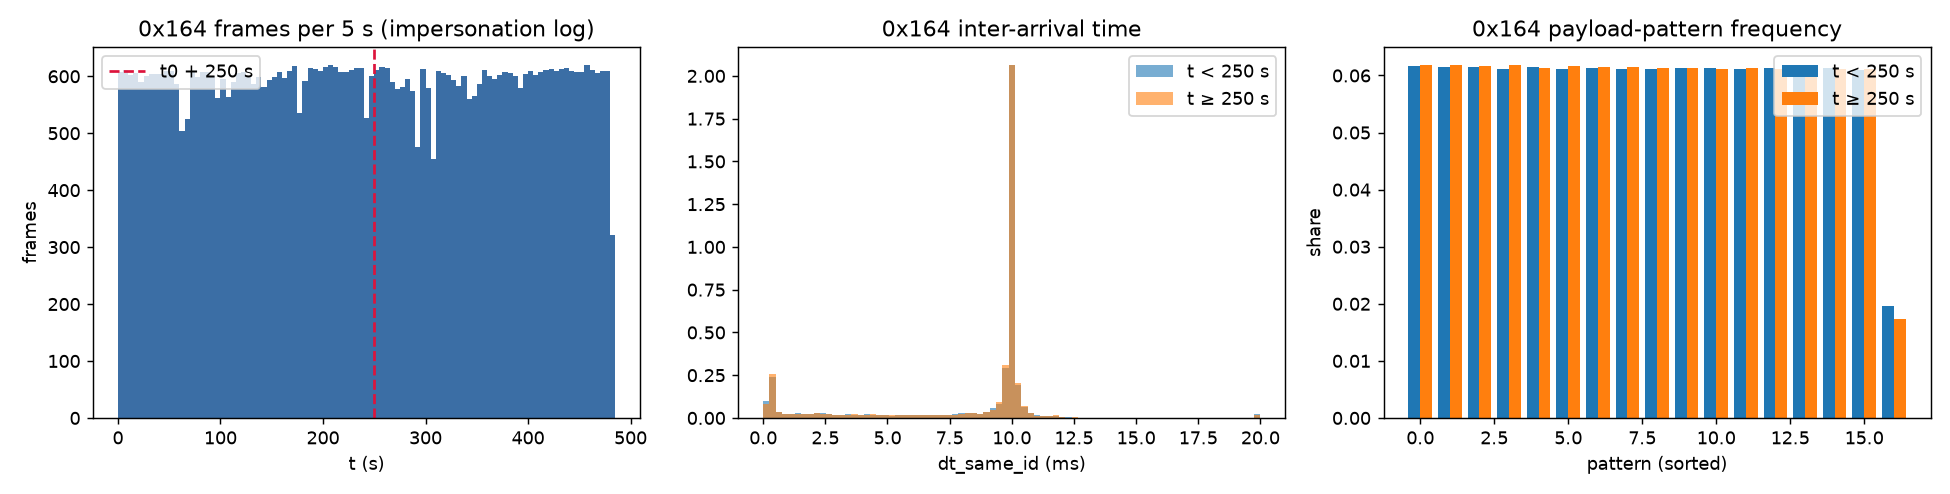

In [27]:
from IPython.display import Image, Markdown, display
if HAVE_DATA:
    sh(sys.executable, 'scripts/data_report.py')
else:
    print('No OTIDS data: showing the saved data report.')
display(Markdown((ROOT / 'results/data_report.md').read_text().split('### Per-ID rates')[0]))
display(Image(str(ROOT / 'results/figures/data_impersonation_0x164.png'), width=900))

## 11. Demo experiment (one seed)

All 15 model rows on the main benchmark (Setting A-noID, multiclass, seed 0) under the shared protocol. Results go to a separate file under the `demo` tag, so the saved 5-seed results are untouched; they should match the seed-0 rows of the full study exactly. Takes about 1 minute.

In [28]:
import pandas as pd
demo_csv = ROOT / 'results/notebook_demo.csv'
if HAVE_DATA:
    demo_csv.unlink(missing_ok=True)
    sh(sys.executable, 'scripts/run_all.py', '--setting', 'A-noID', '--task', 'multi', '--seed-list', '0',
       '--tag', 'demo', '--out', demo_csv)
else:
    print('No OTIDS data: demo skipped.')

== setting=A-noID task=multi seed=0 variant=demo (train [1198, 783, 14019], test [299, 196, 3505])
    tuned MLP: {'hidden': [64, 32], 'lr': 0.001, 'max_epochs': 50} (val macro-F1 0.9716)
  MLP                macroF1=0.9849 acc=0.9935 F1_DoS=0.9583 rules=nan train=5.3s [14s]
    tuned FCM-clf: {'k': 30, 'm': 2.0} (val macro-F1 0.8810)
  FCM-clf            macroF1=0.8996 acc=0.9698 F1_DoS=0.9385 rules=30 train=6.8s [17s]
  LDA                macroF1=0.6887 acc=0.8277 F1_DoS=0.7989 rules=nan train=0.0s [0s]
    tuned LR: {'C': 10} (val macro-F1 0.7801)
  LR                 macroF1=0.8565 acc=0.9470 F1_DoS=0.8717 rules=nan train=0.6s [2s]
    tuned LinSVM: {'C': 10} (val macro-F1 0.9177)
  LinSVM             macroF1=0.9242 acc=0.9718 F1_DoS=0.8580 rules=nan train=0.4s [1s]
    tuned RBF-SVM: {'C': 10} (val macro-F1 0.9235)
  RBF-SVM            macroF1=0.9623 acc=0.9885 F1_DoS=0.9691 rules=nan train=3.4s [10s]
    tuned RF: {'n_estimators': 200, 'max_depth': None} (val macro-F1 0.9889)
  R

In [29]:
if demo_csv.exists():
    demo = pd.read_csv(demo_csv)
    demo = demo[demo.metric != 'params'].astype({'value': float})
    display(demo.pivot_table(index='model', columns='metric', values='value')
            [['macro_f1', 'accuracy', 'f1_DoS', 'f1_Imp', 'f1_Normal', 'n_rules', 'train_time_s']]
            .sort_values('macro_f1', ascending=False).round(4))

metric,macro_f1,accuracy,f1_DoS,f1_Imp,f1_Normal,n_rules,train_time_s
model,,,,,,,
ANFIS-FCM+stk,0.9900,0.9958,0.9724,1.0000,0.9976,40.0,10.9802
ANFIS-KMeans+stk,0.9900,0.9958,0.9724,1.0000,0.9976,40.0,1.7394
ANFIS-SC+stk,0.9894,0.9955,0.9708,1.0000,0.9974,65.0,3.8247
RF,0.9876,0.9948,0.9659,1.0000,0.9970,NaN,0.9407
MLP,0.9849,0.9935,0.9583,1.0000,0.9963,NaN,5.3141
ANFIS-SC,0.9843,0.9932,0.9568,1.0000,0.9961,52.0,3.3412
ANFIS-Random+stk,0.9695,0.9898,0.9708,0.9435,0.9941,40.0,2.5216
RBF-SVM,0.9623,0.9885,0.9691,0.9238,0.9940,NaN,3.4343
ANFIS-KMeans,0.9617,0.9825,0.8952,1.0000,0.9899,30.0,1.3143


## 12. Full study (5 seeds, all settings, ablations)

These are the exact commands behind every reported number. With `RUN_FULL = False` the saved `results/metrics_long.csv` is used instead.

In [30]:
FULL = [
    '--setting A A-noID B B-ID --task binary multi --seeds 5',
    '--setting A A-noID B --task binary multi --models ANFIS-Random ANFIS-KMeans ANFIS-SC ANFIS-FCM --epochs 5 --tag ep5',
    '--setting A A-noID --task binary multi --models ANFIS-SC ANFIS-FCM ANFIS-KMeans --stack-mode oof --tag oof',
    '--setting A-noID --task binary multi --no-smote --tag nosmote',
    '--setting A-noID --task binary multi --models ANFIS-Random ANFIS-KMeans ANFIS-FCM --n-rules 20 --tag R20',
]
if RUN_FULL and HAVE_DATA:
    for args in FULL:
        sh(sys.executable, 'scripts/run_all.py', *args.split())
    sh(sys.executable, 'scripts/rule_sweep.py')
    sh(sys.executable, 'scripts/probe_B.py')
else:
    print('Using the saved results/metrics_long.csv (set RUN_FULL = True in the setup cell to re-run;'
          ' needs the OTIDS data).')

Using the saved results/metrics_long.csv (set RUN_FULL = True in the setup cell to re-run; needs the OTIDS data).


### 12.1 Generate tables, comparisons and figures

In [31]:
if HAVE_DATA:
    sh(sys.executable, '-m', 'src.eval.report')
else:
    print('No OTIDS data: using the saved tables and figures (the report step re-reads the logs '
          'for one reference baseline).')

report written to /home/sammj/scn/results


### 12.2 Main benchmark (A-noID): all models, mean ± std over 5 seeds

In [32]:
m = pd.read_csv(ROOT / 'results/metrics_long.csv')
m = m[m.metric != 'params'].astype({'value': float})

def summary(setting, task, metrics=('macro_f1', 'accuracy')):
    s = m.query('setting == @setting and task == @task and variant == "main"')
    g = s[s.metric.isin(metrics)].groupby(['model', 'metric']).value.agg(['mean', 'std']).unstack()
    g.columns = [f'{a}_{b}' for b, a in g.columns]
    return g.sort_values(g.columns[0], ascending=False).round(4)

summary('A-noID', 'multi', ('macro_f1', 'f1_Imp', 'f1_DoS'))

,f1_DoS_mean,f1_Imp_mean,macro_f1_mean,f1_DoS_std,f1_Imp_std,macro_f1_std
model,,,,,,
ANFIS-SC+stk,0.9713,0.9900,0.9861,0.0083,0.0116,0.0035
ANFIS-KMeans+stk,0.9700,0.9939,0.9871,0.0070,0.0058,0.0031
ANFIS-FCM+stk,0.9694,0.9881,0.9847,0.0095,0.0156,0.0084
RF,0.9686,1.0000,0.9886,0.0082,0.0000,0.0030
ANFIS-Random+stk,0.9652,0.9386,0.9659,0.0069,0.0217,0.0093
ANFIS-SC,0.9548,0.9990,0.9832,0.0054,0.0014,0.0019
MLP,0.9544,0.9969,0.9824,0.0044,0.0033,0.0016
RBF-SVM,0.9268,0.9144,0.9441,0.0430,0.0117,0.0189
ANFIS-KMeans,0.8905,0.9995,0.9598,0.0139,0.0011,0.0055


In [33]:
summary('A-noID', 'binary', ('macro_f1', 'f1_Attack'))

,f1_Attack_mean,macro_f1_mean,f1_Attack_std,macro_f1_std
model,,,,
RF,0.9817,0.9895,0.0052,0.0030
ANFIS-SC,0.9720,0.9840,0.0042,0.0024
ANFIS-SC+stk,0.9718,0.9838,0.0040,0.0023
ANFIS-KMeans+stk,0.9648,0.9798,0.0070,0.0040
ANFIS-FCM+stk,0.9639,0.9794,0.0054,0.0031
ANFIS-Random+stk,0.9501,0.9713,0.0273,0.0158
MLP,0.9317,0.9606,0.0292,0.0170
ANFIS-Random,0.9252,0.9568,0.0258,0.0151
ANFIS-KMeans,0.9233,0.9557,0.0254,0.0147


### 12.3 Comparison 1: non-hybrid vs hybrid

# Comparison 1: non-hybrid vs hybrid (Setting A-noID, multi)

Non-hybrid: MLP (pure neural), FCM-clf (pure fuzzy, no learning), LDA/LR/LinSVM/RBF-SVM/RF (classical). Hybrid: ANFIS-FCM, the paper's best model, unstacked and stacked (pre-specified, `ANFIS-FCM+stk` is the headline hybrid). The best of all 8 ANFIS rows is added when different, flagged as post-hoc (chosen on the test set).

| model | type | macro-F1 | F1 Imp | accuracy | train s |
|---|---|---|---|---|---|
| MLP | non-hybrid | 0.9824 ± 0.0016 | 0.9969 ± 0.0033 | 0.9927 ± 0.0006 | 4.80 |
| FCM-clf | non-hybrid | 0.8838 ± 0.0137 | 0.7967 ± 0.0364 | 0.9643 ± 0.0040 | 6.60 |
| LDA | non-hybrid | 0.6815 ± 0.0085 | 0.3667 ± 0.0102 | 0.8278 ± 0.0055 | 0.03 |
| LR | non-hybrid | 0.8621 ± 0.0223 | 0.7577 ± 0.0547 | 0.9496 ± 0.0094 | 0.60 |
| LinSVM | non-hybrid | 0.9214 ± 0.0056 | 0.9315 ± 0.0056 | 0.9704 ± 0.0028 | 0.32 |
| RBF-SVM | non-hybrid | 0.9441 ± 0.0189 | 0.9144 ± 0.0117 | 0.9819 ± 0.0077 | 3.30 |
| RF | non-hybrid | 0.9886 ± 0.0030 | 1.0000 ± 0.0000 | 0.9952 ± 0.0013 | 0.76 |
| ANFIS-FCM | hybrid | 0.9525 ± 0.0059 | 0.9985 ± 0.0034 | 0.9779 ± 0.0033 | 8.85 |
| ANFIS-FCM+stk | hybrid | 0.9847 ± 0.0084 | 0.9881 ± 0.0156 | 0.9941 ± 0.0030 | 10.79 |
| ANFIS-KMeans+stk (best ANFIS, post-hoc) | hybrid | 0.9871 ± 0.0031 | 0.9939 ± 0.0058 | 0.9950 ± 0.0013 | 1.83 |

## Paired differences (macro-F1, per seed, same test sets)

- best non-hybrid vs paper hybrid (RF → ANFIS-FCM+stk): -0.0039 ± 0.0063 (hybrid wins 1/5 seeds, ties 0) → **within noise**
- best non-hybrid vs best ANFIS (post-hoc) (RF → ANFIS-KMeans+stk): -0.0016 ± 0.0028 (hybrid wins 2/5 seeds, ties 0) → **within noise**
- pure neural (MLP) vs paper hybrid (MLP → ANFIS-FCM+stk): +0.0023 ± 0.0078 (hybrid wins 4/5 seeds, ties 0) → **within noise**
- pure fuzzy (FCM-clf) vs paper hybrid (FCM-clf → ANFIS-FCM+stk): +0.1009 ± 0.0179 (hybrid wins 5/5 seeds, ties 0) → **hybrid better**

## McNemar test (seed 0)

- RF vs ANFIS-FCM+stk: only RF correct = 0, only ANFIS-FCM+stk correct = 4, exact p = 0.125
- RF vs ANFIS-KMeans+stk: only RF correct = 0, only ANFIS-KMeans+stk correct = 4, exact p = 0.125

Figure: `figures/comparison1_A-noID_multi.png`


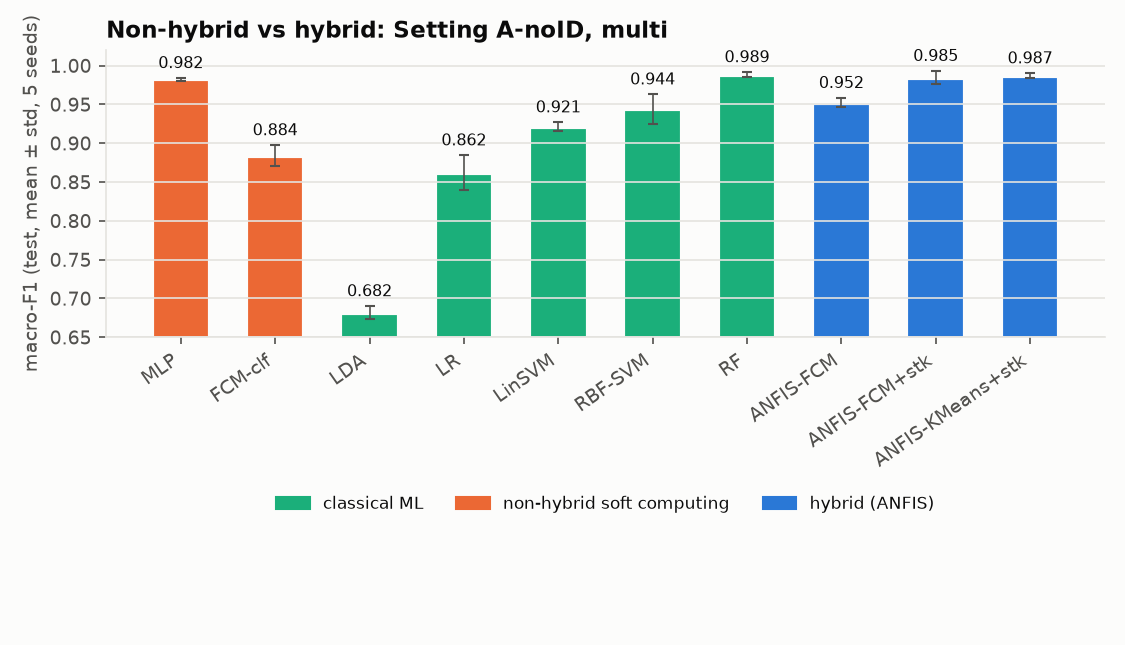

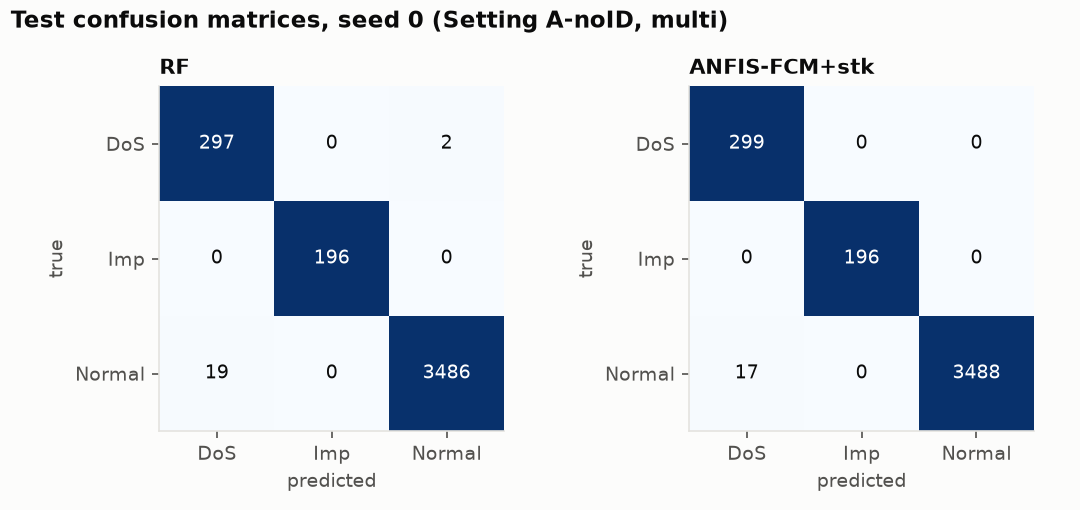

In [34]:
display(Markdown((ROOT / 'results/comparison1_nonhybrid_vs_hybrid_A-noID_multi.md').read_text()))
display(Image(str(ROOT / 'results/figures/comparison1_A-noID_multi.png'), width=800))
display(Image(str(ROOT / 'results/figures/confusion_A-noID_multi.png'), width=650))

### 12.4 Comparison 2: clustering initialisation

# Comparison 2: clustering init for ANFIS (Setting A-noID, multi)

Everything except the initial FIS is held fixed: same data, scaling, SMOTE, hybrid training (1 epoch unless noted), OvR and stacking configuration. Random and KMeans and FCM use R = 10 rules per member; SC sets its own rule count (paper radius/squash). Rules are summed over all OvR members (and the stacking ANFIS for `+stk`).

| init | macro-F1 (OvR) | macro-F1 (+stk) | F1 Imp (OvR) | F1 Imp (+stk) | rules (OvR / +stk) | train s (OvR / +stk) | macro-F1 5 ep (OvR) | macro-F1 5 ep (+stk) |
|---|---|---|---|---|---|---|---|---|
| ANFIS-Random | 0.9463 ± 0.0122 | 0.9659 ± 0.0093 | 0.9788 ± 0.0170 | 0.9386 ± 0.0217 | 30.0 / 40.0 | 0.8 / 1.0 | 0.9475 ± 0.0110 | 0.9665 ± 0.0102 |
| ANFIS-KMeans | 0.9598 ± 0.0055 | 0.9871 ± 0.0031 | 0.9995 ± 0.0011 | 0.9939 ± 0.0058 | 30.0 / 40.0 | 1.4 / 1.8 | 0.9523 ± 0.0163 | 0.9867 ± 0.0026 |
| ANFIS-SC | 0.9832 ± 0.0019 | 0.9861 ± 0.0035 | 0.9990 ± 0.0014 | 0.9900 ± 0.0116 | 49.6 / 63.0 | 2.0 / 2.5 | 0.9833 ± 0.0019 | 0.9858 ± 0.0030 |
| ANFIS-FCM | 0.9525 ± 0.0059 | 0.9847 ± 0.0084 | 0.9985 ± 0.0034 | 0.9881 ± 0.0156 | 30.0 / 40.0 | 8.9 / 10.8 | 0.9589 ± 0.0152 | 0.9861 ± 0.0031 |

## Paired differences vs the Random-init control (macro-F1, OvR)

- Random → KMeans: +0.0135 ± 0.0091 (KMeans wins 5/5 seeds, ties 0) → **KMeans better**
- Random → SC: +0.0370 ± 0.0126 (SC wins 5/5 seeds, ties 0) → **SC better**
- Random → FCM: +0.0062 ± 0.0097 (FCM wins 3/5 seeds, ties 0) → **within noise**
- KMeans → FCM (value of *fuzzy* vs hard clustering): -0.0073 ± 0.0034 (FCM wins 0/5 seeds, ties 0) → **FCM worse**

## 1 vs 5 epochs (5 = early stopping on a validation split, then refit)

- ANFIS-Random: 5 ep − 1 ep = +0.0012 ± 0.0015
- ANFIS-KMeans: 5 ep − 1 ep = -0.0075 ± 0.0208
- ANFIS-SC: 5 ep − 1 ep = +0.0001 ± 0.0003
- ANFIS-FCM: 5 ep − 1 ep = +0.0065 ± 0.0140

## ANFIS-KMeans rule count R ∈ {5, 10, 20} (validation split, 5 seeds; R = 10 stays fixed in the main tables)

| rules per member | val macro-F1 (OvR) | val macro-F1 (+stk) | train s (OvR) | train s (+stk) |
|---|---|---|---|---|
| R = 5 | 0.9350 ± 0.0381 | 0.9767 ± 0.0098 | 1.0 | 1.4 |
| R = 10 | 0.9609 ± 0.0033 | 0.9872 ± 0.0063 | 1.4 | 1.8 |
| R = 20 | 0.9609 ± 0.0100 | 0.9837 ± 0.0073 | 2.0 | 2.5 |

Figures: `figures/comparison2_A-noID_multi.png`, `figures/mf_overlay_A-noID_multi.png`


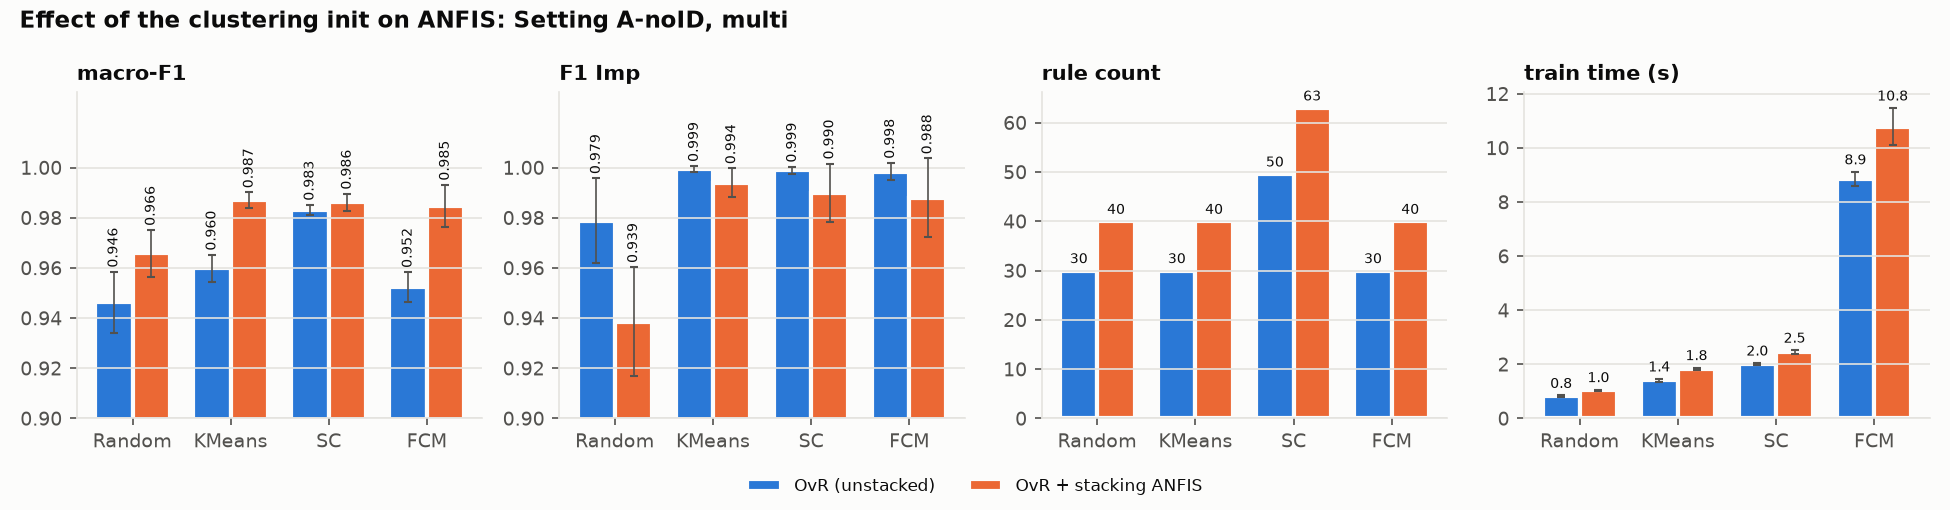

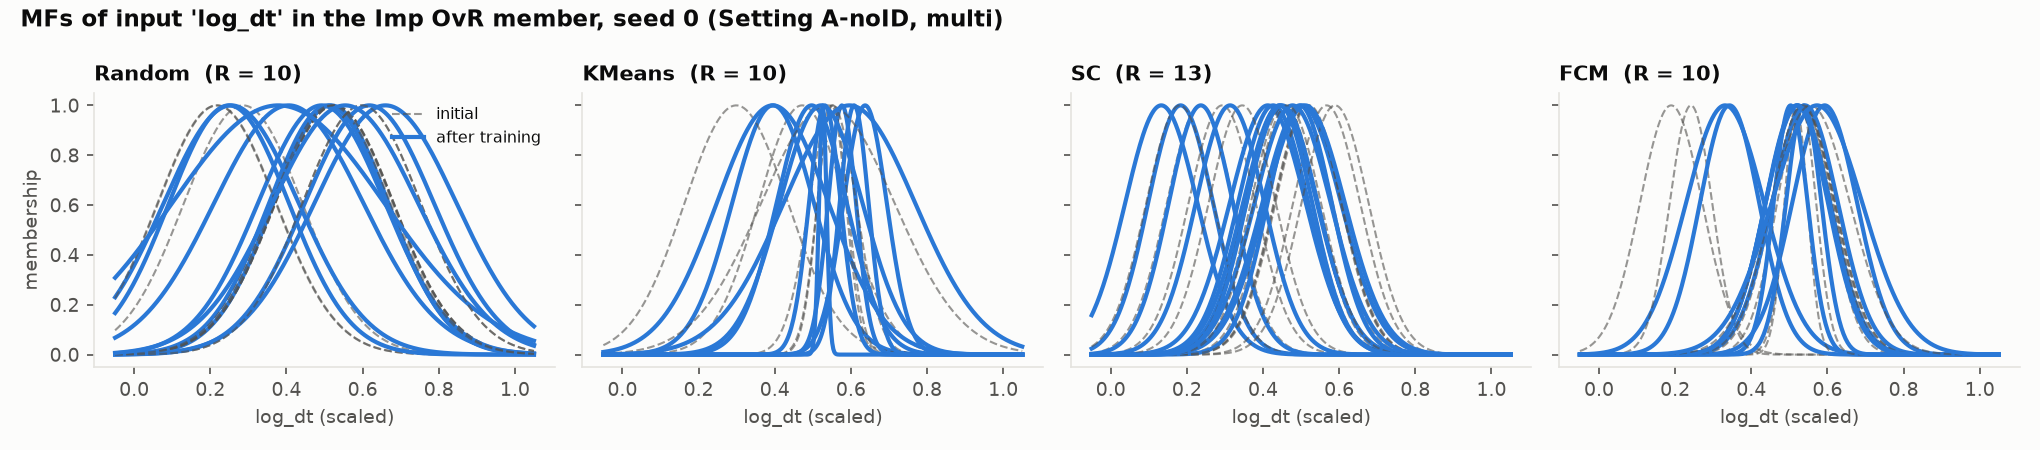

In [35]:
display(Markdown((ROOT / 'results/comparison2_clustering_A-noID_multi.md').read_text()))
display(Image(str(ROOT / 'results/figures/comparison2_A-noID_multi.png'), width=1000))
display(Image(str(ROOT / 'results/figures/mf_overlay_A-noID_multi.png'), width=1000))

### 12.5 Reproduction check (Setting A) and the model ladder across settings

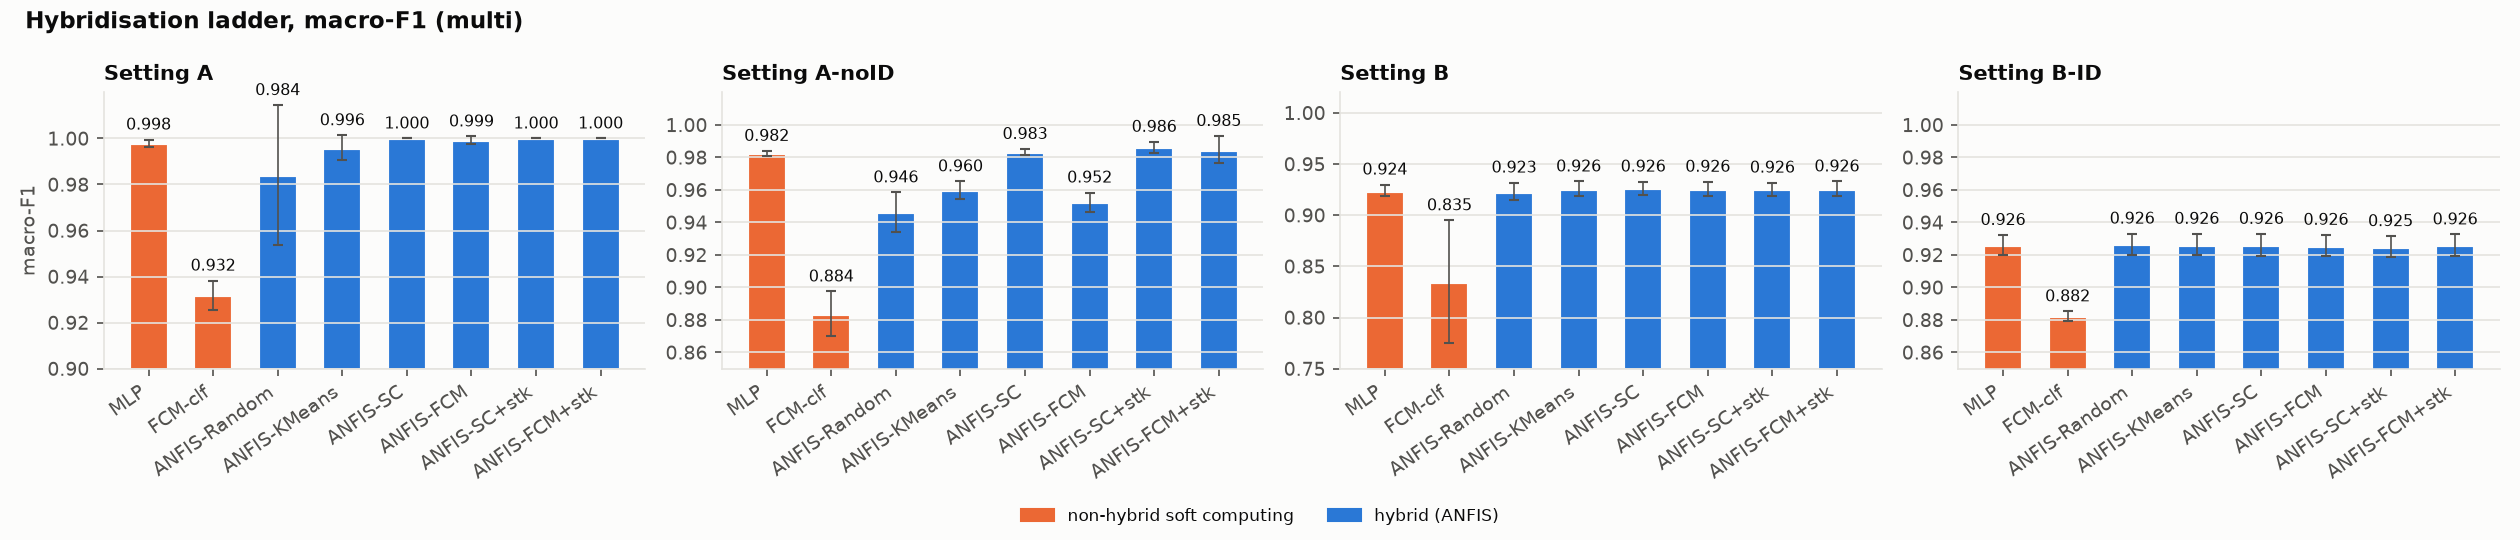

,accuracy_mean,macro_f1_mean,accuracy_std,macro_f1_std
model,,,,
ANFIS-FCM+stk,1.0000,1.0000,0.0000,0.0000
ANFIS-Random+stk,1.0000,1.0000,0.0000,0.0000
ANFIS-SC,1.0000,1.0000,0.0000,0.0000
RF,1.0000,1.0000,0.0000,0.0000
ANFIS-SC+stk,1.0000,1.0000,0.0000,0.0000
ANFIS-FCM,0.9998,0.9993,0.0004,0.0016
ANFIS-KMeans+stk,0.9996,0.9986,0.0009,0.0032
MLP,0.9992,0.9979,0.0005,0.0016
ANFIS-KMeans,0.9988,0.9959,0.0016,0.0054


In [36]:
display(Image(str(ROOT / 'results/figures/ladder_multi.png'), width=1000))
summary('A', 'multi')

## 13. Setting B: is the real Impersonation attack learnable?

In [37]:
display(Markdown((ROOT / 'results/probe_B.md').read_text()))
summary('B', 'multi', ('macro_f1', 'f1_Imp'))

# Setting B learnability probe

Task: classify each 0x164 frame of the impersonation log as after 250 s ('Impersonation', n = 27,673) or before 250 s (genuine, n = 29,799). 5-fold CV with 10 s time blocks as groups (stratified), AUC computed per fold and averaged. Control: identical probe on attack-free 0x164 frames with a fake boundary at 250 s (n = 61,018). AUC = 0.5 means no per-frame signal.

| data | features | model | ROC AUC (mean ± std over folds) |
|---|---|---|---|
| impersonation log (real boundary) | payload+DLC | LR | 0.501 ± 0.002 |
| impersonation log (real boundary) | payload+DLC | RF | 0.500 ± 0.002 |
| impersonation log (real boundary) | payload+DLC | ANFIS-FCM | 0.500 ± 0.002 |
| attack-free log (fake boundary, control) | payload+DLC | LR | 0.500 ± 0.001 |
| attack-free log (fake boundary, control) | payload+DLC | RF | 0.501 ± 0.002 |
| attack-free log (fake boundary, control) | payload+DLC | ANFIS-FCM | 0.501 ± 0.002 |
| impersonation log (real boundary) | timing (log_dt, hamming) | LR | 0.499 ± 0.004 |
| impersonation log (real boundary) | timing (log_dt, hamming) | RF | 0.591 ± 0.013 |
| impersonation log (real boundary) | timing (log_dt, hamming) | ANFIS-FCM | 0.496 ± 0.008 |
| attack-free log (fake boundary, control) | timing (log_dt, hamming) | LR | 0.500 ± 0.002 |
| attack-free log (fake boundary, control) | timing (log_dt, hamming) | RF | 0.504 ± 0.005 |
| attack-free log (fake boundary, control) | timing (log_dt, hamming) | ANFIS-FCM | 0.498 ± 0.006 |
| impersonation log (real boundary) | all | LR | 0.502 ± 0.003 |
| impersonation log (real boundary) | all | RF | 0.605 ± 0.013 |
| impersonation log (real boundary) | all | ANFIS-FCM | 0.499 ± 0.004 |
| attack-free log (fake boundary, control) | all | LR | 0.500 ± 0.002 |
| attack-free log (fake boundary, control) | all | RF | 0.505 ± 0.008 |
| attack-free log (fake boundary, control) | all | ANFIS-FCM | 0.503 ± 0.005 |


,f1_Imp_mean,macro_f1_mean,f1_Imp_std,macro_f1_std
model,,,,
ANFIS-SC,0.7937,0.9263,0.0180,0.0065
ANFIS-KMeans,0.7932,0.9259,0.0188,0.0071
ANFIS-FCM,0.7932,0.9259,0.0185,0.0068
ANFIS-KMeans+stk,0.7924,0.9258,0.0192,0.0070
ANFIS-FCM+stk,0.7924,0.9257,0.0196,0.0072
ANFIS-SC+stk,0.7922,0.9256,0.0171,0.0063
MLP,0.7886,0.9241,0.0168,0.0058
ANFIS-Random,0.7877,0.9232,0.0232,0.0087
ANFIS-Random+stk,0.7876,0.9239,0.0205,0.0075


## 14. Conclusions

- **Setting A reproduces the paper** (ANFIS-FCM+stk 99.99 % / 100 % accuracy), but the label is a function of the CAN ID input, so almost every non-linear model hits the ceiling.
- **Q1 (A-noID):** Random Forest is the best model. The hybrid ANFIS clearly beats its pure-fuzzy ingredient (+0.036 / +0.101 macro-F1 over the FCM classifier) and is better than or equal to the MLP, with a small, interpretable rule base.
- **Q2:** a clustering initialisation beats random placement at the paper's rule count, and SC is the most reliable because it sizes the rule base itself. Differences between clustering methods depend on the rule count and largely disappear after stacking; fuzzy (FCM) does not consistently beat hard (K-Means) clustering.
- **Setting B:** genuine and impersonated 0x164 frames are indistinguishable per frame (probe AUC ≈ 0.5 on payload), so the paper's Impersonation result measures ID recognition.

Full discussion: `results/REPORT_NOTES.md` and `results/AAT_Report.docx`.